| Thông tin nhóm | Điền vào đây |
|---|---|
| Mã nhóm | NhomXX |
| Thành viên 1 (MSSV) — phần phụ trách | Nguyen Tran Thuy Chi (11251582) — … |
| Thành viên 2 (MSSV) — phần phụ trách | Phung Van Luc (11255012) — … |
| Thành viên 3 (MSSV) — phần phụ trách | Nguyen Thi Hoang Tam (11257465) — … |
| Ngày chạy lại toàn bộ lần cuối | … |

## 0 · Thiết lập

In [1]:
# 0.1 CÔNG CỤ HỖ TRỢ — KHÔNG CẦN SỬA
from pathlib import Path
import re
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', 40)
pd.set_option('display.max_colwidth', 40)

# ---- Đường dẫn: tự tìm dữ liệu ở data/ hoặc cùng thư mục notebook (Colab) ----
CANDIDATES = [Path('data/hotel_bookings_dirty.csv'), Path('hotel_bookings_dirty.csv')]
DATA_PATH = next((p for p in CANDIDATES if p.exists()), CANDIDATES[0])
OUTPUT_DIR = Path('outputs')
for sub in ['', 'figures', 'tables']:
    (OUTPUT_DIR / sub).mkdir(parents=True, exist_ok=True)

# ---- Quy ước của đề (Mục 5) ----
SNAPSHOT_DATE = pd.Timestamp('2017-09-14')
MISSING_TOKENS = ['NULL', 'N/A', 'NA', '?', 'unknown', '-']        # so sánh không phân biệt hoa thường
HOTEL_COLORS = {'City Hotel': '#2F4858', 'Resort Hotel': '#E07A1F'}  # dùng cho MỌI hình có hotel
STATUS_COLORS = {'Check-Out': '#5B8E7D', 'Canceled': '#B81D24', 'No-Show': '#F2A541'}
FIGSIZE = (9, 5)

# ===================== BỘ KIỂM TRA ĐẦU RA (dùng chung notebook + tools) =====================
# Bộ kiểm tra chỉ xác nhận CẤU TRÚC, KHÓA, MIỀN GIÁ TRỊ và TÍNH NHẤT QUÁN theo quy ước trong đề.
# Nó KHÔNG chứa đáp án và KHÔNG chứng minh kết quả phân tích của nhóm là đúng.
import pandas as pd

HOTELS = ['City Hotel', 'Resort Hotel']
MEALS = ['BB', 'HB', 'FB', 'SC']
SEGMENTS = ['Online TA', 'Offline TA/TO', 'Groups', 'Direct', 'Corporate', 'Complementary', 'Aviation']
CHANNELS = ['TA/TO', 'Direct', 'Corporate', 'GDS']
DEPOSITS = ['No Deposit', 'Non Refund', 'Refundable']
CUSTOMERS = ['Transient', 'Transient-Party', 'Contract', 'Group']
STATUSES = ['Check-Out', 'Canceled', 'No-Show']
ROOM_TYPES = ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'K', 'L', 'P']
LEAD_GROUPS = ['0-7', '8-30', '31-90', '91-180', '181+']

ARRIVAL_MIN, ARRIVAL_MAX = pd.Timestamp('2015-07-01'), pd.Timestamp('2017-08-31')
STATUS_MIN, STATUS_MAX = pd.Timestamp('2014-10-01'), pd.Timestamp('2017-09-14')
LEAD_MIN, LEAD_MAX = 0, 800
WEEKEND_MAX, WEEK_MAX = 20, 50
GUEST_MAX = 10
ADR_MIN, ADR_MAX = 0, 1000
REQ_MAX = 5
N_RAW_ROWS = 10325

CLEAN_REQUIRED = ['booking_id', 'hotel', 'is_canceled', 'lead_time', 'arrival_date', 'stays_in_weekend_nights',
                  'stays_in_week_nights', 'adults', 'children', 'babies', 'meal', 'country', 'market_segment',
                  'distribution_channel', 'is_repeated_guest', 'reserved_room_type', 'assigned_room_type',
                  'deposit_type', 'customer_type', 'adr', 'total_of_special_requests', 'reservation_status',
                  'reservation_status_date',
                  'arrival_year', 'arrival_month', 'total_nights', 'total_guests', 'lead_time_group',
                  'room_changed_flag', 'revenue_est']
SUMMARY_COLUMNS = ['hotel', 'arrival_year', 'arrival_month', 'n_bookings', 'n_canceled',
                   'cancel_rate_pct', 'room_nights']
LOG_COLUMNS = ['step', 'field', 'issue', 'detection_rule', 'action', 'affected_rows',
               'changed_cells', 'removed_rows', 'example_row_ids', 'reason', 'check_after']
LINEAGE_COLUMNS = ['row_id', 'booking_id', 'status']
LINEAGE_STATUS = ['kept', 'merged', 'dropped']
QUALITY_COLUMNS = ['column', 'stage', 'denominator_rows', 'missing_count', 'invalid_count', 'missing_pct']

CORE_FILES = ['bookings_clean.csv', 'monthly_summary.csv', 'cleaning_log.csv', 'row_lineage.csv',
              'quality_report.csv']
FIGURE_FILES = ['fig01_hotel_cancel.png', 'fig02_monthly_arrivals_2016.png', 'fig03_leadtime_cancel.png',
                'fig04_top10_country.png', 'fig05_segment_cancel.png', 'fig06_deposit_cancel.png',
                'fig07_adr_hist.png', 'fig08_stay_nights.png']
TABLE_FILES = ['a_missing_survey.csv', 'a_issue_catalog.csv', 'q01_before_after.csv',
               'q02_hotel_cancel.csv', 'q03_monthly_arrivals_2016.csv', 'q04_leadtime_stats.csv',
               'q04_leadtime_cancel.csv', 'q05_top10_country.csv', 'q06_segment_cancel.csv',
               'q07_deposit_cancel.csv', 'q08_adr_stats_by_hotel.csv', 'q09_stay_nights.csv',
               'q10_room_change_by_hotel.csv', 'q10_room_change_by_reserved_type.csv']


def _blank(s):
    """True khi ô thiếu: NaN/None/NA hoặc chuỗi rỗng sau khi bỏ khoảng trắng."""
    return s.isna() | s.astype('string').str.strip().fillna('').eq('')


def _num(s):
    return pd.to_numeric(s.where(~_blank(s)), errors='coerce')


def _int_ok(s, lo, hi):
    """Ô có dữ liệu phải là số nguyên trong [lo, hi]. Trả về (đạt?, số ô sai)."""
    present = ~_blank(s)
    v = _num(s)
    bad = present & (v.isna() | (v % 1 != 0) | (v < lo) | (v > hi))
    return int(bad.sum()) == 0, int(bad.sum())


def _bool(s):
    m = {'true': True, 'false': False, '1': True, '0': False, '1.0': True, '0.0': False}
    return s.astype('string').str.strip().str.lower().map(m)


def _date(s):
    txt = s.astype('string').str.strip()
    return pd.to_datetime(txt.where(~_blank(s)), format='%Y-%m-%d', errors='coerce')


def _cat_ok(s, allowed, allow_missing=True):
    present = ~_blank(s)
    bad = sorted(set(s[present].astype(str)) - set(allowed))
    miss = int((~present).sum())
    ok = not bad and (allow_missing or miss == 0)
    return ok, ('Nhãn lạ: ' + ', '.join(bad[:6]) if bad else '') + ('' if allow_missing or miss == 0 else f' {miss} ô thiếu')


def validate_outputs(clean, monthly, row_lineage, cleaning_log, quality_report, raw_row_ids=None):
    """Chạy toàn bộ kiểm tra. Trả về DataFrame: nhom, kiem_tra, ket_qua, chi_tiet."""
    res = []

    def add(group, name, ok, detail=''):
        res.append({'nhom': group, 'kiem_tra': name,
                    'ket_qua': 'ĐẠT' if ok else 'CHƯA ĐẠT', 'chi_tiet': detail})

    def safe(group, name, fn):
        try:
            ok, detail = fn()
        except Exception as e:  # thiếu cột, sai kiểu... -> báo lỗi thân thiện
            ok, detail = False, f'Lỗi khi kiểm tra: {type(e).__name__}: {e}'
        add(group, name, ok, detail)

    frames = {'bookings_clean': clean, 'monthly_summary': monthly, 'row_lineage': row_lineage,
              'cleaning_log': cleaning_log, 'quality_report': quality_report}
    for k, v in frames.items():
        add('0 Tồn tại', f'{k} đã được tạo', v is not None and len(v) > 0,
            '' if v is not None else 'Biến/tệp còn trống (None).')

    # ---------------- Bảng chính: khóa và nhãn ----------------
    if clean is not None:
        c = clean
        G = '1 Khóa & nhãn'
        safe(G, 'Đủ các cột bắt buộc',
             lambda: (not (miss := [x for x in CLEAN_REQUIRED if x not in c.columns]),
                      'Thiếu: ' + ', '.join(miss) if miss else f'{len(c.columns)} cột'))
        safe(G, 'booking_id không thiếu, dạng BK + 6 chữ số',
             lambda: ((n := int((_blank(c['booking_id']) | ~c['booking_id'].astype('string').str.fullmatch(r'BK\d{6}').fillna(False)).sum())) == 0,
                      f'{n} ô thiếu hoặc sai dạng'))
        safe(G, 'booking_id không trùng (1 dòng / đặt phòng)',
             lambda: ((n := int(c['booking_id'].duplicated().sum())) == 0, f'{n} booking_id lặp'))
        safe(G, 'hotel chỉ gồm City Hotel, Resort Hotel (không thiếu)', lambda: _cat_ok(c['hotel'], HOTELS, False))
        for col, allowed in [('meal', MEALS), ('market_segment', SEGMENTS), ('distribution_channel', CHANNELS),
                             ('deposit_type', DEPOSITS), ('customer_type', CUSTOMERS), ('reservation_status', STATUSES),
                             ('reserved_room_type', ROOM_TYPES), ('assigned_room_type', ROOM_TYPES)]:
            safe(G, f'{col} thuộc tập nhãn hợp lệ hoặc thiếu', lambda col=col, allowed=allowed: _cat_ok(c[col], allowed))
        safe(G, 'country là mã 2–3 chữ in hoa hoặc thiếu',
             lambda: ((n := int((~_blank(c['country']) & ~c['country'].astype('string').str.fullmatch(r'[A-Z]{2,3}').fillna(False)).sum())) == 0,
                      f'{n} ô sai dạng'))
        safe(G, 'is_canceled, is_repeated_guest chỉ là 0/1 hoặc thiếu',
             lambda: ((a := _int_ok(c['is_canceled'], 0, 1))[0] and (b := _int_ok(c['is_repeated_guest'], 0, 1))[0],
                      f'is_canceled sai: {a[1]}; is_repeated_guest sai: {b[1]}'))

        # ---------------- Số đo và ngày ----------------
        G = '2 Số & ngày'
        for col, lo, hi in [('lead_time', LEAD_MIN, LEAD_MAX), ('stays_in_weekend_nights', 0, WEEKEND_MAX),
                            ('stays_in_week_nights', 0, WEEK_MAX), ('adults', 0, GUEST_MAX), ('children', 0, GUEST_MAX),
                            ('babies', 0, GUEST_MAX), ('total_of_special_requests', 0, REQ_MAX)]:
            safe(G, f'{col} nguyên trong {lo}–{hi}', lambda col=col, lo=lo, hi=hi: ((r := _int_ok(c[col], lo, hi))[0], f'{r[1]} ô sai'))

        def _adr():
            present = ~_blank(c['adr'])
            v = _num(c['adr'])
            bad = present & (v.isna() | (v < ADR_MIN) | (v > ADR_MAX))
            return int(bad.sum()) == 0, f'{int(bad.sum())} ô không phải số trong 0–1000'
        safe(G, 'adr là số (EUR) trong 0–1000 hoặc thiếu', _adr)

        def _dates(col, lo, hi):
            s = c[col]
            present = ~_blank(s)
            fmt_bad = present & ~s.astype('string').str.strip().str.fullmatch(r'\d{4}-\d{2}-\d{2}').fillna(False)
            d = _date(s)
            rng_bad = present & (d.isna() | (d < lo) | (d > hi))
            n = int((fmt_bad | rng_bad).sum())
            return n == 0, f'{n} ô sai định dạng YYYY-MM-DD hoặc ngoài {lo:%Y-%m-%d}..{hi:%Y-%m-%d}'
        safe(G, 'arrival_date dạng YYYY-MM-DD, trong 2015-07-01..2017-08-31',
             lambda: _dates('arrival_date', ARRIVAL_MIN, ARRIVAL_MAX))
        safe(G, 'reservation_status_date dạng YYYY-MM-DD, trong 2014-10-01..2017-09-14',
             lambda: _dates('reservation_status_date', STATUS_MIN, STATUS_MAX))

        def _cons():
            st = c['reservation_status'].astype('string')
            ic = _num(c['is_canceled'])
            exp = st.map({'Check-Out': 0, 'Canceled': 1, 'No-Show': 1})
            bad = exp.notna() & (ic.astype('Float64') != exp.astype('Float64')).fillna(True)
            return int(bad.sum()) == 0, f'{int(bad.sum())} dòng is_canceled mâu thuẫn reservation_status'
        safe(G, 'is_canceled nhất quán với reservation_status', _cons)

        # ---------------- Cột dẫn xuất ----------------
        G = '3 Cột dẫn xuất'

        def _ym():
            d = _date(c['arrival_date'])
            bad = (d.dt.year.astype('Float64').fillna(-1) != _num(c['arrival_year']).fillna(-1)) | \
                  (d.dt.month.astype('Float64').fillna(-1) != _num(c['arrival_month']).fillna(-1))
            return int(bad.sum()) == 0, f'{int(bad.sum())} dòng không khớp arrival_date'
        safe(G, 'arrival_year, arrival_month lấy từ arrival_date', _ym)

        def _sum(target, parts):
            exp = sum(_num(c[p]) for p in parts)
            bad = exp.fillna(-999) != _num(c[target]).fillna(-999)
            return int(bad.sum()) == 0, f'{int(bad.sum())} dòng sai (thiếu một thành phần → kết quả thiếu)'
        safe(G, 'total_nights = weekend + week nights', lambda: _sum('total_nights', ['stays_in_weekend_nights', 'stays_in_week_nights']))
        safe(G, 'total_guests = adults + children + babies', lambda: _sum('total_guests', ['adults', 'children', 'babies']))

        def _lead():
            lt = _num(c['lead_time'])
            exp = pd.cut(lt, bins=[-0.5, 7.5, 30.5, 90.5, 180.5, float('inf')], labels=LEAD_GROUPS).astype('string')
            got = c['lead_time_group'].astype('string').where(~_blank(c['lead_time_group']))
            bad = exp.fillna('∅') != got.fillna('∅')
            return int(bad.sum()) == 0, f'{int(bad.sum())} dòng sai nhóm (nhãn: {", ".join(LEAD_GROUPS)})'
        safe(G, 'lead_time_group đúng 5 nhóm quy ước', _lead)

        def _room():
            r, a = c['reserved_room_type'], c['assigned_room_type']
            exp = (~_blank(r) & ~_blank(a) & (r.astype('string') != a.astype('string'))).fillna(False)
            got = _bool(c['room_changed_flag'])
            bad = got.isna() | (got.astype('boolean') != exp.astype('boolean'))
            return int(bad.sum()) == 0, f'{int(bad.sum())} dòng sai hoặc thiếu cờ (chỉ dùng True/False)'
        safe(G, 'room_changed_flag đúng quy tắc', _room)

        def _rev():
            adr, n, ic = _num(c['adr']), _num(c['total_nights']), _num(c['is_canceled'])
            exp = (adr * n).where(ic == 0).round(2)
            got = _num(c['revenue_est']).round(2)
            same = (exp.isna() & got.isna()) | ((exp - got).abs() <= 0.011).fillna(False)
            bad = ~same
            return int(bad.sum()) == 0, f'{int(bad.sum())} dòng sai (chỉ tính khi is_canceled = 0 và adr, total_nights hợp lệ)'
        safe(G, 'revenue_est = adr × total_nights (chỉ đặt phòng không hủy)', _rev)

    # ---------------- Bảng tổng hợp theo tháng ----------------
    if monthly is not None:
        m = monthly
        G = '4 Bảng tháng'
        safe(G, 'monthly_summary đúng 7 cột',
             lambda: (list(m.columns) == SUMMARY_COLUMNS, f'Cột hiện có: {list(m.columns)}'))
        safe(G, 'Không trùng khóa (hotel, arrival_year, arrival_month)',
             lambda: ((n := int(m.duplicated(['hotel', 'arrival_year', 'arrival_month']).sum())) == 0, f'{n} khóa lặp'))
        if clean is not None:
            def _recompute():
                c = clean.copy()
                c['_y'], c['_m'] = _num(c['arrival_year']), _num(c['arrival_month'])
                c['_ic'], c['_n'] = _num(c['is_canceled']), _num(c['total_nights'])
                c = c[c['_y'].notna()]
                g = c.groupby([c['hotel'].astype(str), '_y', '_m'])
                exp = pd.DataFrame({'n_bookings': g.size(), 'n_canceled': g['_ic'].apply(lambda s: (s == 1).sum()),
                                    'known': g['_ic'].apply(lambda s: s.notna().sum()),
                                    'room_nights': g.apply(lambda x: x.loc[x['_ic'] == 0, '_n'].sum())}).reset_index()
                exp.columns = ['hotel', 'arrival_year', 'arrival_month', 'n_bookings', 'n_canceled', 'known', 'room_nights']
                exp['cancel_rate_pct'] = (exp['n_canceled'] / exp['known'] * 100).round(2)
                got = m.copy()
                for col in ['arrival_year', 'arrival_month', 'n_bookings', 'n_canceled', 'cancel_rate_pct', 'room_nights']:
                    got[col] = _num(got[col])
                got['hotel'] = got['hotel'].astype(str)
                j = exp.merge(got, on=['hotel', 'arrival_year', 'arrival_month'], how='outer', suffixes=('_e', '_g'), indicator=True)
                miss = int((j['_merge'] != 'both').sum())
                b = j[j['_merge'] == 'both']
                bad = int(((b['n_bookings_e'] != b['n_bookings_g']) | (b['n_canceled_e'] != b['n_canceled_g']) |
                           ~(((b['cancel_rate_pct_e'] - b['cancel_rate_pct_g']).abs() <= 0.011) |
                             (b['cancel_rate_pct_e'].isna() & b['cancel_rate_pct_g'].isna())) |
                           ((b['room_nights_e'] - b['room_nights_g']).abs() > 0.5)).sum())
                return miss == 0 and bad == 0, f'{miss} tháng thiếu/thừa; {bad} tháng lệch số liệu so với bảng chính'
            safe(G, 'Số liệu khớp khi tính lại từ bookings_clean', _recompute)

    # ---------------- Truy vết ----------------
    if row_lineage is not None:
        rl = row_lineage
        G = '5 Truy vết'
        safe(G, 'row_lineage có cột row_id, booking_id, status',
             lambda: (all(x in rl.columns for x in LINEAGE_COLUMNS), f'Cột hiện có: {list(rl.columns)}'))
        safe(G, 'Mỗi row_id xuất hiện đúng 1 lần',
             lambda: ((n := int(rl['row_id'].duplicated().sum())) == 0, f'{n} row_id lặp'))
        if raw_row_ids is not None:
            safe(G, f'Phủ đủ {N_RAW_ROWS} row_id gốc',
                 lambda: ((mm := len(set(raw_row_ids) - set(rl['row_id']))) == 0 and
                          (x := len(set(rl['row_id']) - set(raw_row_ids))) == 0,
                          f'Thiếu {mm} row_id gốc; thừa {x} row_id lạ'))
        safe(G, 'status thuộc kept / merged / dropped',
             lambda: (not (bad := sorted(set(rl['status'].astype(str)) - set(LINEAGE_STATUS))),
                      'Giá trị lạ: ' + ', '.join(bad[:5]) if bad else ''))
        if clean is not None:
            safe(G, 'Mỗi booking_id trong bảng chính có đúng 1 dòng kept',
                 lambda: ((k := rl.loc[rl['status'] == 'kept', 'booking_id']).is_unique and
                          set(k) == set(clean['booking_id']),
                          f'{int(k.duplicated().sum())} booking_id có >1 kept; '
                          f'{len(set(clean["booking_id"]) - set(k))} booking_id không có kept'))
            safe(G, 'Dòng kept/merged trỏ tới booking_id có trong bảng chính',
                 lambda: ((n := int((rl['status'].isin(['kept', 'merged']) &
                                     ~rl['booking_id'].isin(clean['booking_id'])).sum())) == 0, f'{n} dòng trỏ sai'))

    # ---------------- Nhật ký & chất lượng ----------------
    G = '6 Nhật ký'
    if cleaning_log is not None:
        lg = cleaning_log
        safe(G, 'cleaning_log đúng 11 cột theo mẫu',
             lambda: (list(lg.columns) == LOG_COLUMNS, f'Cột hiện có: {list(lg.columns)}'))
        safe(G, 'Có ít nhất 10 quy tắc được ghi', lambda: (len(lg) >= 10, f'{len(lg)} dòng'))
        safe(G, 'affected_rows, changed_cells, removed_rows là số nguyên ≥ 0',
             lambda: (all(_int_ok(lg[x], 0, 10**7)[0] and (~_blank(lg[x])).all()
                          for x in ['affected_rows', 'changed_cells', 'removed_rows']), ''))
        safe(G, 'Mỗi quy tắc có lý do (reason) và kiểm tra sau (check_after)',
             lambda: ((n := int((_blank(lg['reason']) | _blank(lg['check_after'])).sum())) == 0, f'{n} dòng thiếu'))
    if quality_report is not None:
        q = quality_report
        safe(G, 'quality_report có các cột bắt buộc',
             lambda: (not (mm := [x for x in QUALITY_COLUMNS if x not in q.columns]), 'Thiếu: ' + ', '.join(mm) if mm else ''))
        safe(G, 'quality_report có cả before và after',
             lambda: ({'before', 'after'} <= set(q['stage'].astype(str)), f'stage: {sorted(set(q["stage"].astype(str)))}'))

    return pd.DataFrame(res)


def print_report(report):
    n_ok = int((report['ket_qua'] == 'ĐẠT').sum())
    for _, r in report.iterrows():
        mark = '✅' if r['ket_qua'] == 'ĐẠT' else '❌'
        extra = f'  — {r["chi_tiet"]}' if r['chi_tiet'] and r['ket_qua'] != 'ĐẠT' else ''
        print(f'{mark} [{r["nhom"]}] {r["kiem_tra"]}{extra}')
    print(f'\nTỔNG KẾT: {n_ok}/{len(report)} kiểm tra đạt.')
    return n_ok == len(report)
# =============================================================================================


# ---- Hàm tiện ích ----
cleaning_log_rows = []   # mỗi phần tử là 1 dict = 1 dòng nhật ký

def example_ids(frame, mask, k=5):
    """Trả về tối đa k row_id (ngăn bằng '; ') của các dòng thỏa mask — dùng cho cột example_row_ids."""
    return '; '.join(frame.loc[mask, 'row_id'].astype(str).head(k))

def log_step(step, field, issue, detection_rule, action, affected_rows, changed_cells,
             removed_rows, example_row_ids, reason, check_after):
    """Thêm 1 dòng vào nhật ký làm sạch. Gọi lại với cùng step+field+issue sẽ GHI ĐÈ dòng cũ (an toàn khi chạy lại ô)."""
    row = dict(step=step, field=field, issue=issue, detection_rule=detection_rule, action=action,
               affected_rows=int(affected_rows), changed_cells=int(changed_cells),
               removed_rows=int(removed_rows), example_row_ids=example_row_ids,
               reason=reason, check_after=check_after)
    cleaning_log_rows[:] = [r for r in cleaning_log_rows
                            if not (r['step'] == step and r['field'] == field and r['issue'] == issue)]
    cleaning_log_rows.append(row)
    print(f'📝 Đã ghi nhật ký: [{step}] {field} — {issue} ({int(affected_rows)} dòng)')

def check(name, condition, hint=''):
    """In ✅ hoặc ❌. condition là hàm không tham số (lambda) để không báo lỗi khi biến chưa sẵn sàng."""
    try:
        ok = bool(condition())
        err = ''
    except Exception as e:
        ok, err = False, f' (chưa sẵn sàng: {type(e).__name__})'
    print(('✅ ' if ok else '❌ ') + name + ('' if ok else err + (f'\n   ↳ Gợi ý: {hint}' if hint else '')))
    return ok

def save_table(frame, name):
    """Lưu bảng nguồn vào outputs/tables/<name>.csv. Dùng đúng tên trong đề (Mục 12)."""
    if frame is None:
        print(f'⏳ Chưa có bảng {name} — bỏ qua.'); return
    if name + '.csv' not in TABLE_FILES:
        print(f'⚠️  Tên {name}.csv không có trong danh sách chuẩn: kiểm tra lại chính tả.')
    frame.to_csv(OUTPUT_DIR / 'tables' / f'{name}.csv', index=False, encoding='utf-8-sig')
    print(f'💾 outputs/tables/{name}.csv  ({len(frame)} dòng)')

def save_fig(fig, name):
    """Lưu hình PNG 150 dpi vào outputs/figures/<name>.png."""
    if name + '.png' not in FIGURE_FILES:
        print(f'⚠️  Tên {name}.png không có trong danh sách chuẩn: kiểm tra lại chính tả.')
    fig.savefig(OUTPUT_DIR / 'figures' / f'{name}.png', dpi=150, bbox_inches='tight')
    print(f'🖼️  outputs/figures/{name}.png')

def finish_chart(ax, title, xlabel, ylabel, note=None):
    """Định dạng chuẩn: tiêu đề, nhãn trục, ghi chú mẫu số/nguồn dưới hình, bỏ khung thừa."""
    ax.set_title(title, fontsize=13, fontweight='bold', loc='left')
    ax.set_xlabel(xlabel); ax.set_ylabel(ylabel)
    ax.spines[['top', 'right']].set_visible(False)
    if note:
        ax.figure.text(0.01, -0.04, note, fontsize=9, color='#555555', ha='left', va='top', wrap=True)

def show_progress():
    """Bảng tiến độ: các tệp bắt buộc đã có trong outputs/ hay chưa."""
    items = [('Dữ liệu', f, OUTPUT_DIR / f) for f in CORE_FILES] + \
            [('Bảng', f, OUTPUT_DIR / 'tables' / f) for f in TABLE_FILES] + \
            [('Hình', f, OUTPUT_DIR / 'figures' / f) for f in FIGURE_FILES]
    t = pd.DataFrame([(g, f, '✅' if p.exists() else '⬜') for g, f, p in items], columns=['Nhóm', 'Tệp', 'Có'])
    done = (t['Có'] == '✅').sum()
    print(f'Tiến độ tệp đầu ra: {done}/{len(t)} ({done / len(t):.0%})')
    return t

print('Đã nạp công cụ hỗ trợ. pandas', pd.__version__)

Đã nạp công cụ hỗ trợ. pandas 3.0.6


In [2]:
import urllib.request

FILE_ID = '10w4yPt-c3O1tpED43iDKSHYUOYLu2RAH'
LOCAL_PATH = Path('data/hotel_bookings_dirty.csv')

if not LOCAL_PATH.exists():
    LOCAL_PATH.parent.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(f'https://drive.google.com/uc?export=download&id={FILE_ID}', LOCAL_PATH)
    print('Đã tải về', LOCAL_PATH)
else:
    print('Đã có sẵn', LOCAL_PATH, '— không tải lại')

DATA_PATH = LOCAL_PATH

Đã có sẵn data/hotel_bookings_dirty.csv — không tải lại


In [3]:
# 0.2 Đọc dữ liệu: mọi cột ở dạng chuỗi để giữ giá trị gốc
if not DATA_PATH.exists():
    raise FileNotFoundError('Không thấy hotel_bookings_dirty.csv. Colab: tải tệp lên bảng Files. '
                            'Máy cá nhân: đặt tệp vào thư mục data/ hoặc sửa DATA_PATH.')
raw_df = pd.read_csv(DATA_PATH, dtype=str, keep_default_na=False, encoding='utf-8-sig')
print('Đường dẫn:', DATA_PATH, '| Kích thước:', raw_df.shape)
check('Đầu vào đúng 10.325 dòng × 24 cột', lambda: raw_df.shape == (10325, 24),
      'Bạn đang dùng sai tệp hoặc tệp đã bị sửa. Tải lại gói bài tập.')
raw_df.head()

Đường dẫn: data/hotel_bookings_dirty.csv | Kích thước: (10325, 24)
✅ Đầu vào đúng 10.325 dòng × 24 cột


,row_id,booking_id,hotel,is_canceled,lead_time,arrival_date,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,reserved_room_type,assigned_room_type,deposit_type,customer_type,adr,total_of_special_requests,reservation_status,reservation_status_date
0,R00001,BK046154,City Hotel,0,9,2015-12-18,0,1,2,0,0,SC,PRT,Online TA,TA/TO,0,A,A,No Deposit,Transient,85,1,Check-Out,2015-12-19
1,R00002,BK054785,City Hotel,1,177,2016-07-26,0,4,2,0,0,SC,ROU,Online TA,TA/TO,0,A,A,No Deposit,Transient,80.75,1,Canceled,2016-03-05
2,R00003,BK093598,City Hotel,0,174,2016-07-21,0,3,2,0,0,BB,GBR,Online TA,TA/TO,0,D,D,no deposit,Transient,115.8,2,Check-Out,2016-07-24
3,R00004,BK071930,City Hotel,1,163,2017-07-15,2,2,3,0,0,BB,DEU,Online TA,TA/TO,0,D,D,No Deposit,Transient,152.1,0,Canceled,2017-05-18
4,R00005,BK100632,City Hotel,0,1,"October 29, 2016",0,1,3,0,0,HB,BRA,Online TA,TA/TO,0,D,D,No Deposit,Transient,203.81,1,Check-Out,2016-10-30


In [4]:
# 0.3 Hàm dùng chung
# Ký hiệu thiếu, so sánh không phân biệt hoa thường
TOKENS_LOWER = {t.lower() for t in MISSING_TOKENS}   # null, n/a, na, ?, unknown, -

def is_missing_token(s):
    """True khi ô là ký hiệu thiếu (NULL, N/A, NA, ?, unknown, -)"""
    return s.astype('string').str.strip().str.lower().isin(TOKENS_LOWER).fillna(False)

def is_missing_any(s):
    """True khi ô là ký hiệu thiếu hoặc là ô trống"""
    return _blank(s) | is_missing_token(s)


# ---- Khóa so khớp nhãn (B4) ----
def norm_key(s):
    """Viết hết thành chữ thường và bỏ hết các dấu, khoảng trống ở giữa các chữ."""
    return s.astype('string').str.lower().str.replace(r'[^a-z]', '', regex=True)


# ---- Bảng thiếu theo cột ----
def missing_survey_of(frame):
    """Mỗi cột 1 dòng: column, n_rows, empty_count, token_count, missing_total, missing_pct."""
    rows = []
    for col in frame.columns:
        empty = int(_blank(frame[col]).sum())
        token = int(is_missing_token(frame[col]).sum())
        rows.append({'column': col, 'n_rows': len(frame), 'empty_count': empty, 'token_count': token,
                     'missing_total': empty + token,
                     'missing_pct': round((empty + token) / len(frame) * 100, 5)})
    return pd.DataFrame(rows)


# ---- Đếm ô thực sự đổi giá trị (changed_cells) ----
def count_changed(before, after):
    """So hai Series cùng index. Thiếu → thiếu không tính là đổi."""
    b, a = before.astype('string'), after.astype('string')
    both_na = b.isna() & a.isna()
    return int(((b != a).fillna(True) & ~both_na).sum())


# ---- Đọc ngày theo định dạng tường minh ----
DATE_FORMATS = ['%Y-%m-%d', '%d/%m/%Y', '%B %d, %Y', '%d-%b-%Y']   # '/' luôn là ngày/tháng/năm

def parse_date(s, formats, lo, hi):
    """Thử lần lượt từng format. Trả về (dates, reason).
    dates: ngày hợp lệ, còn lại NaT. reason: lý do của ô không hợp lệ, ô hợp lệ để <NA>."""
    txt = s.astype('string').str.strip().where(~is_missing_any(s))
    dates = pd.Series(pd.NaT, index=s.index, dtype='datetime64[ns]')
    for fmt in formats:
        dates = dates.fillna(pd.to_datetime(txt, format=fmt, errors='coerce'))

    reason = pd.Series(pd.NA, index=s.index, dtype='string')
    reason.loc[txt.isna()] = 'thiếu sẵn trong tệp'
    reason.loc[txt.notna() & dates.isna()] = 'sai định dạng hoặc ngày không tồn tại'
    out_of_range = dates.notna() & ~dates.between(lo, hi)
    reason.loc[out_of_range] = f'ngoài khoảng {lo:%Y-%m-%d}..{hi:%Y-%m-%d}'
    return dates.where(~out_of_range), reason

# ---- Sổ quy tắc phát hiện lỗi ----
RULES = []   # mỗi phần tử: 1 quy tắc

def add_rule(issue_id, field, issue_type, fix_step, issue, detection_rule, detect):
    """Thêm 1 quy tắc. detect là hàm nhận DataFrame, trả về Series True/False (True = dòng dính lỗi).
    Gọi lại với cùng issue_id sẽ ghi đè (an toàn khi chạy lại ô)."""
    RULES[:] = [r for r in RULES if r['issue_id'] != issue_id]
    RULES.append(dict(issue_id=issue_id, field=field, issue_type=issue_type, fix_step=fix_step,
                      issue=issue, detection_rule=detection_rule, detect=detect))

def run_rules(frame):
    """Chạy mọi quy tắc trên frame → bảng theo cột của issue_catalog (+ issue_type, fix_step)."""
    rows = []
    for r in RULES:
        mask = r['detect'](frame).fillna(False).astype(bool)
        rows.append({'issue_id': r['issue_id'], 'field': r['field'], 'issue': r['issue'],
                     'detection_rule': r['detection_rule'], 'affected_rows': int(mask.sum()),
                     'example_row_ids': example_ids(frame, mask) if 'row_id' in frame.columns else '',
                     'issue_type': r['issue_type'], 'fix_step': r['fix_step']})
    return pd.DataFrame(rows)


# ---- Tỷ lệ hủy: mẫu số = is_canceled không thiếu ----
def cancel_rate(frame, by):
    """Theo nhóm `by`: n_bookings, n_known (is_canceled không thiếu), n_canceled, cancel_rate_pct.
    Dòng có `by` thiếu bị bỏ khỏi bảng — nhớ báo cáo riêng số này."""
    g = frame.groupby(by, observed=False)['is_canceled']
    out = pd.DataFrame({'n_bookings': g.size(), 'n_known': g.count(), 'n_canceled': g.sum()})
    out['cancel_rate_pct'] = (out['n_canceled'] / out['n_known'] * 100).round(2)
    return out.reset_index()

print('Đã nạp hàm dùng chung của nhóm:', len(RULES), 'quy tắc trong sổ.')

# ---- Sổ lỗi giai đoạn A (A2–A6 cùng ghi vào) ----
ISSUES = {}   # khóa (field, issue); chạy lại thì ghi đè

FIX_STEP_BY_FIELD = {
    'booking_id': 'B1',
    'hotel': 'B4a', 'meal': 'B4a', 'market_segment': 'B4a', 'distribution_channel': 'B4a',
    'deposit_type': 'B4a', 'customer_type': 'B4a', 'reservation_status': 'B4a',
    'reserved_room_type': 'B4a', 'assigned_room_type': 'B4a',
    'is_canceled': 'B4a', 'is_repeated_guest': 'B4a',
    'arrival_date': 'B5', 'reservation_status_date': 'B5',
    'lead_time': 'B6', 'stays_in_weekend_nights': 'B6', 'stays_in_week_nights': 'B6',
    'adults': 'B6', 'children': 'B6', 'babies': 'B6', 'total_of_special_requests': 'B6', 'adr': 'B6',
    'country': 'B7',
}

def record_issue(field, issue, mask, rule, issue_type, fix_step=None):
    """Ghi 1 nhóm lỗi vào ISSUES. Bỏ qua nếu 0 dòng. fix_step bỏ trống → tra theo FIX_STEP_BY_FIELD."""
    mask = mask.fillna(False).astype(bool)
    if mask.sum() == 0:
        ISSUES.pop((field, issue), None)
        return
    ISSUES[(field, issue)] = {
        'field': field, 'issue': issue, 'detection_rule': rule,
        'affected_rows': int(mask.sum()), 'example_row_ids': example_ids(raw_df, mask),
        'issue_type': issue_type, 'fix_step': fix_step or FIX_STEP_BY_FIELD.get(field, ''),
    }

Đã nạp hàm dùng chung của nhóm: 0 quy tắc trong sổ.


In [5]:
# Colab: bỏ chú thích 2 dòng dưới nếu đọc dữ liệu từ Drive
# from google.colab import drive; drive.mount('/content/drive')

---
# GIAI ĐOẠN A · KHẢO SÁT TRƯỚC KHI SỬA

## A · Khảo sát dữ liệu

## A1 · Tổng quan

In [6]:
raw_df.shape

(10325, 24)

In [7]:
list(raw_df.columns)

['row_id',
 'booking_id',
 'hotel',
 'is_canceled',
 'lead_time',
 'arrival_date',
 'stays_in_weekend_nights',
 'stays_in_week_nights',
 'adults',
 'children',
 'babies',
 'meal',
 'country',
 'market_segment',
 'distribution_channel',
 'is_repeated_guest',
 'reserved_room_type',
 'assigned_room_type',
 'deposit_type',
 'customer_type',
 'adr',
 'total_of_special_requests',
 'reservation_status',
 'reservation_status_date']

In [8]:
print(str(raw_df.dtypes))

row_id                       str
booking_id                   str
hotel                        str
is_canceled                  str
lead_time                    str
arrival_date                 str
stays_in_weekend_nights      str
stays_in_week_nights         str
adults                       str
children                     str
babies                       str
meal                         str
country                      str
market_segment               str
distribution_channel         str
is_repeated_guest            str
reserved_room_type           str
assigned_room_type           str
deposit_type                 str
customer_type                str
adr                          str
total_of_special_requests    str
reservation_status           str
reservation_status_date      str
dtype: object


In [9]:
raw_df.head()

,row_id,booking_id,hotel,is_canceled,lead_time,arrival_date,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,reserved_room_type,assigned_room_type,deposit_type,customer_type,adr,total_of_special_requests,reservation_status,reservation_status_date
0,R00001,BK046154,City Hotel,0,9,2015-12-18,0,1,2,0,0,SC,PRT,Online TA,TA/TO,0,A,A,No Deposit,Transient,85,1,Check-Out,2015-12-19
1,R00002,BK054785,City Hotel,1,177,2016-07-26,0,4,2,0,0,SC,ROU,Online TA,TA/TO,0,A,A,No Deposit,Transient,80.75,1,Canceled,2016-03-05
2,R00003,BK093598,City Hotel,0,174,2016-07-21,0,3,2,0,0,BB,GBR,Online TA,TA/TO,0,D,D,no deposit,Transient,115.8,2,Check-Out,2016-07-24
3,R00004,BK071930,City Hotel,1,163,2017-07-15,2,2,3,0,0,BB,DEU,Online TA,TA/TO,0,D,D,No Deposit,Transient,152.1,0,Canceled,2017-05-18
4,R00005,BK100632,City Hotel,0,1,"October 29, 2016",0,1,3,0,0,HB,BRA,Online TA,TA/TO,0,D,D,No Deposit,Transient,203.81,1,Check-Out,2016-10-30


## A2 · Bảng thiếu theo cột

In [10]:
missing_survey = missing_survey_of(raw_df)

ISSUES.clear()   # A2 ghi đầu tiên → làm trống sổ lỗi khi chạy lại
for col in raw_df.columns.drop(['row_id', 'booking_id']):
    record_issue(col, 'Ô thiếu (rỗng hoặc ký hiệu thiếu)', is_missing_any(raw_df[col]),
                 rule=f'Ô rỗng sau strip() hoặc thuộc {MISSING_TOKENS} (không phân biệt hoa thường)',
                 issue_type='missing', fix_step='B3')
missing_survey

,column,n_rows,empty_count,token_count,missing_total,missing_pct
0,row_id,10325,0,0,0,0.00000
1,booking_id,10325,0,0,0,0.00000
2,hotel,10325,0,0,0,0.00000
3,is_canceled,10325,0,0,0,0.00000
4,lead_time,10325,0,10,10,0.09685
5,arrival_date,10325,25,0,25,0.24213
6,stays_in_weekend_nights,10325,11,0,11,0.10654
7,stays_in_week_nights,10325,10,0,10,0.09685
8,adults,10325,12,0,12,0.11622
9,children,10325,26,15,41,0.39709


## A3 · Nhãn của các cột phân loại

In [11]:
# A3 · Nhãn của các cột phân loại
# Cột → tập nhãn chuẩn (Mục 5.2); danh sách nhãn ở ô 0.1
CAT_COLS = {
    'hotel': HOTELS,
    'meal': MEALS,
    'market_segment': SEGMENTS,
    'distribution_channel': CHANNELS,
    'deposit_type': DEPOSITS,
    'customer_type': CUSTOMERS,
    'reservation_status': STATUSES,
    'reserved_room_type': ROOM_TYPES,
    'assigned_room_type': ROOM_TYPES,
    'is_canceled': ['0', '1'],
    'is_repeated_guest': ['0', '1'],
}

label_rows = []
for col, allowed in CAT_COLS.items():
    s = raw_df[col]
    missing = is_missing_any(s)          # rỗng hoặc ký hiệu thiếu
    valid = s.isin(allowed)              # khớp chính xác, kể cả khoảng trắng
    nonstandard = ~missing & ~valid      # có dữ liệu nhưng sai nhãn

    bad_counts = s[nonstandard].value_counts()
    label_rows.append({
        'field': col,
        'issue': 'Nhãn không thuộc tập chuẩn (biến thể viết khác hoặc giá trị lạ)',
        'detection_rule': f'Ô không thiếu và giá trị gốc (chưa strip) không nằm trong {allowed}',
        'affected_rows': int(nonstandard.sum()),
        'example_row_ids': example_ids(raw_df, nonstandard),
        'n_standard': int(valid.sum()),
        'n_missing': int(missing.sum()),
        'n_variants': len(bad_counts),
        'top_variants': '; '.join(f'{v!r}×{n}' for v, n in bad_counts.head(8).items()),
    })

    record_issue(col, 'Nhãn không thuộc tập chuẩn (biến thể viết khác hoặc giá trị lạ)', nonstandard,
                 rule=f'Ô không thiếu và giá trị gốc (chưa strip) không nằm trong {allowed}',
                 issue_type='label')

    print(f'\n=== {col}: {int(nonstandard.sum())} ô không chuẩn, {len(bad_counts)} kiểu ===')
    if len(bad_counts):
        print(bad_counts.head(15).to_string())

label_survey = pd.DataFrame(label_rows)
label_survey


=== hotel: 221 ô không chuẩn, 7 kiểu ===
hotel
city hotel      64
resort hotel    34
CITY HOTEL      31
City            30
 City Hotel     26
Resort          25
RESORT HOTEL    11

=== meal: 240 ô không chuẩn, 7 kiểu ===
meal
Undefined     106
bb             56
B&B            30
Half Board     26
sc             13
Full Board      8
hb              1

=== market_segment: 141 ô không chuẩn, 7 kiểu ===
market_segment
online ta        51
Online_TA        32
offline ta/to    20
GROUPS           15
direct           10
OnlineTA         10
Undefined         3

=== distribution_channel: 67 ô không chuẩn, 4 kiểu ===
distribution_channel
ta/to        31
TA-TO        17
direct       15
Undefined     4

=== deposit_type: 78 ô không chuẩn, 4 kiểu ===
deposit_type
no deposit    40
Non-Refund    25
NonRefund     10
refundable     3

=== customer_type: 81 ô không chuẩn, 3 kiểu ===
customer_type
transient          40
Transient_Party    26
transient party    15

=== reservation_status: 119 ô không chuẩn

,field,issue,detection_rule,affected_rows,example_row_ids,n_standard,n_missing,n_variants,top_variants
0,hotel,Nhãn không thuộc tập chuẩn (biến thể...,Ô không thiếu và giá trị gốc (chưa s...,221,R00010; R00054; R00055; R00063; R00074,10104,0,7,'city hotel'×64; 'resort hotel'×34; ...
1,meal,Nhãn không thuộc tập chuẩn (biến thể...,Ô không thiếu và giá trị gốc (chưa s...,240,R00017; R00036; R00041; R00074; R00078,10061,24,7,'Undefined'×106; 'bb'×56; 'B&B'×30; ...
2,market_segment,Nhãn không thuộc tập chuẩn (biến thể...,Ô không thiếu và giá trị gốc (chưa s...,141,R00070; R00193; R00225; R00292; R00341,10184,0,7,'online ta'×51; 'Online_TA'×32; 'off...
3,distribution_channel,Nhãn không thuộc tập chuẩn (biến thể...,Ô không thiếu và giá trị gốc (chưa s...,67,R00020; R00091; R00314; R00496; R00546,10258,0,4,'ta/to'×31; 'TA-TO'×17; 'direct'×15;...
4,deposit_type,Nhãn không thuộc tập chuẩn (biến thể...,Ô không thiếu và giá trị gốc (chưa s...,78,R00003; R00220; R00365; R00606; R00722,10247,0,4,'no deposit'×40; 'Non-Refund'×25; 'N...
5,customer_type,Nhãn không thuộc tập chuẩn (biến thể...,Ô không thiếu và giá trị gốc (chưa s...,81,R00154; R00419; R00459; R00517; R00715,10244,0,3,'transient'×40; 'Transient_Party'×26...
6,reservation_status,Nhãn không thuộc tập chuẩn (biến thể...,Ô không thiếu và giá trị gốc (chưa s...,119,R00127; R00129; R00141; R00223; R00331,10206,0,29,'check-out'×36; 'Cancelled'×31; 'CHE...
7,reserved_room_type,Nhãn không thuộc tập chuẩn (biến thể...,Ô không thiếu và giá trị gốc (chưa s...,60,R00033; R00341; R00482; R00961; R01271,10265,0,13,'a'×24; ' A'×10; 'd'×9; ' D'×6; 'e'×...
8,assigned_room_type,Nhãn không thuộc tập chuẩn (biến thể...,Ô không thiếu và giá trị gốc (chưa s...,57,R00113; R00314; R00419; R00487; R00827,10268,0,10,'a'×25; ' A'×8; 'd'×7; ' D'×7; 'f'×3...
9,is_canceled,Nhãn không thuộc tập chuẩn (biến thể...,Ô không thiếu và giá trị gốc (chưa s...,205,R00037; R00059; R00125; R00130; R00138,10120,0,6,'yes'×51; 'no'×50; 'True'×33; 'False...


## A4 · Định dạng ngày, số, tiền và mã quốc gia

In [12]:
# Mẫu hóa giá trị (chữ số → 9, chữ → A/a) rồi đếm
def pattern_of(s):
    return (s.astype('string')
             .str.replace(r'\d', '9', regex=True)
             .str.replace(r'[A-Z]', 'A', regex=True)
             .str.replace(r'[a-z]', 'a', regex=True))

for col in ['booking_id', 'arrival_date', 'reservation_status_date', 'lead_time',
            'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies',
            'total_of_special_requests', 'adr', 'country']:
    p = pattern_of(raw_df[col])
    print(f'\n=== {col}: {p.nunique()} kiểu viết ===')
    print(p.value_counts().to_string())


=== booking_id: 6 kiểu viết ===
booking_id
AA999999     10110
aa999999        84
 AA999999       67
aa999999        33
AA999999        30
 aa999999        1

=== arrival_date: 19 kiểu viết ===
arrival_date
9999-99-99            8330
99/99/9999             822
99-Aaa-9999            512
Aaaa 99, 9999           96
Aaaaa 99, 9999          92
Aaaaaaaa 99, 9999       76
Aaaaaa 99, 9999         67
Aaaaaaa 99, 9999        55
Aaaaaaaaa 99, 9999      49
Aaaaaaaa 9, 9999        37
Aaa 99, 9999            36
Aaaa 9, 9999            33
                        25
Aaaaa 9, 9999           21
Aaaaaaa 9, 9999         19
Aaa 9, 9999             16
Aaaaaaaaa 9, 9999       15
Aaaaaa 9, 9999          14
aaa_a_aaaa              10

=== reservation_status_date: 2 kiểu viết ===
reservation_status_date
9999-99-99    10299
                 26



=== lead_time: 12 kiểu viết ===
lead_time
99         4341
999        4068
9          1783
999.9        26
99.9         24
 999         21
-99          15
 99          14
9.9          12
aaaaaaa      10
9999          6
 9            5

=== stays_in_weekend_nights: 6 kiểu viết ===
stays_in_weekend_nights
9           10261
9.9            26
9 aaaaaa       15
               11
-9              6
99              6

=== stays_in_week_nights: 6 kiểu viết ===
stays_in_week_nights
9           10154
99            109
9.9            28
9 aaaaaa       16
               10
-9              8

=== adults: 3 kiểu viết ===
adults
9      10272
9.9       41
          12

=== children: 4 kiểu viết ===
children
9      10233
9.9       51
          26
A/A       15

=== babies: 2 kiểu viết ===
babies
9     10320
-9        5

=== total_of_special_requests: 2 kiểu viết ===
total_of_special_requests
9      10305
9.9       20

=== adr: 20 kiểu viết ===
adr
99           3280
999          2524
999.9        1230
99.

In [13]:
# A4 · Lỗi định dạng
format_rows = []

def add_issue(field, issue, mask, rule, issue_type='format', fix_step=None):
    """Ghi 1 loại lỗi vào format_rows (để xem riêng A4) VÀ vào sổ lỗi chung ISSUES (cho A7)."""
    record_issue(field, issue, mask, rule, issue_type, fix_step)
    if (field, issue) in ISSUES:
        format_rows.append(ISSUES[(field, issue)])

def present_text(col):
    """Giá trị đã strip; ô thiếu (đã đếm ở A2) → NA để không đếm lại."""
    s = raw_df[col]
    return s.astype('string').str.strip().where(~is_missing_any(s))

# ---- 1. Khoảng trắng thừa (mọi cột trừ row_id) ----
for col in raw_df.columns.drop('row_id'):
    s = raw_df[col].astype('string')
    add_issue(col, 'Khoảng trắng thừa',
              (s != s.str.strip()) | s.str.contains(r'\s{2,}'),
              rule=r'Chuỗi gốc khác chuỗi sau strip(), hoặc chứa \s{2,}', fix_step = 'B0')

# ---- 2. booking_id: BK + 6 chữ số ----
txt = raw_df['booking_id'].astype('string').str.strip()
add_issue('booking_id', 'Có chữ thường', txt.str.contains(r'[a-z]'),
          rule='Sau strip() còn chứa ký tự [a-z]')
add_issue('booking_id', 'Sai dạng BK + 6 chữ số', ~txt.str.upper().str.fullmatch(r'BK\d{6}'),
          rule=r'Sau strip().upper() không khớp ^BK\d{6}$')

# ---- 3. arrival_date: 4 định dạng, miền 2015-07-01..2017-08-31 ----
_, why = parse_date(raw_df['arrival_date'], DATE_FORMATS, ARRIVAL_MIN, ARRIVAL_MAX)
add_issue('arrival_date', 'Sai định dạng hoặc ngày không tồn tại',
          why == 'sai định dạng hoặc ngày không tồn tại',
          rule=f"Không thiếu, nhưng pd.to_datetime(format=..., errors='coerce') với lần lượt {DATE_FORMATS} đều ra NaT")
add_issue('arrival_date', 'Ngoài miền 2015-07-01..2017-08-31',
          why.str.startswith('ngoài miền'),
          rule='Đọc được ngày nhưng < 2015-07-01 hoặc > 2017-08-31')

# ---- 4. reservation_status_date: YYYY-MM-DD, miền 2014-10-01..2017-09-14 ----
txt = present_text('reservation_status_date')
is_iso = txt.str.fullmatch(r'\d{4}-\d{2}-\d{2}').fillna(False)
d = pd.to_datetime(txt.where(is_iso), format='%Y-%m-%d', errors='coerce')
add_issue('reservation_status_date', 'Không ở dạng YYYY-MM-DD', txt.notna() & ~is_iso,
          rule=r'Không thiếu và sau strip() không khớp ^\d{4}-\d{2}-\d{2}$')
add_issue('reservation_status_date', 'Dạng YYYY-MM-DD nhưng ngày không tồn tại', is_iso & d.isna(),
          rule="Khớp ^\\d{4}-\\d{2}-\\d{2}$ nhưng pd.to_datetime(format='%Y-%m-%d', errors='coerce') ra NaT")
add_issue('reservation_status_date', 'Ngoài miền 2014-10-01..2017-09-14',
          d.notna() & ~d.between(STATUS_MIN, STATUS_MAX),
          rule='Đọc được ngày nhưng < 2014-10-01 hoặc > 2017-09-14')

# ---- 5. Cột số nguyên ----
INT_RULES = {
    'lead_time': (LEAD_MIN, LEAD_MAX),
    'stays_in_weekend_nights': (0, WEEKEND_MAX),
    'stays_in_week_nights': (0, WEEK_MAX),
    'adults': (0, GUEST_MAX),
    'children': (0, GUEST_MAX),
    'babies': (0, GUEST_MAX),
    'total_of_special_requests': (0, REQ_MAX),
}
NIGHT_COLS = ['stays_in_weekend_nights', 'stays_in_week_nights']

for col, (lo, hi) in INT_RULES.items():
    txt = present_text(col)
    prefix = ''
    if col in NIGHT_COLS:                          # hậu tố 'nights' chỉ hợp lệ ở cột số đêm
        add_issue(col, "Có hậu tố 'nights' (hợp lệ — bỏ hậu tố)",
                  txt.str.contains(r'nights?$', case=False),
                  rule="Sau strip() kết thúc bằng 'night' hoặc 'nights' (không phân biệt hoa thường)")
        txt = txt.str.replace(r'\s*nights?$', '', case=False, regex=True)
        prefix = "Sau khi bỏ hậu tố 'nights', "
    add_issue(col, 'Số nguyên viết dạng thập phân (2.0)', txt.str.fullmatch(r'-?\d+\.0+'),
              rule=prefix + r'chuỗi khớp ^-?\d+\.0+$')
    v = pd.to_numeric(txt, errors='coerce')
    add_issue(col, 'Không phải số', txt.notna() & v.isna(),
              rule=prefix + "ô không thiếu nhưng pd.to_numeric(errors='coerce') ra NaN")
    add_issue(col, 'Không phải số nguyên', v.notna() & (v % 1 != 0),
              rule=prefix + 'giá trị số có phần lẻ (v % 1 != 0)')
    add_issue(col, 'Số âm', v < 0, rule=prefix + 'giá trị số < 0')
    add_issue(col, f'Lớn hơn {hi}', v > hi, rule=prefix + f'giá trị số > {hi}')

# ---- 6. adr: €/EUR, dấu phẩy thập phân, miền 0–1000 ----
txt = present_text('adr')
add_issue('adr', 'Có ký hiệu tiền tệ (€, EUR)', txt.str.contains(r'€|EUR', case=False),
          rule="Chuỗi chứa '€' hoặc 'EUR' (không phân biệt hoa thường)")
txt = txt.str.replace(r'€|EUR', '', case=False, regex=True).str.strip()
add_issue('adr', 'Dấu phẩy thập phân (95,50)', txt.str.fullmatch(r'-?\d+,\d+'),
          rule=r'Sau khi bỏ €/EUR, chuỗi khớp ^-?\d+,\d+$')
v = pd.to_numeric(txt.str.replace(',', '.', regex=False), errors='coerce')
add_issue('adr', 'Không phải số', txt.notna() & v.isna(),
          rule="Sau khi bỏ €/EUR và đổi ',' thành '.', pd.to_numeric(errors='coerce') ra NaN")
add_issue('adr', 'Số âm', v < 0, rule='Sau khi chuyển thành số: adr < 0')
add_issue('adr', f'Lớn hơn {ADR_MAX}', v > ADR_MAX, rule=f'Sau khi chuyển thành số: adr > {ADR_MAX}')
add_issue('adr', 'adr = 0 (HIẾM nhưng HỢP LỆ — chỉ đếm, không sửa)', v == 0,
          rule='Sau khi chuyển thành số: adr == 0', issue_type='rare', fix_step='giữ')

# ---- 7. country: mã 2–3 chữ in hoa ----
txt = present_text('country')
is_code = txt.str.fullmatch(r'[A-Z]{2,3}').fillna(False)
is_lower_code = ~is_code & txt.str.fullmatch(r'[A-Za-z]{2,3}').fillna(False)
add_issue('country', 'Mã viết thường', is_lower_code,
          rule='Sau strip() khớp ^[A-Za-z]{2,3}$ nhưng không khớp ^[A-Z]{2,3}$')
add_issue('country', "'UK' — đề quy định đổi thành GBR", txt.str.upper() == 'UK',
          rule="Sau strip().upper() bằng 'UK'")
other = txt.notna() & ~is_code & ~is_lower_code
add_issue('country', 'Không phải mã 2–3 chữ (tên đầy đủ hoặc giá trị lạ)', other,
          rule='Không thiếu và sau strip() không khớp ^[A-Za-z]{2,3}$')
print('Các giá trị country không phải mã:')
print(txt[other].value_counts().to_string())

# ---- 8. lead_time 600–800 ngày: hiếm nhưng hợp lệ, chỉ đếm ----
RARE_LEAD = 600   # mốc theo đề (B6, Phụ lục A)
v = pd.to_numeric(present_text('lead_time'), errors='coerce')
add_issue('lead_time', f'Đặt trước từ {RARE_LEAD} ngày trở lên (HIẾM nhưng HỢP LỆ — chỉ đếm, không sửa)',
          v.between(RARE_LEAD, LEAD_MAX),
          rule=f'Sau khi chuyển thành số: {RARE_LEAD} <= lead_time <= {LEAD_MAX}',
          issue_type='rare', fix_step='giữ')

format_survey = pd.DataFrame(format_rows)
format_survey

Các giá trị country không phải mã:
country
Portugal          30
United Kingdom    17
France            16
Spain             16
Germany           11


,field,issue,detection_rule,affected_rows,example_row_ids,issue_type,fix_step
0,booking_id,Khoảng trắng thừa,"Chuỗi gốc khác chuỗi sau strip(), ho...",131,R00096; R00110; R00329; R00477; R00588,format,B0
1,hotel,Khoảng trắng thừa,"Chuỗi gốc khác chuỗi sau strip(), ho...",26,R00141; R00889; R01211; R01254; R01529,format,B0
2,lead_time,Khoảng trắng thừa,"Chuỗi gốc khác chuỗi sau strip(), ho...",40,R00280; R00298; R00663; R00705; R01107,format,B0
3,country,Khoảng trắng thừa,"Chuỗi gốc khác chuỗi sau strip(), ho...",40,R00365; R00579; R00603; R00695; R00938,format,B0
4,reserved_room_type,Khoảng trắng thừa,"Chuỗi gốc khác chuỗi sau strip(), ho...",20,R00033; R01271; R01435; R01943; R02413,format,B0
5,assigned_room_type,Khoảng trắng thừa,"Chuỗi gốc khác chuỗi sau strip(), ho...",21,R00314; R00487; R01586; R02281; R02378,format,B0
6,booking_id,Có chữ thường,Sau strip() còn chứa ký tự [a-z],118,R00236; R00406; R00534; R00556; R00575,format,B1
7,arrival_date,Sai định dạng hoặc ngày không tồn tại,"Không thiếu, nhưng pd.to_datetime(fo...",16,R00030; R00169; R01471; R02570; R03191,format,B5
8,reservation_status_date,Dạng YYYY-MM-DD nhưng ngày không tồn...,Khớp ^\d{4}-\d{2}-\d{2}$ nhưng pd.to...,5,R03807; R05768; R06667; R07378; R07715,format,B5
9,reservation_status_date,Ngoài miền 2014-10-01..2017-09-14,Đọc được ngày nhưng < 2014-10-01 hoặ...,5,R04170; R04864; R05043; R06660; R08422,format,B5


## A5 · Lỗi giữa các cột

In [14]:
TO01 = {'1': 1, '1.0': 1, 'yes': 1, 'true': 1,
        '0': 0, '0.0': 0, 'no': 0, 'false': 0}

def to01(s):
    """is_canceled / is_repeated_guest viết kiểu gì cũng → 0/1; không nhận ra → <NA>."""
    return s.astype('string').str.strip().str.lower().map(TO01).astype('Int64')

STATUS_TO_CANCELED = {'checkout': 0, 'canceled': 1, 'cancelled': 1, 'noshow': 1}   # Mục 5.3, theo norm_key

def loose_num(s):
    """Chuỗi → số, bỏ hậu tố 'nights'; không đọc được → NaN. Chỉ dùng để khảo sát."""
    txt = s.astype('string').str.strip().str.replace(r'\s*nights?$', '', case=False, regex=True)
    return pd.to_numeric(txt, errors='coerce')

DATE_LIKE = r'\d{1,4}[-/]\d{1,2}[-/]\d{1,4}'

# ---- X: lỗi giữa các cột ----
def status_is_date(d):
    return d['reservation_status'].astype('string').str.strip().str.fullmatch(DATE_LIKE).fillna(False)

add_rule('X01', 'reservation_status, reservation_status_date', 'cross', 'B2',
         'Ngày nằm nhầm ở reservation_status, reservation_status_date đang trống',
         f'reservation_status sau strip() khớp {DATE_LIKE} VÀ reservation_status_date thiếu',
         lambda d: status_is_date(d) & is_missing_any(d['reservation_status_date']))

add_rule('X02', 'reservation_status, reservation_status_date', 'cross', 'B2 (không chuyển)',
         'Ngày nằm ở reservation_status nhưng reservation_status_date đã có giá trị',
         f'reservation_status sau strip() khớp {DATE_LIKE} VÀ reservation_status_date không thiếu',
         lambda d: status_is_date(d) & ~is_missing_any(d['reservation_status_date']))

def canceled_conflict(d):
    expected = norm_key(d['reservation_status']).map(STATUS_TO_CANCELED).astype('Int64')
    actual = to01(d['is_canceled'])
    return (expected.notna() & actual.notna() & (expected != actual)).fillna(False)

add_rule('X03', 'is_canceled, reservation_status', 'cross', 'B4b',
         'is_canceled mâu thuẫn reservation_status (§5.3)',
         'Sau chuẩn hóa tạm: Check-Out mà is_canceled = 1, hoặc Canceled/No-Show mà is_canceled = 0',
         canceled_conflict)

# ---- R: hiếm nhưng hợp lệ, chỉ đếm ----
def guests(d):
    return loose_num(d['adults']), loose_num(d['children']), loose_num(d['babies'])

add_rule('R01', 'adults, children, babies', 'rare', 'giữ', 'Đặt phòng 0 khách',
         'adults, children, babies đều đọc được và cùng = 0',
         lambda d: (guests(d)[0] == 0) & (guests(d)[1] == 0) & (guests(d)[2] == 0))

add_rule('R02', 'stays_in_weekend_nights, stays_in_week_nights', 'rare', 'giữ', 'Đặt phòng 0 đêm',
         "Hai cột số đêm (bỏ hậu tố 'nights') đều = 0",
         lambda d: (loose_num(d['stays_in_weekend_nights']) == 0) & (loose_num(d['stays_in_week_nights']) == 0))

def room_changed(d):
    r = d['reserved_room_type'].astype('string').str.strip().str.upper()
    a = d['assigned_room_type'].astype('string').str.strip().str.upper()
    return (r.notna() & a.notna() & (r != a)).fillna(False)

add_rule('R03', 'reserved_room_type, assigned_room_type', 'info', 'giữ',
         'Loại phòng được xếp khác loại đã đặt (KHÔNG phải lỗi — §4)',
         'Hai cột loại phòng sau strip().upper() đều có giá trị và khác nhau',
         room_changed)

for r in RULES:
    record_issue(r['field'], r['issue'], r['detect'](raw_df), r['detection_rule'], r['issue_type'], r['fix_step'])

cross_survey = run_rules(raw_df)
cross_survey

,issue_id,field,issue,detection_rule,affected_rows,example_row_ids,issue_type,fix_step
0,X01,"reservation_status, reservation_stat...","Ngày nằm nhầm ở reservation_status, ...",reservation_status sau strip() khớp ...,26,R00141; R00331; R00390; R00499; R00822,cross,B2
1,X02,"reservation_status, reservation_stat...",Ngày nằm ở reservation_status nhưng ...,reservation_status sau strip() khớp ...,0,,cross,B2 (không chuyển)
2,X03,"is_canceled, reservation_status",is_canceled mâu thuẫn reservation_st...,Sau chuẩn hóa tạm: Check-Out mà is_c...,41,R00856; R00898; R01069; R01345; R01386,cross,B4b
3,R01,"adults, children, babies",Đặt phòng 0 khách,"adults, children, babies đều đọc đượ...",10,R00901; R02267; R02301; R02355; R02381,rare,giữ
4,R02,"stays_in_weekend_nights, stays_in_we...",Đặt phòng 0 đêm,Hai cột số đêm (bỏ hậu tố 'nights') ...,39,R00070; R00299; R00308; R00435; R00584,rare,giữ
5,R03,"reserved_room_type, assigned_room_type",Loại phòng được xếp khác loại đã đặt...,Hai cột loại phòng sau strip().upper...,1260,R00006; R00010; R00026; R00027; R00029,info,giữ


## A6 · Bản ghi trùng và khóa

In [15]:
# A6 · Bản ghi trùng và khóa
BIZ_COLS = list(raw_df.columns.drop('row_id'))                        # 23 cột nghiệp vụ (dùng lại ở B1, B8)
bid = raw_df['booking_id'].astype('string').str.strip().str.upper()   # chuẩn hóa tạm, raw_df không đổi

# ---- 1. Trùng trên 23 cột nghiệp vụ ----
dup23 = raw_df.duplicated(subset=BIZ_COLS, keep='first')              # không tính dòng đầu
record_issue('booking_id', 'Trùng tuyệt đối trên 23 cột nghiệp vụ', dup23,
             rule="raw_df.duplicated(subset=23 cột trừ row_id, keep='first')",
             issue_type='duplicate', fix_step='B1')

# ---- 2. booking_id lặp trước/sau strip().upper() ----
rep_before = raw_df['booking_id'].duplicated(keep=False)
rep_after = bid.duplicated(keep=False)
record_issue('booking_id', 'booking_id lặp (sau strip().upper())', rep_after,
             rule="booking_id sau strip().upper() có duplicated(keep=False) = True",
             issue_type='duplicate', fix_step='B8')

# ---- Tóm tắt ----
key_survey = pd.DataFrame([
    {'metric': 'Dòng trùng trên 23 cột nghiệp vụ', 'value': int(dup23.sum()),
     'example_row_ids': example_ids(raw_df, dup23)},
    {'metric': 'Số booking_id lặp — TRƯỚC strip().upper()', 'value': raw_df.loc[rep_before, 'booking_id'].nunique(),
     'example_row_ids': example_ids(raw_df, rep_before)},
    {'metric': 'Số booking_id lặp — SAU strip().upper()', 'value': bid[rep_after].nunique(),
     'example_row_ids': example_ids(raw_df, rep_after)},
])
key_survey

,metric,value,example_row_ids
0,Dòng trùng trên 23 cột nghiệp vụ,180,R00608; R00887; R00980; R01389; R01466
1,Số booking_id lặp — TRƯỚC strip().up...,180,R00023; R00041; R00144; R00153; R00156
2,Số booking_id lặp — SAU strip().upper(),321,R00005; R00009; R00023; R00041; R00084


## A7 · Danh mục vấn đề

In [16]:
STEP_ORDER = ['B0', 'B1', 'B2', 'B3', 'B4a', 'B4b', 'B5', 'B6', 'B7', 'B8', 'giữ']
step_rank = {step: i for i, step in enumerate(STEP_ORDER)}

issue_catalog = pd.DataFrame(list(ISSUES.values()))
issue_catalog = (issue_catalog
                 .sort_values('fix_step', key=lambda s: s.map(step_rank).fillna(len(STEP_ORDER)), kind='stable')
                 .reset_index(drop=True))
issue_catalog.insert(0, 'issue_id', [f'I{i:02d}' for i in range(1, len(issue_catalog) + 1)])

print(issue_catalog['fix_step'].value_counts().reindex(STEP_ORDER).dropna().astype(int).to_string())
issue_catalog

fix_step
B0      6
B1      2
B2      1
B3     10
B4a    11
B4b     1
B5      3
B6     18
B7      3
B8      1
giữ     5


,issue_id,field,issue,detection_rule,affected_rows,example_row_ids,issue_type,fix_step
0,I01,booking_id,Khoảng trắng thừa,"Chuỗi gốc khác chuỗi sau strip(), ho...",131,R00096; R00110; R00329; R00477; R00588,format,B0
1,I02,hotel,Khoảng trắng thừa,"Chuỗi gốc khác chuỗi sau strip(), ho...",26,R00141; R00889; R01211; R01254; R01529,format,B0
2,I03,lead_time,Khoảng trắng thừa,"Chuỗi gốc khác chuỗi sau strip(), ho...",40,R00280; R00298; R00663; R00705; R01107,format,B0
3,I04,country,Khoảng trắng thừa,"Chuỗi gốc khác chuỗi sau strip(), ho...",40,R00365; R00579; R00603; R00695; R00938,format,B0
4,I05,reserved_room_type,Khoảng trắng thừa,"Chuỗi gốc khác chuỗi sau strip(), ho...",20,R00033; R01271; R01435; R01943; R02413,format,B0
...,...,...,...,...,...,...,...,...
56,I57,adr,adr = 0 (HIẾM nhưng HỢP LỆ — chỉ đếm...,Sau khi chuyển thành số: adr == 0,136,R00012; R00070; R00109; R00128; R00160,rare,giữ
57,I58,lead_time,Đặt trước từ 600 ngày trở lên (HIẾM ...,Sau khi chuyển thành số: 600 <= lead...,12,R00071; R05090; R05950; R06100; R07219,rare,giữ
58,I59,"adults, children, babies",Đặt phòng 0 khách,"adults, children, babies đều đọc đượ...",10,R00901; R02267; R02301; R02355; R02381,rare,giữ
59,I60,"stays_in_weekend_nights, stays_in_we...",Đặt phòng 0 đêm,Hai cột số đêm (bỏ hậu tố 'nights') ...,39,R00070; R00299; R00308; R00435; R00584,rare,giữ


In [17]:
# ✅ Tự kiểm tra giai đoạn A
check('A2 missing_survey có 24 dòng (1 dòng/cột)', lambda: len(missing_survey) == 24)
check('A2 missing_survey đủ cột', lambda: {'column','n_rows','empty_count','token_count','missing_total','missing_pct'} <= set(missing_survey.columns))
check('A6 issue_catalog có ≥ 10 nhóm vấn đề', lambda: len(issue_catalog) >= 10, 'Xem lại gợi ý trong thẻ nhiệm vụ A.')
check('A6 mỗi nhóm có ≤ 5 row_id ví dụ', lambda: issue_catalog['example_row_ids'].str.split('; ').str.len().le(5).all())
check('raw_df vẫn nguyên vẹn', lambda: raw_df.shape == (10325, 24))
save_table(missing_survey, 'a_missing_survey')
save_table(issue_catalog, 'a_issue_catalog')

✅ A2 missing_survey có 24 dòng (1 dòng/cột)
✅ A2 missing_survey đủ cột
✅ A6 issue_catalog có ≥ 10 nhóm vấn đề
✅ A6 mỗi nhóm có ≤ 5 row_id ví dụ
✅ raw_df vẫn nguyên vẹn
💾 outputs/tables/a_missing_survey.csv  (24 dòng)
💾 outputs/tables/a_issue_catalog.csv  (61 dòng)


> **✍️ Phát hiện chính và quy tắc dự kiến**

- Quy tắc nhóm đã áp dụng: Nhóm đọc toàn bộ file ở dạng chuỗi và chỉ quan sát, không sửa trực tiếp trên data gốc, rồi đối chiếu từng cột với quy ước ở Mục 5 của đề. Kết quả kiểm tra ra các vấn đề được ghi rõ ở bảng issue catalog trong mục A7. Riêng 1 số trường hợp hiếm như adr = 0, ở 0 đêm hay đặt trước trên 600 ngày vẫn được coi là hợp lệ, nên nhóm chỉ đếm để báo cáo và ghi giải pháp là giữ nguyên.
- Vì sao chọn cách này thay vì cách khác: Mọi thứ đều được chuẩn hóa theo quy tắc để tránh pandas tự đoán mò dẫn đến sai sót/mất dữ liệu. Tất cả các lỗi đều được điền dần dần vào bảng theo từng lần bắt lỗi để tránh bị miss.
- Ảnh hưởng đến kết quả phân tích phía sau: Phần A đã cho biết tất cả các lỗi đang có trong bộ data, phục vụ cho việc clean data ở các phần sau.

---
# GIAI ĐOẠN B · LÀM SẠCH (B1 → B8)

In [18]:
df = raw_df.copy()
cleaning_log_rows.clear()
print('df:', df.shape)

df: (10325, 24)


## B0 · Xóa khoảng trắng thừa

In [19]:
B0_COLS = df.columns.drop('row_id')
before = df[B0_COLS].copy()  # bản trước khi sửa, để đếm thay đổi

for col in B0_COLS:
    df[col] = (df[col].str.strip()
                      .str.replace(r'\s{2,}', ' ', regex=True))  # nhiều dấu cách → 1

changed = (before != df[B0_COLS])
row_changed = changed.any(axis=1)  # dòng có ít nhất 1 ô đổi

print('Số ô đổi theo cột:')
print(changed.sum()[changed.sum() > 0].to_string())

remaining = sum(int(((df[c] != df[c].str.strip()) | df[c].str.contains(r'\s{2,}')).sum()) for c in B0_COLS)

log_step('B0', 'mọi cột trừ row_id', 'Khoảng trắng thừa',
         r'Chuỗi gốc khác chuỗi sau strip(), hoặc chứa \s{2,}',
         r'str.strip() rồi thay \s{2,} bằng 1 dấu cách',
         affected_rows=int(row_changed.sum()),
         changed_cells=sum(count_changed(before[c], df[c]) for c in B0_COLS),
         removed_rows=0,
         example_row_ids=example_ids(df, row_changed),
         reason='Bỏ khoảng trắng 2 đầu, các khoảng trắng ở giữa đưa về 1 dấu cách',
         check_after=f'Còn {remaining} ô có khoảng trắng thừa')

Số ô đổi theo cột:
booking_id            131
hotel                  26
lead_time              40
country                40
reserved_room_type     20
assigned_room_type     21


📝 Đã ghi nhật ký: [B0] mọi cột trừ row_id — Khoảng trắng thừa (275 dòng)


## B1 · Khóa và bản ghi trùng tuyệt đối

In [20]:
# ---- 1. Chuẩn hóa booking_id ----
before = df['booking_id'].copy()
df['booking_id'] = df['booking_id'].str.upper()
changed = before != df['booking_id']

n_bad = int((~df['booking_id'].str.fullmatch(r'BK\d{6}')).sum())
log_step('B1', 'booking_id', 'booking_id viết thường',
         'Sau B0, booking_id còn chứa ký tự [a-z]',
         'str.upper()',
         affected_rows=int(changed.sum()),
         changed_cells=count_changed(before, df['booking_id']),
         removed_rows=0,
         example_row_ids=example_ids(df, changed),
         reason='§7 B1: chuẩn hóa khóa về BK + 6 chữ số trước khi đếm trùng và gộp',
         check_after=f'{n_bad} booking_id không khớp ^BK\\d{{6}}$')

# ---- 2. Trùng tuyệt đối 23 cột: chỉ đếm, gộp ở B8 ----
dup23_b1 = df.duplicated(subset=BIZ_COLS, keep='first')
dup23_row_ids = df.loc[dup23_b1, 'row_id'].tolist()          # đối chiếu ở B8

log_step('B1', '23 cột nghiệp vụ', 'Trùng tuyệt đối 23 cột',
         "df.duplicated(subset=23 cột trừ row_id, keep='first'), sau khi chuẩn hóa booking_id",
         'Không xóa ở B1. Để B8 gộp theo booking_id (dòng trùng có cùng booking_id nên sẽ gộp vào dòng đầu, status = merged)',
         affected_rows=int(dup23_b1.sum()),
         changed_cells=0,
         removed_rows=0,
         example_row_ids=example_ids(df, dup23_b1),
         reason='§7 B1 cho phép chọn loại ngay hoặc để B8 gộp; để B8 thì row_lineage chỉ lập ở một chỗ',
         check_after=f"Còn {df['booking_id'].nunique()} booking_id khác nhau trên {len(df)} dòng")

print('Số dòng trùng tuyệt đối 23 cột:', int(dup23_b1.sum()))
print('Số booking_id khác nhau:', df['booking_id'].nunique())

📝 Đã ghi nhật ký: [B1] booking_id — booking_id viết thường (118 dòng)
📝 Đã ghi nhật ký: [B1] 23 cột nghiệp vụ — Trùng tuyệt đối 23 cột (181 dòng)
Số dòng trùng tuyệt đối 23 cột: 181
Số booking_id khác nhau: 10000


In [21]:
check('B1 booking_id đúng dạng BK + 6 chữ số', lambda: df['booking_id'].str.fullmatch(r'BK\d{6}').all())

✅ B1 booking_id đúng dạng BK + 6 chữ số


True

> **✍️ Quyết định và lý do của nhóm**
- Quy tắc nhóm đã áp dụng: Nhóm viết hoa toàn bộ booking_id. Bước này sửa 118 mã đang bị viết thường, và sau đó tất cả mã đều đúng dạng BK + 6 chữ số. Nhóm cũng đếm được 181 dòng trùng hoàn toàn trên 23 cột nghiệp vụ, nhưng chưa xóa ở bước này mà để đến B8 gộp chung theo booking_id.
- Vì sao chọn cách này thay vì cách khác: Hai dòng đã trùng hoàn toàn thì chắc chắn có cùng booking_id, nên khi gộp ở B8 chúng sẽ khớp nhau và không gây mâu thuẫn. Để B8 xử lý luôn thì bảng truy vết row_lineage chỉ cần lập ở một chỗ, đỡ bị thành 2 lần xóa trùng. Khi khảo sát dữ liệu thô ở phần A, nhóm chỉ thấy 180 dòng trùng; sau khi bỏ khoảng trắng và viết hoa mã thì con số này lên 181. Điều đó cho thấy phải chuẩn hóa xong rồi mới đếm trùng.
- Ảnh hưởng đến kết quả phân tích phía sau: Sau khi chuẩn hóa còn 10.000 booking_id khác nhau, nên bảng sạch sẽ có khoảng 10.000 đặt phòng thay vì 10.325 dòng. Nếu không làm bước này, “bk009173” và “BK009173” sẽ bị tính thành hai đặt phòng khác nhau, khiến số đặt phòng bị đếm dư và các tỷ lệ ở phần D bị lệch.

## B2 · Giá trị nằm nhầm cột

In [22]:
is_date = df['reservation_status'].astype('string').str.fullmatch(DATE_LIKE).fillna(False)
date_empty = is_missing_any(df['reservation_status_date'])
move = is_date & date_empty  # chỉ chuyển khi ô đích trống
blocked = is_date & ~date_empty  # ô đích đã có dữ liệu → không ghi đè

before_status = df['reservation_status'].copy()
before_date = df['reservation_status_date'].copy()

df.loc[move, 'reservation_status_date'] = df.loc[move, 'reservation_status']
df.loc[move, 'reservation_status'] = pd.NA      # không đoán trạng thái

left = int(df['reservation_status'].astype('string').str.fullmatch(DATE_LIKE).fillna(False).sum())
log_step('B2', 'reservation_status, reservation_status_date', 'Ngày nằm nhầm ở cột trạng thái',
         f'reservation_status khớp {DATE_LIKE} VÀ reservation_status_date trống',
         'Chuyển giá trị sang reservation_status_date; để reservation_status thiếu',
         affected_rows=int(move.sum()),
         changed_cells=count_changed(before_status, df['reservation_status'])
                       + count_changed(before_date, df['reservation_status_date']),
         removed_rows=0,
         example_row_ids=example_ids(df, move),
         reason='Date bị trống và Status đang ghi date, chứng tỏ bị ghi nhầm cột. Nếu Date không trống mà Status có ngày, ta không tự đoán được trạng thái.',
         check_after=f'Còn {left} ô status chứa ngày; {int(blocked.sum())} ô bị chặn vì status_date đã có dữ liệu')

print('Đã chuyển:', int(move.sum()), '| Bị chặn (không ghi đè):', int(blocked.sum()))
df.loc[move, ['row_id', 'reservation_status', 'reservation_status_date']].head()

📝 Đã ghi nhật ký: [B2] reservation_status, reservation_status_date — Ngày nằm nhầm ở cột trạng thái (26 dòng)
Đã chuyển: 26 | Bị chặn (không ghi đè): 0


,row_id,reservation_status,reservation_status_date
140,R00141,NaN,2015-08-21
330,R00331,NaN,2015-11-04
389,R00390,NaN,2016-12-15
498,R00499,NaN,2016-02-09
821,R00822,NaN,2016-04-17


In [23]:
check('B2 reservation_status không còn chứa ngày',
      lambda: not df['reservation_status'].astype(str).str.strip().str.fullmatch(r'\d{1,2,4}/\d{1,2,4}/\d{1,2,4}').any())

✅ B2 reservation_status không còn chứa ngày


True

> **✍️ Quyết định và lý do của nhóm**
>
- Quy tắc nhóm đã áp dụng: Nhóm chuyển 26 giá trị ngày đang nằm nhầm ở cột reservation_status sang cột reservation_status_date. Nhóm chỉ chuyển khi ô đích đang trống, và để trạng thái của các dòng này là thiếu.
- Vì sao chọn cách này thay vì cách khác: Cả 26 ô đều có dạng YYYY-MM-DD, đúng mô tả của đề. Nhóm chỉ chuyển khi ô đích trống để không ghi đè dữ liệu có sẵn, và không tự đoán trạng thái vì dữ liệu không cho biết trạng thái đúng. Nếu không chuyển trước B4, các ngày này sẽ mất khi chuẩn hóa nhãn trạng thái.
- Ảnh hưởng đến kết quả phân tích phía sau: 26 dòng này giữ được ngày cập nhật trạng thái nhưng không có trạng thái; sau khi gộp ở B8 còn 25 đặt phòng thiếu trạng thái. Ở Câu 7 chúng hiển thị là Unknown nhưng vẫn nằm trong mẫu số.

## B3 · Giá trị thiếu theo từng cột

In [24]:
# ---- 1. Ô rỗng / ký hiệu thiếu → pd.NA (trừ row_id, booking_id) ----
B3_COLS = df.columns.drop(['row_id', 'booking_id'])

for col in B3_COLS:
    mask = is_missing_any(df[col]) & df[col].notna()   # bỏ qua NA có sẵn từ B2
    if mask.sum() == 0:
        continue                                        # cột không có ô thiếu
    before = df[col].copy()
    df.loc[mask, col] = pd.NA
    log_step('B3', col, 'Ô rỗng hoặc ký hiệu thiếu',
             f'Ô rỗng sau strip() hoặc thuộc {MISSING_TOKENS} (không phân biệt hoa thường)',
             'Đổi thành pd.NA',
             affected_rows=int(mask.sum()),
             changed_cells=count_changed(before, df[col]),
             removed_rows=0,
             example_row_ids=example_ids(df, mask),
             reason='§5.1, §7 B3: đưa mọi cách ghi thiếu về một dạng; không điền trung bình hay giá trị phổ biến',
             check_after=f'Còn {int(is_missing_token(df[col]).sum())} ký hiệu thiếu dạng chữ; cột có {int(df[col].isna().sum())} ô NA')

# ---- 2. 'Undefined' ở market_segment, distribution_channel → pd.NA ----
for col in ['market_segment', 'distribution_channel']:
    mask = (norm_key(df[col]) == 'undefined').fillna(False)
    before = df[col].copy()
    df.loc[mask, col] = pd.NA
    log_step('B3', col, "Nhãn 'Undefined' (không xác định)",
             "norm_key(giá trị) == 'undefined'",
             'Đổi thành pd.NA',
             affected_rows=int(mask.sum()),
             changed_cells=count_changed(before, df[col]),
             removed_rows=0,
             example_row_ids=example_ids(df, mask),
             reason="§5.2: Undefined ở market_segment, distribution_channel → thiếu; KHÔNG thêm nhãn Undefined",
             check_after=f"Còn {int((norm_key(df[col]) == 'undefined').fillna(False).sum())} ô 'Undefined'")

# meal 'Undefined' giữ lại: B4a đổi thành SC
print('Số ô NA theo cột sau B3:')
print(df.isna().sum()[df.isna().sum() > 0].to_string())

📝 Đã ghi nhật ký: [B3] lead_time — Ô rỗng hoặc ký hiệu thiếu (10 dòng)
📝 Đã ghi nhật ký: [B3] arrival_date — Ô rỗng hoặc ký hiệu thiếu (25 dòng)
📝 Đã ghi nhật ký: [B3] stays_in_weekend_nights — Ô rỗng hoặc ký hiệu thiếu (11 dòng)
📝 Đã ghi nhật ký: [B3] stays_in_week_nights — Ô rỗng hoặc ký hiệu thiếu (10 dòng)


📝 Đã ghi nhật ký: [B3] adults — Ô rỗng hoặc ký hiệu thiếu (12 dòng)


📝 Đã ghi nhật ký: [B3] children — Ô rỗng hoặc ký hiệu thiếu (41 dòng)
📝 Đã ghi nhật ký: [B3] meal — Ô rỗng hoặc ký hiệu thiếu (24 dòng)


📝 Đã ghi nhật ký: [B3] country — Ô rỗng hoặc ký hiệu thiếu (127 dòng)


📝 Đã ghi nhật ký: [B3] adr — Ô rỗng hoặc ký hiệu thiếu (25 dòng)


📝 Đã ghi nhật ký: [B3] market_segment — Nhãn 'Undefined' (không xác định) (3 dòng)
📝 Đã ghi nhật ký: [B3] distribution_channel — Nhãn 'Undefined' (không xác định) (4 dòng)
Số ô NA theo cột sau B3:


lead_time                   10
arrival_date                25
stays_in_weekend_nights     11
stays_in_week_nights        10
adults                      12
children                    41
meal                        24
country                    127
market_segment               3
distribution_channel         4
adr                         25
reservation_status          26


In [25]:
check('B3 không còn ký hiệu thiếu dạng chữ',
      lambda: not any(df[c].dropna().astype(str).str.lower().isin([t.lower() for t in MISSING_TOKENS]).any()
                      for c in df.columns if c not in ('row_id', 'booking_id')))
check('B3 không còn chuỗi rỗng', lambda: not (df.drop(columns='row_id').astype('string') == '').any().any())

✅ B3 không còn ký hiệu thiếu dạng chữ
✅ B3 không còn chuỗi rỗng


True

> **✍️ Quyết định và lý do của nhóm**
>
- Quy tắc nhóm đã áp dụng: Ở mọi cột trừ row_id và booking_id, nhóm đổi các ô trống và các cách ghi thiếu như NULL, N/A, ?, unknown, - thành giá trị thiếu (NA), tổng cộng 285 ô trên 9 cột (theo cleaning_log). Nhãn Undefined ở market_segment (3 ô) và distribution_channel (4 ô) cũng được đưa về thiếu. Riêng Undefined ở cột meal thì giữ lại để bước sau đổi thành SC.
- Vì sao chọn cách này thay vì cách khác: Nhóm không điền giá trị trung bình hay giá trị phổ biến nhất vào các ô thiếu, vì như vậy là tự tạo dữ liệu không có thật. Nhóm cũng không xóa các dòng có ô thiếu, vì một đặt phòng thiếu quốc gia vẫn dùng được khi tính tỷ lệ hủy theo khách sạn. Undefined ở meal được giữ vì theo tài liệu nguồn nó có nghĩa là không kèm bữa ăn, tức là một giá trị có nghĩa chứ không phải bị thiếu.
- Ảnh hưởng đến kết quả phân tích phía sau: Các phân tích cần một cột cụ thể sẽ loại riêng những đặt phòng thiếu cột đó và ghi rõ số bị loại. Ví dụ, Câu 5 (top quốc gia) phải báo cáo riêng 107 đặt phòng thiếu quốc gia (127 dòng trước khi gộp), còn Câu 6 phải báo cáo riêng 3 đặt phòng thiếu phân khúc.

## B4 · Chuẩn hóa nhãn phân loại và nhất quán trạng thái

In [26]:
HOTEL_MAP = {'cityhotel': 'City Hotel', 'city': 'City Hotel',
             'resorthotel': 'Resort Hotel', 'resort': 'Resort Hotel'}
MEAL_MAP = {'bb': 'BB',
            'hb': 'HB', 'halfboard': 'HB',
            'fb': 'FB', 'fullboard': 'FB',
            'sc': 'SC', 'undefined': 'SC'}
SEGMENT_MAP = {'onlineta': 'Online TA', 'offlinetato': 'Offline TA/TO', 'groups': 'Groups',
               'direct': 'Direct', 'corporate': 'Corporate', 'complementary': 'Complementary',
               'aviation': 'Aviation'}
CHANNEL_MAP = {'tato': 'TA/TO', 'direct': 'Direct', 'corporate': 'Corporate', 'gds': 'GDS'}
DEPOSIT_MAP = {'nodeposit': 'No Deposit', 'nonrefund': 'Non Refund', 'refundable': 'Refundable'}
CUSTOMER_MAP = {'transient': 'Transient', 'transientparty': 'Transient-Party',
                'contract': 'Contract', 'group': 'Group'}
STATUS_MAP = {'checkout': 'Check-Out', 'canceled': 'Canceled', 'cancelled': 'Canceled', 'noshow': 'No-Show'}

def apply_label_map(col, mapping, allowed):
    """Ánh xạ 1 cột qua norm_key; in value_counts trước/sau; báo NA mới phát sinh; ghi nhật ký."""
    before = df[col].copy()
    after = norm_key(before).map(mapping).astype('string')
    new_na = before.notna() & after.isna()
    nonstandard = before.notna() & ~before.isin(allowed)
    df[col] = after

    print(f'\n=== {col} ===')
    print('Trước:', before.value_counts(dropna=False).to_dict())
    print('Sau:  ', df[col].value_counts(dropna=False).to_dict())
    if new_na.any():
        print('⚠️ Giá trị chưa có trong từ điển (đã thành NA):', before[new_na].value_counts().to_dict())

    log_step('B4a', col, 'Nhãn viết không thống nhất',
             f'Giá trị không thiếu và không nằm trong {allowed}',
             'Ánh xạ qua norm_key (chữ thường, chỉ giữ chữ cái) theo từ điển §5.2',
             affected_rows=int(nonstandard.sum()),
             changed_cells=count_changed(before, df[col]),
             removed_rows=0,
             example_row_ids=example_ids(df, nonstandard),
             reason='§5.2: mỗi cột phân loại chỉ dùng tập nhãn chuẩn',
             check_after=f'{int(new_na.sum())} ô mới thành NA sau map; nhãn còn lại: {sorted(df[col].dropna().unique())}')

for col, mapping, allowed in [('hotel', HOTEL_MAP, HOTELS), ('meal', MEAL_MAP, MEALS),
                              ('market_segment', SEGMENT_MAP, SEGMENTS),
                              ('distribution_channel', CHANNEL_MAP, CHANNELS),
                              ('deposit_type', DEPOSIT_MAP, DEPOSITS),
                              ('customer_type', CUSTOMER_MAP, CUSTOMERS),
                              ('reservation_status', STATUS_MAP, STATUSES)]:
    apply_label_map(col, mapping, allowed)

# ---- Loại phòng: viết hoa; mã ngoài 12 mã chuẩn → NA ----
for col in ['reserved_room_type', 'assigned_room_type']:
    before = df[col].copy()
    upper = before.astype('string').str.upper()
    invalid = upper.notna() & ~upper.isin(ROOM_TYPES)
    df[col] = upper.where(~invalid)
    nonstandard = before.notna() & ~before.isin(ROOM_TYPES)
    log_step('B4a', col, 'Mã phòng viết thường hoặc mã lạ',
             f'Giá trị không thiếu và không nằm trong {ROOM_TYPES}',
             'str.upper(); mã vẫn ngoài tập hợp lệ → NA',
             affected_rows=int(nonstandard.sum()),
             changed_cells=count_changed(before, df[col]),
             removed_rows=0,
             example_row_ids=example_ids(df, nonstandard),
             reason='§5.2: loại phòng viết hoa; mã khác → thiếu',
             check_after=f'{int(invalid.sum())} mã lạ thành NA: {sorted(upper[invalid].unique())}')

# ---- is_canceled, is_repeated_guest → Int64 0/1 ----
for col in ['is_canceled', 'is_repeated_guest']:
    before = df[col].copy()
    df[col] = to01(before)
    new_na = before.notna() & df[col].isna()
    nonstandard = before.notna() & ~before.isin(['0', '1'])
    log_step('B4a', col, 'Giá trị 0/1 viết dạng chữ (yes/no, TRUE/FALSE…)',
             "Giá trị không thiếu và khác '0', '1'",
             'Ánh xạ yes/true/1.0 → 1, no/false/0.0 → 0; kiểu Int64',
             affected_rows=int(nonstandard.sum()),
             changed_cells=count_changed(before, df[col]),
             removed_rows=0,
             example_row_ids=example_ids(df, nonstandard),
             reason='§5.1: is_canceled, is_repeated_guest chỉ nhận 0/1',
             check_after=f'Kiểu {df[col].dtype}; {int(new_na.sum())} ô không nhận ra thành NA')


=== hotel ===
Trước: {'City Hotel': 6789, 'Resort Hotel': 3341, 'city hotel': 64, 'resort hotel': 34, 'CITY HOTEL': 31, 'City': 30, 'Resort': 25, 'RESORT HOTEL': 11}
Sau:   {'City Hotel': 6914, 'Resort Hotel': 3411}
📝 Đã ghi nhật ký: [B4a] hotel — Nhãn viết không thống nhất (195 dòng)

=== meal ===
Trước: {'BB': 7830, 'HB': 1250, 'SC': 922, 'Undefined': 106, 'FB': 59, 'bb': 56, 'B&B': 30, 'Half Board': 26, nan: 24, 'sc': 13, 'Full Board': 8, 'hb': 1}
Sau:   {'BB': 7916, 'HB': 1277, 'SC': 1041, 'FB': 67, <NA>: 24}
📝 Đã ghi nhật ký: [B4a] meal — Nhãn viết không thống nhất (240 dòng)

=== market_segment ===
Trước: {'Online TA': 4808, 'Offline TA/TO': 2052, 'Groups': 1732, 'Direct': 1052, 'Corporate': 454, 'Complementary': 63, 'online ta': 51, 'Online_TA': 32, 'Aviation': 23, 'offline ta/to': 20, 'GROUPS': 15, 'direct': 10, 'OnlineTA': 10, nan: 3}
Sau:   {'Online TA': 4901, 'Offline TA/TO': 2072, 'Groups': 1747, 'Direct': 1062, 'Corporate': 454, 'Complementary': 63, 'Aviation': 23, <NA>: 

📝 Đã ghi nhật ký: [B4a] distribution_channel — Nhãn viết không thống nhất (63 dòng)

=== deposit_type ===
Trước: {'No Deposit': 8983, 'Non Refund': 1254, 'no deposit': 40, 'Non-Refund': 25, 'Refundable': 10, 'NonRefund': 10, 'refundable': 3}
Sau:   {'No Deposit': 9023, 'Non Refund': 1289, 'Refundable': 13}
📝 Đã ghi nhật ký: [B4a] deposit_type — Nhãn viết không thống nhất (78 dòng)

=== customer_type ===
Trước: {'Transient': 7657, 'Transient-Party': 2165, 'Contract': 374, 'Group': 48, 'transient': 40, 'Transient_Party': 26, 'transient party': 15}
Sau:   {'Transient': 7697, 'Transient-Party': 2206, 'Contract': 374, 'Group': 48}
📝 Đã ghi nhật ký: [B4a] customer_type — Nhãn viết không thống nhất (81 dòng)

=== reservation_status ===
Trước: {'Check-Out': 6404, 'Canceled': 3705, 'No-Show': 97, 'check-out': 36, 'Cancelled': 31, nan: 26, 'CHECKOUT': 15, 'no show': 11}
Sau:   {'Check-Out': 6455, 'Canceled': 3736, 'No-Show': 108, <NA>: 26}


📝 Đã ghi nhật ký: [B4a] reservation_status — Nhãn viết không thống nhất (93 dòng)
📝 Đã ghi nhật ký: [B4a] reserved_room_type — Mã phòng viết thường hoặc mã lạ (41 dòng)
📝 Đã ghi nhật ký: [B4a] assigned_room_type — Mã phòng viết thường hoặc mã lạ (36 dòng)
📝 Đã ghi nhật ký: [B4a] is_canceled — Giá trị 0/1 viết dạng chữ (yes/no, TRUE/FALSE…) (205 dòng)
📝 Đã ghi nhật ký: [B4a] is_repeated_guest — Giá trị 0/1 viết dạng chữ (yes/no, TRUE/FALSE…) (31 dòng)


In [27]:
# B4b · is_canceled nhất quán với reservation_status
expected = norm_key(df['reservation_status']).map(STATUS_TO_CANCELED).astype('Int64')
conflict = (expected.notna() & df['is_canceled'].notna() & (df['is_canceled'] != expected)).fillna(False)
filled = (expected.notna() & df['is_canceled'].isna()).fillna(False)   # cờ thiếu, trạng thái có

before = df['is_canceled'].copy()
df['is_canceled'] = df['is_canceled'].mask(expected.notna(), expected)   # có trạng thái → theo trạng thái
# không có trạng thái → giữ cờ đã chuẩn hóa ở B4a

left = int((expected.notna() & (df['is_canceled'] != expected)).fillna(False).sum())
log_step('B4b', 'is_canceled', 'is_canceled mâu thuẫn reservation_status',
         'Check-Out mà is_canceled = 1, hoặc Canceled/No-Show mà is_canceled = 0',
         'Khi reservation_status hợp lệ: tính lại is_canceled từ trạng thái; trạng thái thiếu: giữ nguyên',
         affected_rows=int((conflict | filled).sum()),
         changed_cells=count_changed(before, df['is_canceled']),
         removed_rows=0,
         example_row_ids=example_ids(df, conflict | filled),
         reason='§5.3: reservation_status là trạng thái cuối, có ngày đi kèm, chi tiết hơn → ưu tiên',
         check_after=f'Còn {left} dòng mâu thuẫn; {int(filled.sum())} ô thiếu được điền từ trạng thái')

print('Mâu thuẫn đã sửa:', int(conflict.sum()), '| is_canceled thiếu được điền từ trạng thái:', int(filled.sum()))

📝 Đã ghi nhật ký: [B4b] is_canceled — is_canceled mâu thuẫn reservation_status (41 dòng)
Mâu thuẫn đã sửa: 41 | is_canceled thiếu được điền từ trạng thái: 0


In [28]:
check('B4 hotel chỉ còn City Hotel / Resort Hotel và không thiếu', lambda: set(df['hotel']) <= set(HOTELS) and df['hotel'].notna().all())
check('B4 meal hợp lệ hoặc thiếu', lambda: df['meal'].dropna().isin(MEALS).all())
check('B4 market_segment hợp lệ hoặc thiếu', lambda: df['market_segment'].dropna().isin(SEGMENTS).all())
check('B4 distribution_channel hợp lệ hoặc thiếu', lambda: df['distribution_channel'].dropna().isin(CHANNELS).all())
check('B4 deposit_type, customer_type hợp lệ hoặc thiếu',
      lambda: df['deposit_type'].dropna().isin(DEPOSITS).all() and df['customer_type'].dropna().isin(CUSTOMERS).all())
check('B4 room type hợp lệ hoặc thiếu',
      lambda: df['reserved_room_type'].dropna().isin(ROOM_TYPES).all() and df['assigned_room_type'].dropna().isin(ROOM_TYPES).all())
check('B4 is_canceled, is_repeated_guest kiểu Int64 (0/1)',
      lambda: str(df['is_canceled'].dtype) == 'Int64' and str(df['is_repeated_guest'].dtype) == 'Int64')
check('B4 reservation_status hợp lệ hoặc thiếu', lambda: df['reservation_status'].dropna().isin(STATUSES).all())
check('B4 is_canceled nhất quán với reservation_status',
      lambda: (df['reservation_status'].map({'Check-Out': 0, 'Canceled': 1, 'No-Show': 1}).dropna()
               == df.loc[df['reservation_status'].notna(), 'is_canceled']).all())

✅ B4 hotel chỉ còn City Hotel / Resort Hotel và không thiếu
✅ B4 meal hợp lệ hoặc thiếu
✅ B4 market_segment hợp lệ hoặc thiếu
✅ B4 distribution_channel hợp lệ hoặc thiếu
✅ B4 deposit_type, customer_type hợp lệ hoặc thiếu
✅ B4 room type hợp lệ hoặc thiếu
✅ B4 is_canceled, is_repeated_guest kiểu Int64 (0/1)
✅ B4 reservation_status hợp lệ hoặc thiếu
✅ B4 is_canceled nhất quán với reservation_status


True

> **✍️ Quyết định và lý do của nhóm**
>
- Quy tắc nhóm đã áp dụng: Nhóm lập từ điển cho từng cột phân loại, so khớp theo tên viết thường đã bỏ ký tự không phải chữ cái. Nhờ vậy các ô đều đã được đưa về nhãn chuẩn. Undefined ở meal được đổi thành SC, mã phòng được viết hoa, còn 4 mã phòng lạ (Q, X, Z) được để thiếu. Sau đó nhóm tìm được 41 đặt phòng có is_canceled không khớp với trạng thái cuối, ví dụ Check-Out mà is_canceled lại là 1, và tính lại is_canceled theo trạng thái cho các dòng này.
- Vì sao chọn cách này thay vì cách khác: So khớp theo tên đã chuẩn hóa giúp một mục trong từ điển bao được nhiều cách viết. Sau mỗi cột, nhóm in số lượng trước/sau và kiểm tra để chắc không có giá trị nào bị mất vì từ điển thiếu biến thể. Với mâu thuẫn trạng thái, nhóm ưu tiên reservation_status vì đây là trạng thái cuối có ngày cập nhật đi kèm, nên đáng tin hơn một cờ 0/1. 26 dòng không có trạng thái thì giữ nguyên is_canceled, và nhóm không xóa dòng nào.
- Ảnh hưởng đến kết quả phân tích phía sau: Các chuẩn hóa giúp việc phân tích phía sau trở nên dễ dàng và chuẩn xác hơn.

## B5 · Ngày đến và ngày cập nhật trạng thái

In [29]:
STATUS_DATE_FORMATS = ['%Y-%m-%d']

DATE_RULES = [
    ('arrival_date', DATE_FORMATS, ARRIVAL_MIN, ARRIVAL_MAX),
    ('reservation_status_date', STATUS_DATE_FORMATS, STATUS_MIN, STATUS_MAX),
]
date_reasons = {}   # lý do từng ô ngày bị bỏ

for col, formats, lo, hi in DATE_RULES:
    before = df[col].copy()
    dates, why = parse_date(before, formats, lo, hi)      # thử lần lượt từng định dạng
    df[col] = dates
    date_reasons[col] = why

    # Nhật ký: ngày đọc được nhưng khác dạng YYYY-MM-DD
    reformatted = dates.notna() & (before.astype('string') != dates.dt.strftime('%Y-%m-%d'))
    if reformatted.sum() > 0:
        log_step('B5', col, 'Ngày viết khác dạng YYYY-MM-DD',
                 f'Đọc được bằng một trong {formats} nhưng chuỗi gốc khác YYYY-MM-DD',
                 "pd.to_datetime(format=..., errors='coerce') lần lượt từng format rồi ghép",
                 affected_rows=int(reformatted.sum()), changed_cells=int(reformatted.sum()), removed_rows=0,
                 example_row_ids=example_ids(df, reformatted),
                 reason='§5.1, §7 B5: đọc tường minh từng định dạng, không để pandas tự đoán',
                 check_after=f'Kiểu {df[col].dtype}; {int(dates.notna().sum())} ô có ngày hợp lệ')

    # Nhật ký: mỗi lý do ngày bị bỏ (→ NaT)
    for reason in why.dropna().unique():
        if reason == 'thiếu sẵn trong tệp':
            continue
        mask = (why == reason).fillna(False)
        log_step('B5', col, f'Ngày không hợp lệ: {reason}',
                 f'Không đọc được bằng {formats}, hoặc đọc được nhưng ngoài {lo:%Y-%m-%d}..{hi:%Y-%m-%d}',
                 'Để thiếu (NaT); không tự sửa thành ngày gần nhất',
                 affected_rows=int(mask.sum()), changed_cells=int(mask.sum()), removed_rows=0,
                 example_row_ids=example_ids(df, mask),
                 reason='§5.1, §7 B5: ngày không tồn tại, không đọc được hoặc ngoài miền → thiếu, ghi lý do',
                 check_after=f'Còn {int(df[col].notna().sum())} ô có ngày; '
                             f'mọi ngày trong {lo:%Y-%m-%d}..{hi:%Y-%m-%d}: {bool(df[col].dropna().between(lo, hi).all())}')

    print(f'\n=== {col} ===')
    print(f'{col}: {int(reformatted.sum())} ngày hợp lệ nhưng bị sai cách viết yêu cầu, phải đưa về YYYY-MM-DD')
    print(why.fillna('hợp lệ').value_counts().to_string())

📝 Đã ghi nhật ký: [B5] arrival_date — Ngày viết khác dạng YYYY-MM-DD (1954 dòng)
📝 Đã ghi nhật ký: [B5] arrival_date — Ngày không hợp lệ: sai định dạng hoặc ngày không tồn tại (16 dòng)
📝 Đã ghi nhật ký: [B5] arrival_date — Ngày không hợp lệ: ngoài khoảng 2015-07-01..2017-08-31 (8 dòng)

=== arrival_date ===
arrival_date: 1954 ngày hợp lệ nhưng bị sai cách viết yêu cầu, phải đưa về YYYY-MM-DD
hợp lệ                                   10276
thiếu sẵn trong tệp                         25
sai định dạng hoặc ngày không tồn tại       16
ngoài khoảng 2015-07-01..2017-08-31          8


📝 Đã ghi nhật ký: [B5] reservation_status_date — Ngày không hợp lệ: sai định dạng hoặc ngày không tồn tại (5 dòng)
📝 Đã ghi nhật ký: [B5] reservation_status_date — Ngày không hợp lệ: ngoài khoảng 2014-10-01..2017-09-14 (5 dòng)

=== reservation_status_date ===
reservation_status_date: 0 ngày hợp lệ nhưng bị sai cách viết yêu cầu, phải đưa về YYYY-MM-DD
hợp lệ                                   10315
sai định dạng hoặc ngày không tồn tại        5
ngoài khoảng 2014-10-01..2017-09-14          5


In [30]:
check('B5 arrival_date là kiểu datetime, trong miền', lambda: pd.api.types.is_datetime64_any_dtype(df['arrival_date'])
      and df['arrival_date'].dropna().between(ARRIVAL_MIN, ARRIVAL_MAX).all())
check('B5 reservation_status_date là kiểu datetime, trong miền', lambda: pd.api.types.is_datetime64_any_dtype(df['reservation_status_date'])
      and df['reservation_status_date'].dropna().between(STATUS_MIN, STATUS_MAX).all())

✅ B5 arrival_date là kiểu datetime, trong miền
✅ B5 reservation_status_date là kiểu datetime, trong miền


True

> **✍️ Quyết định và lý do của nhóm** *(bắt buộc — 3 đến 6 câu)*
>
- Quy tắc nhóm đã áp dụng: Ngày đến được đọc lần lượt theo đúng 4 định dạng mà đề liệt kê. Dạng có dấu / luôn được hiểu là ngày/tháng/năm. Có 1.954 ngày viết khác dạng chuẩn được đưa về YYYY-MM-DD. Riêng 16 ô không phải ngày thật (ví dụ 31/02/2016 hay not_a_date) và 8 ô nằm ngoài khoảng 07/2015 đến 08/2017 được để trống. Ngày cập nhật trạng thái chỉ nhận dạng YYYY-MM-DD; 5 ô ngày không tồn tại và 5 ô ngoài khoảng đã đưa về thành ô trống.
- Vì sao chọn cách này thay vì cách khác: Nhóm không để pandas tự đoán định dạng, vì cách đó có thể đọc 05/03/2016 thành ngày 3 tháng 5. Với những ngày sai, nhóm cũng không tự sửa thành một ngày gần đúng, vì không có bằng chứng ngày thật là ngày nào.
- Ảnh hưởng đến kết quả phân tích phía sau: Có 49 đặt phòng không có ngày đến hợp lệ (25 ô thiếu sẵn và 24 ô bị loại ở bước này), nên chúng không xuất hiện trong bảng tổng hợp theo tháng và trong Câu 3. Các phân tích khác không cần ngày đến vẫn dùng được những đặt phòng này.

## B6 · Số đo: lead_time, số đêm, số khách, yêu cầu đặc biệt và giá phòng (adr)

In [31]:
def log_mask(col, issue, mask, rule, action, reason):
    """Ghi 1 dòng nhật ký cho 1 loại lỗi của 1 cột (bỏ qua nếu 0 dòng). Mỗi dòng đổi đúng 1 ô ở cột này."""
    if mask.sum() == 0:
        return
    log_step('B6', col, issue, rule, action,
             affected_rows=int(mask.sum()), changed_cells=int(mask.sum()), removed_rows=0,
             example_row_ids=example_ids(df, mask), reason=reason,
             check_after=f'Kiểu {df[col].dtype}; còn {int(df[col].notna().sum())} ô có giá trị, '
                         f'min={df[col].min()}, max={df[col].max()}')

# ---- 1. Cột số nguyên ----
for col, (lo, hi) in INT_RULES.items():
    txt = df[col].astype('string')
    no_mask = pd.Series(False, index=df.index)

    suffix = txt.str.contains(r'nights?$', case=False).fillna(False) if col in NIGHT_COLS else no_mask
    txt = txt.str.replace(r'\s*nights?$', '', case=False, regex=True) if col in NIGHT_COLS else txt
    decimal0 = txt.str.fullmatch(r'-?\d+\.0+').fillna(False)        # '2.0' → 2

    v = pd.to_numeric(txt, errors='coerce')
    not_num = (txt.notna() & v.isna()).fillna(False)
    not_int = (v.notna() & (v % 1 != 0)).fillna(False)
    negative = (v < 0).fillna(False)
    too_big = (v > hi).fillna(False)
    bad = not_num | not_int | negative | too_big

    df[col] = v.where(~bad).astype('Int64')                         # giá trị sai → NA

    log_mask(col, "Có hậu tố 'nights'", suffix, "Kết thúc bằng 'night'/'nights'",
             'Bỏ hậu tố, giữ con số', "§5.1: chấp nhận hậu tố đúng nghĩa cột ('3 nights' → 3)")
    log_mask(col, 'Số nguyên viết dạng thập phân', decimal0, r'Chuỗi khớp ^-?\d+\.0+$',
             'Chuyển thành số nguyên', "§5.1: chấp nhận '2.0' → 2")
    log_mask(col, 'Không phải số', not_num, "pd.to_numeric(errors='coerce') ra NaN",
             'Để thiếu (NA)', '§5.1, §7 B6: không phải số → thiếu, không đoán')
    log_mask(col, 'Không phải số nguyên', not_int, 'Giá trị số có phần lẻ',
             'Để thiếu (NA)', f'§5.1: {col} phải là số nguyên')
    log_mask(col, 'Số âm', negative, 'Giá trị số < 0',
             'Để thiếu (NA)', f'§5.1: miền hợp lệ {lo}–{hi}')
    log_mask(col, f'Lớn hơn {hi}', too_big, f'Giá trị số > {hi}',
             'Để thiếu (NA)', f'§5.1: miền hợp lệ {lo}–{hi}')

# ---- 2. adr: bỏ €/EUR, dấu phẩy → dấu chấm, miền 0–1000, giữ adr = 0 ----
txt = df['adr'].astype('string')
currency = txt.str.contains(r'€|EUR', case=False).fillna(False)
txt = txt.str.replace(r'€|EUR', '', case=False, regex=True).str.strip()
comma = txt.str.fullmatch(r'-?\d+,\d+').fillna(False)
txt = txt.str.replace(',', '.', regex=False)                         # đổi, không xóa dấu phẩy

v = pd.to_numeric(txt, errors='coerce').astype('float64')
not_num = (txt.notna() & pd.isna(v)).fillna(False)
negative = pd.Series(v < 0, index=df.index)
too_big = pd.Series(v > ADR_MAX, index=df.index)

df['adr'] = v.where(~(not_num | negative | too_big))                # sai → NaN

log_mask('adr', 'Có ký hiệu tiền tệ (€, EUR)', currency, "Chứa '€' hoặc 'EUR'",
         'Bỏ ký hiệu, giữ con số', '§5.1: adr tính bằng EUR, bỏ €/EUR')
log_mask('adr', 'Dấu phẩy thập phân', comma, r'Sau khi bỏ €/EUR, khớp ^-?\d+,\d+$',
         "Đổi ',' thành '.' (95,50 → 95.5)", '§5.1: 95,50 = 95,5 EUR; không xóa dấu phẩy (sẽ thành 9550)')
log_mask('adr', 'Không phải số', not_num, "pd.to_numeric(errors='coerce') ra NaN",
         'Để thiếu (NaN)', '§5.1: không phải số → thiếu')
log_mask('adr', 'Số âm', negative, 'adr < 0', 'Để thiếu (NaN)', '§5.1: miền 0–1000')
log_mask('adr', f'Lớn hơn {ADR_MAX}', too_big, f'adr > {ADR_MAX}', 'Để thiếu (NaN)', '§5.1: miền 0–1000')

# ---- 3. Hiếm nhưng hợp lệ: giữ nguyên, chỉ đếm ----
total_nights = df['stays_in_weekend_nights'] + df['stays_in_week_nights']
total_guests = df['adults'] + df['children'] + df['babies']
print('Giữ nguyên (hiếm nhưng hợp lệ):')
print('adr = 0:', int((df['adr'] == 0).sum()))
print('0 đêm:', int((total_nights == 0).sum()))
print('0 khách:', int((total_guests == 0).sum()))
print(f'lead_time từ {RARE_LEAD} ngày:', int((df['lead_time'] >= RARE_LEAD).sum()))

📝 Đã ghi nhật ký: [B6] lead_time — Số nguyên viết dạng thập phân (62 dòng)
📝 Đã ghi nhật ký: [B6] lead_time — Số âm (15 dòng)
📝 Đã ghi nhật ký: [B6] lead_time — Lớn hơn 800 (6 dòng)
📝 Đã ghi nhật ký: [B6] stays_in_weekend_nights — Có hậu tố 'nights' (15 dòng)
📝 Đã ghi nhật ký: [B6] stays_in_weekend_nights — Số nguyên viết dạng thập phân (26 dòng)
📝 Đã ghi nhật ký: [B6] stays_in_weekend_nights — Số âm (6 dòng)
📝 Đã ghi nhật ký: [B6] stays_in_weekend_nights — Lớn hơn 20 (4 dòng)
📝 Đã ghi nhật ký: [B6] stays_in_week_nights — Có hậu tố 'nights' (16 dòng)
📝 Đã ghi nhật ký: [B6] stays_in_week_nights — Số nguyên viết dạng thập phân (28 dòng)
📝 Đã ghi nhật ký: [B6] stays_in_week_nights — Số âm (8 dòng)
📝 Đã ghi nhật ký: [B6] adults — Số nguyên viết dạng thập phân (41 dòng)


📝 Đã ghi nhật ký: [B6] children — Số nguyên viết dạng thập phân (51 dòng)


📝 Đã ghi nhật ký: [B6] babies — Số âm (5 dòng)
📝 Đã ghi nhật ký: [B6] total_of_special_requests — Số nguyên viết dạng thập phân (20 dòng)
📝 Đã ghi nhật ký: [B6] adr — Có ký hiệu tiền tệ (€, EUR) (40 dòng)
📝 Đã ghi nhật ký: [B6] adr — Dấu phẩy thập phân (81 dòng)
📝 Đã ghi nhật ký: [B6] adr — Số âm (8 dòng)
📝 Đã ghi nhật ký: [B6] adr — Lớn hơn 1000 (3 dòng)
Giữ nguyên (hiếm nhưng hợp lệ):
adr = 0: 136
0 đêm: 39
0 khách: 10
lead_time từ 600 ngày: 12


In [32]:
check('B6 các cột số nguyên có kiểu Int64 và đúng miền',
      lambda: all(str(df[c].dtype) == 'Int64' and df[c].dropna().between(lo, hi).all() for c, lo, hi in [
          ('lead_time', LEAD_MIN, LEAD_MAX), ('stays_in_weekend_nights', 0, WEEKEND_MAX), ('stays_in_week_nights', 0, WEEK_MAX),
          ('adults', 0, GUEST_MAX), ('children', 0, GUEST_MAX), ('babies', 0, GUEST_MAX), ('total_of_special_requests', 0, REQ_MAX)]))
check('B6 adr là số thực trong 0–1000', lambda: pd.api.types.is_float_dtype(df['adr']) and df['adr'].dropna().between(ADR_MIN, ADR_MAX).all())

✅ B6 các cột số nguyên có kiểu Int64 và đúng miền
✅ B6 adr là số thực trong 0–1000


True

> **✍️ Quyết định và lý do của nhóm** *(bắt buộc — 3 đến 6 câu)*
>
- Quy tắc nhóm đã áp dụng: Các cột số nguyên được đưa về kiểu số nguyên. Cách viết “2.0” được hiểu là 2, còn “3 nights” ở cột số đêm được hiểu là 3. Những giá trị âm hoặc vượt giới hạn của đề (ví dụ lead_time trên 800 ngày, số đêm cuối tuần trên 20) được để trống. Với giá phòng adr, nhóm bỏ ký hiệu € và EUR, đổi dấu phẩy thập phân thành dấu chấm (95,50 thành 95.5), và để trống 8 giá âm cùng 3 giá trên 1.000 EUR.
- Vì sao chọn cách này thay vì cách khác: Nhóm đổi dấu phẩy thành dấu chấm chứ không xóa dấu phẩy, vì xóa đi thì 95,50 sẽ thành 9550. Những giá trị sai không có cách nào biết số đúng, nên nhóm để trống thay vì tự đoán. Các giá trị hiếm nhưng vẫn hợp lệ như adr bằng 0, ở 0 đêm hay đặt trước từ 600 ngày được giữ nguyên, vì đó là những trường hợp đặc biệt nhưng vẫn có khả năng xảy ra.
- Ảnh hưởng đến kết quả phân tích phía sau: Giá phòng sau làm sạch không bị dính đơn vị, dễ dàng cho các công việc tính toán phía sau. Khi tính thống kê ADR ở Câu 8, nhóm loại riêng 120 đặt phòng không hủy có adr bằng 0 (132 trong toàn bộ 10.000 đặt phòng; 136 dòng trước khi gộp) và ghi rõ số này.

## B7 · Mã quốc gia

In [33]:
COUNTRY_MAP = {
    'PORTUGAL': 'PRT',
    'UNITED KINGDOM': 'GBR',
    'UK': 'GBR',
    'SPAIN': 'ESP',
    'FRANCE': 'FRA',
    'GERMANY': 'DEU',
}

before = df['country'].copy()
upper = before.astype('string').str.upper()
lower_case = (before.astype('string') != upper).fillna(False)
renamed = upper.isin(COUNTRY_MAP.keys()).fillna(False)

mapped = upper.replace(COUNTRY_MAP)
invalid = (mapped.notna() & ~mapped.str.fullmatch(r'[A-Z]{2,3}')).fillna(False)
df['country'] = mapped.where(~invalid)

def log_country(issue, mask, rule, action, reason):
    if mask.sum() == 0:
        return
    log_step('B7', 'country', issue, rule, action,
             affected_rows=int(mask.sum()), changed_cells=int(mask.sum()), removed_rows=0,
             example_row_ids=example_ids(df, mask), reason=reason,
             check_after=f"{int(df['country'].notna().sum())} ô có mã, "
                         f"{int((~df['country'].dropna().str.fullmatch(r'[A-Z]{2,3}')).sum())} ô sai dạng, "
                         f"{int(df['country'].isna().sum())} ô thiếu")

log_country('Mã viết thường', lower_case & ~renamed, 'Chuỗi có chữ thường, không phải tên trong bảng đổi',
            'str.upper()', '§5.1: mã quốc gia viết hoa')
log_country('Tên đầy đủ hoặc UK', renamed, f'Sau upper() bằng một trong {list(COUNTRY_MAP)}',
            'Đổi cả giá trị theo bảng: Portugal→PRT, United Kingdom/UK→GBR, Spain→ESP, France→FRA, Germany→DEU',
            '§5.1: bảng đổi tên quốc gia của đề')
log_country('Không phải mã 2–3 chữ', invalid, r'Sau khi đổi, không khớp ^[A-Z]{2,3}$',
            'Để thiếu (NA)', '§5.1, §7 B7: giá trị không phải mã 2–3 chữ in hoa → thiếu')

print('Đã đổi tên → mã:', upper[renamed].value_counts().to_dict())
print('Viết hoa:', int((lower_case & ~renamed).sum()), '| Thành NA vì sai dạng:', int(invalid.sum()))
print('Top 10 mã sau B7:', df['country'].value_counts().head(10).to_dict())

📝 Đã ghi nhật ký: [B7] country — Mã viết thường (90 dòng)


📝 Đã ghi nhật ký: [B7] country — Tên đầy đủ hoặc UK (115 dòng)
Đã đổi tên → mã: {'PORTUGAL': 30, 'UK': 25, 'UNITED KINGDOM': 17, 'FRANCE': 16, 'SPAIN': 16, 'GERMANY': 11}
Viết hoa: 90 | Thành NA vì sai dạng: 0
Top 10 mã sau B7: {'PRT': 4121, 'GBR': 1032, 'FRA': 917, 'ESP': 718, 'DEU': 678, 'ITA': 299, 'IRL': 288, 'USA': 205, 'BEL': 204, 'BRA': 198}


In [34]:
check('B7 country là mã 2–3 chữ in hoa hoặc thiếu', lambda: df['country'].dropna().str.fullmatch(r'[A-Z]{2,3}').all())

✅ B7 country là mã 2–3 chữ in hoa hoặc thiếu


True

> **✍️ Quyết định và lý do của nhóm**
>
- Quy tắc nhóm đã áp dụng: Nhóm viết hoa toàn bộ mã quốc gia và đổi các ô ghi tên đầy đủ hoặc “UK” về mã 3 chữ theo bảng của đề, ví dụ Portugal thành PRT, United Kingdom và UK thành GBR.
- Vì sao chọn cách này thay vì cách khác: Nhóm chỉ đổi khi cả ô đúng bằng tên trong bảng, để không làm hỏng những mã có chứa các chữ đó như UKR. Mã CN được giữ nguyên chứ không gộp với CHN, vì dữ liệu không có bằng chứng hai mã này là một.
- Ảnh hưởng đến kết quả phân tích phía sau: Nếu không gộp tên đầy đủ, Bồ Đào Nha sẽ bị tách thành “PRT” và “Portugal”, Anh thành ba nhóm “GBR”, “UK” và “United Kingdom”, dẫn đến nhiều nhãn hơn thực tế.

## B8 · Hợp nhất các dòng cùng booking_id và lập truy vết

In [35]:
# Xung đột: lấy giá trị ở dòng có row_id nhỏ nhất trong các dòng có giá trị
COMPARE_COLS = [c for c in BIZ_COLS if c != 'booking_id']    # 22 cột so sánh

work = df.sort_values('row_id').reset_index(drop=True)        # 'đầu tiên' = row_id nhỏ nhất
n_rows_per_id = work.groupby('booking_id')['row_id'].transform('size')
in_group = n_rows_per_id > 1                                  # booking_id xuất hiện ≥ 2 lần

# ---- 1. Xung đột: ≥ 2 giá trị khác nhau (bỏ qua ô thiếu) ----
n_distinct = work[in_group].groupby('booking_id')[COMPARE_COLS].nunique(dropna=True)
conflict_rows = []
for col in COMPARE_COLS:
    ids = n_distinct.index[n_distinct[col] > 1]
    if len(ids) == 0:
        continue
    vals = (work[work['booking_id'].isin(ids)].sort_values('row_id')
            .groupby('booking_id')[col].agg(lambda s: ' | '.join(map(str, s.dropna().unique()))))
    for bid, v in vals.items():
        conflict_rows.append({'booking_id': bid, 'column': col, 'values': v})
conflicts = pd.DataFrame(conflict_rows, columns=['booking_id', 'column', 'values'])

# ---- 2. Gộp: first() lấy giá trị không thiếu đầu tiên theo row_id ----
#   tất cả thiếu → thiếu; 1 giá trị → lấy; mâu thuẫn → row_id nhỏ nhất
merged_df = work.groupby('booking_id', sort=False).first().reset_index()
merged_df = merged_df[work.columns]                           # giữ thứ tự cột

# ---- 3. Kiểm tra lại Mục 5.3 sau khi gộp ----
expected = norm_key(merged_df['reservation_status']).map(STATUS_TO_CANCELED).astype('Int64')
recheck = (expected.notna() & (merged_df['is_canceled'] != expected)).fillna(False)
merged_df['is_canceled'] = merged_df['is_canceled'].mask(expected.notna(), expected)

# ---- 4. row_lineage: đủ 10.325 row_id, mỗi booking_id 1 dòng kept ----
kept_row = work.groupby('booking_id')['row_id'].transform('min')
dup23_set = set(dup23_row_ids)                                # trùng tuyệt đối từ B1
row_lineage = pd.DataFrame({
    'row_id': work['row_id'],
    'booking_id': work['booking_id'],
    'status': ['kept' if r == k else 'merged' for r, k in zip(work['row_id'], kept_row)],
})
row_lineage['note'] = ''
is_merged = row_lineage['status'] == 'merged'
row_lineage.loc[is_merged, 'note'] = ['trùng tuyệt đối 23 cột với ' + k if r in dup23_set else 'gộp vào ' + k
                                      for r, k in zip(work.loc[is_merged, 'row_id'], kept_row[is_merged])]

# ---- 5. Nhật ký ----
log_step('B8', 'booking_id', 'Nhiều dòng cho cùng một booking_id',
         'booking_id (đã chuẩn hóa) xuất hiện ≥ 2 dòng',
         'Gộp thành 1 dòng/booking_id: giá trị đồng thuận giữ nguyên; một bên thiếu → lấy bên có',
         affected_rows=int(in_group.sum()), changed_cells=0,
         removed_rows=len(work) - len(merged_df),
         example_row_ids=example_ids(work, in_group),
         reason='§7 B8: gộp sau khi B1–B7 đã chuẩn hóa để chỉ còn mâu thuẫn thật',
         check_after=f"{len(merged_df)} dòng, booking_id duy nhất: {merged_df['booking_id'].is_unique}")

conflict_ids = work['booking_id'].isin(conflicts['booking_id'])
log_step('B8', ', '.join(sorted(conflicts['column'].unique())) or '—', 'Xung đột giá trị trong cùng booking_id',
         'Cùng booking_id, ≥ 2 giá trị không thiếu khác nhau ở một cột',
         'Lấy giá trị ở dòng có row_id nhỏ nhất; lưu danh sách xung đột trong bảng conflicts',
         affected_rows=int(conflicts['booking_id'].nunique()), changed_cells=len(conflicts), removed_rows=0,
         example_row_ids=example_ids(work, conflict_ids),
         reason='§7 B8: quy tắc nhóm tự chọn và công bố',
         check_after=f'{len(conflicts)} cặp (booking_id, cột) xung đột trên {conflicts["booking_id"].nunique()} booking_id')

log_step('B8', 'is_canceled', 'Mâu thuẫn trạng thái phát sinh sau khi gộp',
         'Sau gộp: is_canceled khác giá trị suy ra từ reservation_status',
         'Tính lại is_canceled từ reservation_status (như B4b)',
         affected_rows=int(recheck.sum()), changed_cells=int(recheck.sum()), removed_rows=0,
         example_row_ids=example_ids(merged_df, recheck),
         reason='§5.3: giữ nhất quán sau khi gộp',
         check_after=f"Còn {int((expected.notna() & (merged_df['is_canceled'] != expected)).fillna(False).sum())} dòng mâu thuẫn")

print('Trước gộp:', len(work), 'dòng | Sau gộp:', len(merged_df), 'đặt phòng | Đã gộp:', len(work) - len(merged_df), 'dòng')
print('Xung đột theo cột (số booking_id):', conflicts['column'].value_counts().to_dict())
print('Mâu thuẫn trạng thái phát sinh sau gộp:', int(recheck.sum()))
print(row_lineage['status'].value_counts().to_dict())
conflicts

📝 Đã ghi nhật ký: [B8] booking_id — Nhiều dòng cho cùng một booking_id (646 dòng)
📝 Đã ghi nhật ký: [B8] adr, lead_time — Xung đột giá trị trong cùng booking_id (15 dòng)
📝 Đã ghi nhật ký: [B8] is_canceled — Mâu thuẫn trạng thái phát sinh sau khi gộp (0 dòng)
Trước gộp: 10325 dòng | Sau gộp: 10000 đặt phòng | Đã gộp: 325 dòng
Xung đột theo cột (số booking_id): {'adr': 8, 'lead_time': 7}
Mâu thuẫn trạng thái phát sinh sau gộp: 0
{'kept': 10000, 'merged': 325}


,booking_id,column,values
0,BK005729,lead_time,236 | 239
1,BK011887,lead_time,285 | 282
2,BK031920,lead_time,17 | 14
3,BK043173,lead_time,76 | 79
4,BK044421,lead_time,97 | 100
5,BK060679,lead_time,301 | 304
6,BK101870,lead_time,25 | 28
7,BK034362,adr,90.0 | 80.0
8,BK034866,adr,90.0 | 100.0
9,BK035270,adr,104.33 | 114.33


In [36]:
check('B8 merged_df: booking_id duy nhất', lambda: merged_df['booking_id'].is_unique)
check('B8 row_lineage phủ đủ 10.325 row_id', lambda: set(row_lineage['row_id']) == set(raw_df['row_id']))
check('B8 số dòng kept = số đặt phòng', lambda: (row_lineage['status'] == 'kept').sum() == len(merged_df))

✅ B8 merged_df: booking_id duy nhất
✅ B8 row_lineage phủ đủ 10.325 row_id
✅ B8 số dòng kept = số đặt phòng


True

> **✍️ Quyết định và lý do của nhóm**
- Quy tắc nhóm đã áp dụng: Nhóm gộp các dòng có cùng booking_id thành một dòng, từ 10.325 dòng còn 10.000 đặt phòng. Ở mỗi cột, nếu các dòng ghi giống nhau hoặc chỉ một dòng có giá trị thì nhóm lấy giá trị đó. Nếu các dòng ghi khác nhau, nhóm lấy giá trị ở dòng có row_id nhỏ nhất. Mọi dòng gốc đều được ghi lại trong bảng truy vết, với 10.000 dòng được giữ (kept) và 325 dòng được gộp (merged).
- Vì sao chọn cách này thay vì cách khác: Nhóm chỉ gộp sau khi đã chuẩn hóa hết các cột, vì như vậy những khác biệt chỉ do cách viết (như 95,50 và 95.5, hoặc “city hotel” và “City Hotel”) đã biến mất. Số booking_id có xung đột vì thế giảm từ 95 xuống còn 15, và tìm ra được các xung đột toàn bộ ở lead_time và adr (đã lấy giá trị ở row_id bé hơn). Sau khi gộp, nhóm kiểm tra lại và không có đặt phòng nào bị lệch giữa trạng thái và cờ hủy.
- Ảnh hưởng đến kết quả phân tích phía sau: Mỗi đặt phòng giờ chỉ được đếm một lần, nên mọi tỷ lệ ở phần D tính trên 10.000 đặt phòng. 15 đặt phòng có xung đột lệch khá bé nên sẽ không ảnh hưởng nhiều tới kết quả phía sau.

---
# GIAI ĐOẠN C · BẢNG SẠCH, BẢNG THÁNG VÀ KIỂM TRA

## C1 · Cột dẫn xuất

In [37]:
clean_df = merged_df.copy()

# 1. Năm, tháng đến (thiếu khi arrival_date thiếu)
clean_df['arrival_year'] = clean_df['arrival_date'].dt.year.astype('Int64')
clean_df['arrival_month'] = clean_df['arrival_date'].dt.month.astype('Int64')

# 2. Tổng đêm, tổng khách (thiếu một thành phần → thiếu)
clean_df['total_nights'] = clean_df['stays_in_weekend_nights'] + clean_df['stays_in_week_nights']
clean_df['total_guests'] = clean_df['adults'] + clean_df['children'] + clean_df['babies']

# 3. Nhóm lead time: 0-7, 8-30, 31-90, 91-180, 181+
clean_df['lead_time_group'] = pd.cut(clean_df['lead_time'].astype('float'),
                                     bins=[-0.5, 7.5, 30.5, 90.5, 180.5, float('inf')],
                                     labels=LEAD_GROUPS).astype('string')

# 4. Cờ đổi phòng: True khi có đủ hai loại phòng và khác nhau
r, a = clean_df['reserved_room_type'], clean_df['assigned_room_type']
clean_df['room_changed_flag'] = (r.notna() & a.notna() & (r != a)).fillna(False).astype(bool)

# 5. Ước tính tiền phòng = adr × total_nights, chỉ khi is_canceled = 0
not_canceled = (clean_df['is_canceled'] == 0).fillna(False)
clean_df['revenue_est'] = (clean_df['adr'] * clean_df['total_nights']).where(not_canceled).round(2)

# 6. Ngày → chuỗi YYYY-MM-DD; bỏ row_id (chỉ còn trong row_lineage)
for col in ['arrival_date', 'reservation_status_date']:
    clean_df[col] = clean_df[col].dt.strftime('%Y-%m-%d').astype('string')
clean_df = clean_df[CLEAN_REQUIRED]          # 30 cột theo thứ tự của đề

print(clean_df.shape)
print('Số ô thiếu ở cột dẫn xuất:')
print(clean_df[['arrival_year', 'total_nights', 'total_guests', 'lead_time_group', 'revenue_est']].isna().sum().to_string())
clean_df.head()

(10000, 30)
Số ô thiếu ở cột dẫn xuất:
arrival_year         49
total_nights         36
total_guests         46
lead_time_group      31
revenue_est        3783


,booking_id,hotel,is_canceled,lead_time,arrival_date,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,reserved_room_type,assigned_room_type,deposit_type,customer_type,adr,total_of_special_requests,reservation_status,reservation_status_date,arrival_year,arrival_month,total_nights,total_guests,lead_time_group,room_changed_flag,revenue_est
0,BK046154,City Hotel,0,9,2015-12-18,0,1,2,0,0,SC,PRT,Online TA,TA/TO,0,A,A,No Deposit,Transient,85.00,1,Check-Out,2015-12-19,2015,12,1,2,8-30,False,85.0
1,BK054785,City Hotel,1,177,2016-07-26,0,4,2,0,0,SC,ROU,Online TA,TA/TO,0,A,A,No Deposit,Transient,80.75,1,Canceled,2016-03-05,2016,7,4,2,91-180,False,<NA>
2,BK093598,City Hotel,0,174,2016-07-21,0,3,2,0,0,BB,GBR,Online TA,TA/TO,0,D,D,No Deposit,Transient,115.80,2,Check-Out,2016-07-24,2016,7,3,2,91-180,False,347.4
3,BK071930,City Hotel,1,163,2017-07-15,2,2,3,0,0,BB,DEU,Online TA,TA/TO,0,D,D,No Deposit,Transient,152.10,0,Canceled,2017-05-18,2017,7,4,3,91-180,False,<NA>
4,BK100632,City Hotel,0,1,2016-10-29,0,1,3,0,0,HB,BRA,Online TA,TA/TO,0,D,D,No Deposit,Transient,203.81,1,Check-Out,2016-10-30,2016,10,1,3,0-7,False,203.81


## C2 · Bảng tổng hợp theo tháng

In [38]:
# Chỉ dùng đặt phòng có arrival_date hợp lệ
base = clean_df[clean_df['arrival_year'].notna()].copy()

is_cancel = (base['is_canceled'] == 1).fillna(False)            # hủy (gồm No-Show)
is_stay = (base['is_canceled'] == 0).fillna(False)              # không hủy
base['_canceled'] = is_cancel.astype(int)
base['_nights_stayed'] = base['total_nights'].where(is_stay)    # chỉ đêm của đặt phòng không hủy

monthly_summary = (base.groupby(['hotel', 'arrival_year', 'arrival_month'])
                       .agg(n_bookings=('booking_id', 'size'),
                            n_canceled=('_canceled', 'sum'),
                            n_known=('is_canceled', 'count'),         # mẫu số tỷ lệ hủy
                            room_nights=('_nights_stayed', 'sum'))    # đêm phòng của đặt phòng không hủy
                       .reset_index())

monthly_summary['cancel_rate_pct'] = (monthly_summary['n_canceled'] / monthly_summary['n_known'] * 100).round(2)
monthly_summary = monthly_summary[SUMMARY_COLUMNS]               # 7 cột theo đề

# Kiểm tra chéo với bảng chính
print('Số dòng (khách sạn × tháng):', len(monthly_summary))
print('Tổng n_bookings:', int(monthly_summary['n_bookings'].sum()),
      '= số đặt phòng có ngày đến hợp lệ:', len(base))
print('Bỏ ra vì thiếu ngày đến:', len(clean_df) - len(base))
monthly_summary.head(12)

Số dòng (khách sạn × tháng): 52
Tổng n_bookings: 9951 = số đặt phòng có ngày đến hợp lệ: 9951
Bỏ ra vì thiếu ngày đến: 49


,hotel,arrival_year,arrival_month,n_bookings,n_canceled,cancel_rate_pct,room_nights
0,City Hotel,2015,7,114,79,69.3,105
1,City Hotel,2015,8,209,99,47.37,316
2,City Hotel,2015,9,313,133,42.49,474
3,City Hotel,2015,10,297,131,44.11,422
4,City Hotel,2015,11,109,20,18.35,252
5,City Hotel,2015,12,138,64,46.38,218
6,City Hotel,2016,1,117,34,29.06,213
7,City Hotel,2016,2,206,68,33.01,395
8,City Hotel,2016,3,267,103,38.58,499
9,City Hotel,2016,4,288,121,42.01,476


## C3 · Nhật ký và bảng chất lượng trước/sau

In [39]:
# C3 · Nhật ký và bảng chất lượng trước/sau
cleaning_log = pd.DataFrame(cleaning_log_rows, columns=LOG_COLUMNS) if cleaning_log_rows else None

DATE_RANGES = {'arrival_date': (ARRIVAL_MIN, ARRIVAL_MAX), 'reservation_status_date': (STATUS_MIN, STATUS_MAX)}

def invalid_mask(col, s):
    """True ở ô CÓ dữ liệu nhưng KHÔNG đúng quy ước Mục 5 (cùng một tiêu chí cho before và after)."""
    present = ~is_missing_any(s)
    txt = s.astype('string').str.strip()
    if col in CAT_COLS:                                   # nhãn phân loại, cờ 0/1
        ok = s.astype('string').isin(CAT_COLS[col])
    elif col == 'booking_id':
        ok = txt.str.fullmatch(r'BK\d{6}')
    elif col == 'country':
        ok = txt.str.fullmatch(r'[A-Z]{2,3}')
    elif col in INT_RULES:                                # số nguyên trong miền
        lo, hi = INT_RULES[col]
        v = _num(s)
        ok = v.notna() & (v % 1 == 0) & v.between(lo, hi)
    elif col == 'adr':
        ok = _num(s).between(ADR_MIN, ADR_MAX)
    elif col in DATE_RANGES:                              # YYYY-MM-DD, trong miền
        lo, hi = DATE_RANGES[col]
        ok = txt.str.fullmatch(r'\d{4}-\d{2}-\d{2}') & _date(s).between(lo, hi)
    else:
        return pd.Series(False, index=s.index)            # cột dẫn xuất: không có quy ước
    return (present & ~ok.fillna(False)).fillna(False)

def quality_rows(frame, stage, columns):
    rows = []
    for col in columns:
        missing = int(is_missing_any(frame[col]).sum())
        rows.append({'column': col, 'stage': stage, 'denominator_rows': len(frame),
                     'missing_count': missing,
                     'invalid_count': int(invalid_mask(col, frame[col]).sum()),
                     'missing_pct': round(missing / len(frame) * 100, 2)})
    return rows

quality_report = pd.DataFrame(quality_rows(raw_df, 'before', BIZ_COLS)            # 10.325 dòng nhập
                              + quality_rows(clean_df, 'after', CLEAN_REQUIRED))   # đặt phòng sau gộp

# Ghi chú cho cột có tỷ lệ thiếu tăng
pct = quality_report.pivot(index='column', columns='stage', values='missing_pct')
rose = pct.index[pct['after'] > pct['before']]
quality_report['note'] = ''
quality_report.loc[(quality_report['stage'] == 'after') & quality_report['column'].isin(rose), 'note'] = \
    'Tỷ lệ thiếu tăng vì giá trị sai (không đọc được, âm, ngoài miền, mã lạ) đã chuyển thành thiếu'

print('cleaning_log:', None if cleaning_log is None else cleaning_log.shape)
print('Cột có tỷ lệ thiếu tăng sau làm sạch:', list(rose))
quality_report[quality_report['column'].isin(BIZ_COLS)].sort_values(['column', 'stage'], ascending=[True, False])

cleaning_log: (55, 11)
Cột có tỷ lệ thiếu tăng sau làm sạch: ['adr', 'arrival_date', 'babies', 'distribution_channel', 'lead_time', 'market_segment', 'reservation_status', 'reserved_room_type', 'stays_in_week_nights', 'stays_in_weekend_nights']


,column,stage,denominator_rows,missing_count,invalid_count,missing_pct,note
19,adr,before,10325,25,132,0.24,
42,adr,after,10000,36,0,0.36,Tỷ lệ thiếu tăng vì giá trị sai (khô...
7,adults,before,10325,12,0,0.12,
30,adults,after,10000,12,0,0.12,
4,arrival_date,before,10325,25,1978,0.24,
27,arrival_date,after,10000,49,0,0.49,Tỷ lệ thiếu tăng vì giá trị sai (khô...
16,assigned_room_type,before,10325,0,57,0.00,
39,assigned_room_type,after,10000,0,0,0.00,
9,babies,before,10325,0,5,0.00,
32,babies,after,10000,5,0,0.05,Tỷ lệ thiếu tăng vì giá trị sai (khô...


## C4 · Chạy bộ kiểm tra toàn diện

In [40]:
report = validate_outputs(clean_df, monthly_summary, row_lineage, cleaning_log, quality_report,
                          raw_row_ids=raw_df['row_id'])
all_ok = print_report(report)

✅ [0 Tồn tại] bookings_clean đã được tạo
✅ [0 Tồn tại] monthly_summary đã được tạo
✅ [0 Tồn tại] row_lineage đã được tạo
✅ [0 Tồn tại] cleaning_log đã được tạo
✅ [0 Tồn tại] quality_report đã được tạo
✅ [1 Khóa & nhãn] Đủ các cột bắt buộc
✅ [1 Khóa & nhãn] booking_id không thiếu, dạng BK + 6 chữ số
✅ [1 Khóa & nhãn] booking_id không trùng (1 dòng / đặt phòng)
✅ [1 Khóa & nhãn] hotel chỉ gồm City Hotel, Resort Hotel (không thiếu)
✅ [1 Khóa & nhãn] meal thuộc tập nhãn hợp lệ hoặc thiếu
✅ [1 Khóa & nhãn] market_segment thuộc tập nhãn hợp lệ hoặc thiếu
✅ [1 Khóa & nhãn] distribution_channel thuộc tập nhãn hợp lệ hoặc thiếu
✅ [1 Khóa & nhãn] deposit_type thuộc tập nhãn hợp lệ hoặc thiếu
✅ [1 Khóa & nhãn] customer_type thuộc tập nhãn hợp lệ hoặc thiếu
✅ [1 Khóa & nhãn] reservation_status thuộc tập nhãn hợp lệ hoặc thiếu
✅ [1 Khóa & nhãn] reserved_room_type thuộc tập nhãn hợp lệ hoặc thiếu
✅ [1 Khóa & nhãn] assigned_room_type thuộc tập nhãn hợp lệ hoặc thiếu
✅ [1 Khóa & nhãn] country là mã 2–

---
# GIAI ĐOẠN D · TRẢ LỜI 10 CÂU HỎI

In [41]:
# D0 · Chuẩn bị chung cho 10 câu
bk = clean_df.copy()
bk['lead_time_group'] = pd.Categorical(bk['lead_time_group'], categories=LEAD_GROUPS, ordered=True)
N_BK = len(bk)
stayed = bk[(bk['is_canceled'] == 0).fillna(False)]
print('Số đặt phòng:', N_BK, '| không hủy:', len(stayed), '| thiếu is_canceled:', int(bk['is_canceled'].isna().sum()))

Số đặt phòng: 10000 | không hủy: 6259 | thiếu is_canceled: 0


## Câu 1 · Chất lượng dữ liệu đã thay đổi thế nào

In [42]:
raw_cancel = pd.to_numeric(raw_df['is_canceled'], errors='coerce')   # 'yes', 'TRUE'… → NaN
raw_bid = raw_df['booking_id'].str.strip().str.upper()
q01 = pd.DataFrame([
    {'metric': 'Số dòng', 'before': len(raw_df), 'after': N_BK,
     'note': 'Trước: dòng nhập; sau: đặt phòng (1 dòng/booking_id)'},
    {'metric': 'Số booking_id khác nhau', 'before': raw_df['booking_id'].nunique(), 'after': bk['booking_id'].nunique(),
     'note': 'Trước khi strip().upper() có mã viết thường/thừa khoảng trắng'},
    {'metric': 'Dòng trùng trên 23 cột nghiệp vụ', 'before': int(raw_df.duplicated(subset=BIZ_COLS).sum()),
     'after': int(bk.duplicated(subset=BIZ_COLS).sum()), 'note': 'Gộp ở B8'},
    {'metric': 'booking_id lặp (sau strip().upper())', 'before': int(raw_bid[raw_bid.duplicated(keep=False)].nunique()),
     'after': int(bk['booking_id'].duplicated().sum()), 'note': 'Gộp ở B8'},
    {'metric': 'Tổng ô thiếu (23 cột)', 'before': int(quality_report.query("stage == 'before'")['missing_count'].sum()),
     'after': int(quality_report.query("stage == 'after' and column in @BIZ_COLS")['missing_count'].sum()),
     'note': 'Có thể tăng vì giá trị sai đã chuyển thành thiếu'},
    {'metric': 'Tổng ô sai quy ước (23 cột)', 'before': int(quality_report.query("stage == 'before'")['invalid_count'].sum()),
     'after': int(quality_report.query("stage == 'after'")['invalid_count'].sum()), 'note': 'Theo quy ước Mục 5'},
    {'metric': 'Tỷ lệ hủy (%)', 'before': round(float(raw_cancel.mean() * 100), 2),
     'after': round(float(bk['is_canceled'].mean() * 100), 2),
     'note': f"Trước: is_canceled thô (bỏ {int(raw_cancel.isna().sum())} ô 'yes/TRUE…'), tính trên dòng nhập có trùng, chưa sửa mâu thuẫn trạng thái"},
    {'metric': 'Số đặt phòng City Hotel', 'before': int((raw_df['hotel'] == 'City Hotel').sum()),
     'after': int((bk['hotel'] == 'City Hotel').sum()),
     'note': "Trước: đếm đúng chuỗi 'City Hotel' trên dòng nhập — vừa sót biến thể ('city hotel', 'City'…) vừa đếm trùng"},
])
save_table(q01, 'q01_before_after')
q01

💾 outputs/tables/q01_before_after.csv  (8 dòng)


,metric,before,after,note
0,Số dòng,10325.0,10000.00,Trước: dòng nhập; sau: đặt phòng (1 ...
1,Số booking_id khác nhau,10145.0,10000.00,Trước khi strip().upper() có mã viết...
2,Dòng trùng trên 23 cột nghiệp vụ,180.0,0.00,Gộp ở B8
3,booking_id lặp (sau strip().upper()),321.0,0.00,Gộp ở B8
4,Tổng ô thiếu (23 cột),311.0,352.00,Có thể tăng vì giá trị sai đã chuyển...
5,Tổng ô sai quy ước (23 cột),3793.0,0.00,Theo quy ước Mục 5
6,Tỷ lệ hủy (%),37.3,37.41,Trước: is_canceled thô (bỏ 164 ô 'ye...
7,Số đặt phòng City Hotel,6763.0,6702.00,Trước: đếm đúng chuỗi 'City Hotel' t...


In [43]:
check('q01_before_after đã được tạo', lambda: q01 is not None and len(q01) > 0)

✅ q01_before_after đã được tạo


True

> **✍️ Nhận xét Câu 1**
>
> 1. **Phát hiện chính:** Dữ liệu thô đếm thừa đặt phòng và ghi lẫn lộn nhiều kiểu. Sau làm sạch không còn ô nào sai quy ước, và mỗi đặt phòng chỉ còn đúng một dòng.
> 2. **Số liệu và mẫu số:** Trước làm sạch có 10.325 dòng nhập; sau còn 10.000 đặt phòng. Số ô sai quy ước giảm từ 3.793 xuống 0, còn số ô thiếu tăng từ 311 lên 352.
> 3. **So sánh làm rõ:** Ba quyết định ảnh hưởng nhiều nhất: (1) viết hoa mã đặt phòng rồi mới gộp, nhờ đó gộp được 325 dòng trùng (ví dụ "bk009173" và "BK009173"); (2) gộp các biến thể tên khách sạn như "city hotel", "City" về một nhãn; (3) tính lại 41 cờ hủy mâu thuẫn với trạng thái. Nếu chỉ đếm đúng chuỗi "City Hotel" trên dữ liệu thô sẽ ra 6.763 đặt phòng, so với 6.702 thực tế: vừa sót biến thể vừa đếm trùng.
> 4. **Giới hạn:** Số ô thiếu tăng vì nhóm để trống các giá trị sai (giá âm, ngày không có thật) thay vì đoán. Với 15 đặt phòng có lead time hoặc giá phòng ghi khác nhau giữa các dòng, nhóm lấy dòng nhập trước, nên không chắc đó là giá trị đúng.
>
> *Nguồn: `outputs/tables/q01_before_after.csv`, `outputs/quality_report.csv`*

## Câu 2 · Số đặt phòng và tỷ lệ hủy theo khách sạn

💾 outputs/tables/q02_hotel_cancel.csv  (2 dòng)
Chênh lệch tỷ lệ hủy City − Resort: 13.29 điểm phần trăm


🖼️  outputs/figures/fig01_hotel_cancel.png


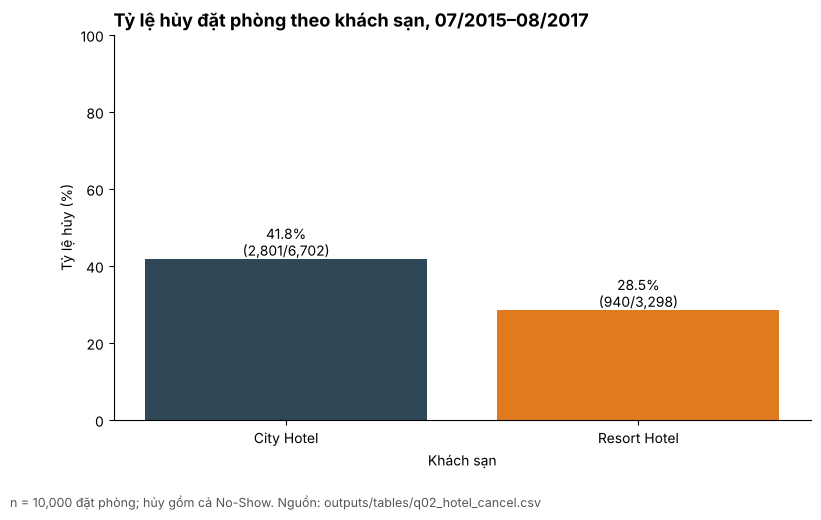

,hotel,n_bookings,share_pct,n_canceled,cancel_rate_pct
0,City Hotel,6702,67.02,2801,41.79
1,Resort Hotel,3298,32.98,940,28.5


In [44]:
# Câu 2 · Số đặt phòng và tỷ lệ hủy theo khách sạn
q02 = cancel_rate(bk, 'hotel')                                    # mẫu số = is_canceled không thiếu
q02['share_pct'] = (q02['n_bookings'] / N_BK * 100).round(2)
q02 = q02[['hotel', 'n_bookings', 'share_pct', 'n_canceled', 'cancel_rate_pct']]
save_table(q02, 'q02_hotel_cancel')
gap = q02.set_index('hotel')['cancel_rate_pct']
print(f"Chênh lệch tỷ lệ hủy City − Resort: {gap['City Hotel'] - gap['Resort Hotel']:.2f} điểm phần trăm")

fig, ax = plt.subplots(figsize=FIGSIZE)
bars = ax.bar(q02['hotel'], q02['cancel_rate_pct'], color=[HOTEL_COLORS[h] for h in q02['hotel']])
ax.bar_label(bars, labels=[f'{r:.1f}%\n({c:,}/{n:,})' for r, c, n in
                           zip(q02['cancel_rate_pct'], q02['n_canceled'], q02['n_bookings'])])
ax.set_ylim(0, 100)
finish_chart(ax, 'Tỷ lệ hủy đặt phòng theo khách sạn, 07/2015–08/2017', 'Khách sạn', 'Tỷ lệ hủy (%)',
             note=f'n = {N_BK:,} đặt phòng; hủy gồm cả No-Show. Nguồn: outputs/tables/q02_hotel_cancel.csv')
save_fig(fig, 'fig01_hotel_cancel')
plt.show()
q02

In [45]:
check('q02_hotel_cancel đã được tạo', lambda: q02 is not None and len(q02) > 0)
check('q02 có đúng 2 khách sạn', lambda: len(q02) == 2)
check('Đã lưu fig01_hotel_cancel.png', lambda: (OUTPUT_DIR / 'figures' / 'fig01_hotel_cancel.png').exists())

✅ q02_hotel_cancel đã được tạo
✅ q02 có đúng 2 khách sạn
✅ Đã lưu fig01_hotel_cancel.png


True

> **✍️ Nhận xét Câu 2**
>
> 1. **Phát hiện chính:** City Hotel có tỷ lệ hủy cao hơn rõ rệt so với Resort Hotel.
> 2. **Số liệu và mẫu số:** City Hotel: 2.801 trên 6.702 đặt phòng bị hủy (41,79%). Resort Hotel: 940 trên 3.298 đặt phòng (28,50%). Không đặt phòng nào bị loại vì thiếu is_canceled.
> 3. **So sánh làm rõ:** City Hotel cao hơn 13,29 điểm phần trăm, tức khoảng 1,47 lần. City Hotel chiếm 67,02% tổng số đặt phòng.
> 4. **Giới hạn:** Hai khách sạn khác loại hình và vị trí; dữ liệu không có lý do hủy. Insight 1 xem lại chênh lệch này trong cùng loại đặt cọc và cùng phân khúc.
>
> *Nguồn: `outputs/tables/q02_hotel_cancel.csv` · `outputs/figures/fig01_hotel_cancel.png`*

## Câu 3 · Mùa vụ: số đặt phòng theo tháng đến năm 2016

💾 outputs/tables/q03_monthly_arrivals_2016.csv  (12 dòng)
City Hotel: cao nhất tháng 10 (360), thấp nhất tháng 1 (117)
Resort Hotel: cao nhất tháng 5 (162), thấp nhất tháng 1 (62)


🖼️  outputs/figures/fig02_monthly_arrivals_2016.png


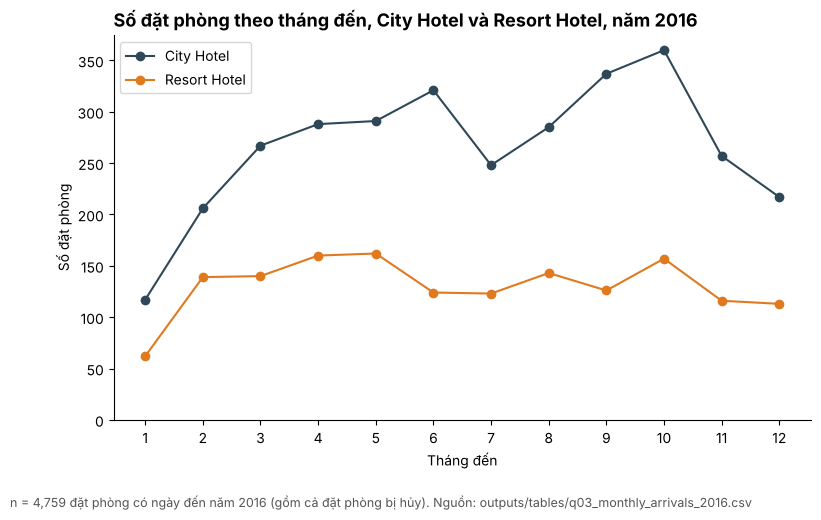

,arrival_month,City Hotel,Resort Hotel,total,cancel_rate_pct
0,1,117,62,179,22.35
1,2,206,139,345,33.04
2,3,267,140,407,33.42
3,4,288,160,448,37.28
4,5,291,162,453,39.29
5,6,321,124,445,37.3
6,7,248,123,371,30.19
7,8,285,143,428,36.68
8,9,337,126,463,40.17
9,10,360,157,517,40.62


In [46]:
# Câu 3 · Số đặt phòng theo tháng đến, năm 2016
b16 = bk[bk['arrival_year'] == 2016]
q03 = pd.crosstab(b16['arrival_month'], b16['hotel']).reindex(range(1, 13), fill_value=0)
q03['total'] = q03['City Hotel'] + q03['Resort Hotel']
q03['cancel_rate_pct'] = cancel_rate(b16, 'arrival_month').set_index('arrival_month')['cancel_rate_pct']
q03 = q03.reset_index().rename_axis(columns=None)[['arrival_month', 'City Hotel', 'Resort Hotel', 'total', 'cancel_rate_pct']]
save_table(q03, 'q03_monthly_arrivals_2016')
for h in HOTELS:
    print(f"{h}: cao nhất tháng {q03.loc[q03[h].idxmax(), 'arrival_month']} ({q03[h].max()}), "
          f"thấp nhất tháng {q03.loc[q03[h].idxmin(), 'arrival_month']} ({q03[h].min()})")

fig, ax = plt.subplots(figsize=FIGSIZE)
for h in HOTELS:
    ax.plot(q03['arrival_month'], q03[h], marker='o', color=HOTEL_COLORS[h], label=h)
ax.set_xticks(range(1, 13))
ax.set_ylim(0, None)
ax.legend()
finish_chart(ax, 'Số đặt phòng theo tháng đến, City Hotel và Resort Hotel, năm 2016', 'Tháng đến', 'Số đặt phòng',
             note=f'n = {len(b16):,} đặt phòng có ngày đến năm 2016 (gồm cả đặt phòng bị hủy). '
                  'Nguồn: outputs/tables/q03_monthly_arrivals_2016.csv')
save_fig(fig, 'fig02_monthly_arrivals_2016')
plt.show()
q03

In [47]:
check('q03_monthly_arrivals_2016 đã được tạo', lambda: q03 is not None and len(q03) > 0)
check('q03 có đủ 12 tháng', lambda: len(q03) == 12)
check('Đã lưu fig02_monthly_arrivals_2016.png', lambda: (OUTPUT_DIR / 'figures' / 'fig02_monthly_arrivals_2016.png').exists())

✅ q03_monthly_arrivals_2016 đã được tạo
✅ q03 có đủ 12 tháng
✅ Đã lưu fig02_monthly_arrivals_2016.png


True

> **✍️ Nhận xét Câu 3**
>
> 1. **Phát hiện chính:** Năm 2016, City Hotel đông nhất vào tháng 10, Resort Hotel đông nhất vào tháng 5. Cả hai khách sạn đều vắng nhất vào tháng 1.
> 2. **Số liệu và mẫu số:** Tính trên các đặt phòng có ngày đến trong năm 2016, kể cả đặt phòng bị hủy. City Hotel dao động từ 117 (tháng 1) đến 360 (tháng 10) đặt phòng; Resort Hotel từ 62 (tháng 1) đến 162 (tháng 5).
> 3. **So sánh làm rõ:** Số đặt phòng của City Hotel tháng 10 gấp khoảng 3,1 lần tháng 1. Tỷ lệ hủy theo tháng (hai khách sạn gộp) thấp nhất vào tháng 1 (22,35%) và cao nhất vào tháng 10 (40,62%).
> 4. **Giới hạn:** Số đặt phòng gồm cả đặt phòng bị hủy, nên không phải số khách thực ở. Chỉ năm 2016 có đủ 12 tháng, nên không so sánh tổng năm với 2015 và 2017. 49 đặt phòng không có ngày đến hợp lệ không được tính.
>
> *Nguồn: `outputs/tables/q03_monthly_arrivals_2016.csv` · `outputs/figures/fig02_monthly_arrivals_2016.png`*

## Câu 4 · Thời gian đặt trước (lead time) và hủy phòng

💾 outputs/tables/q04_leadtime_stats.csv  (2 dòng)
💾 outputs/tables/q04_leadtime_cancel.csv  (5 dòng)


🖼️  outputs/figures/fig03_leadtime_cancel.png


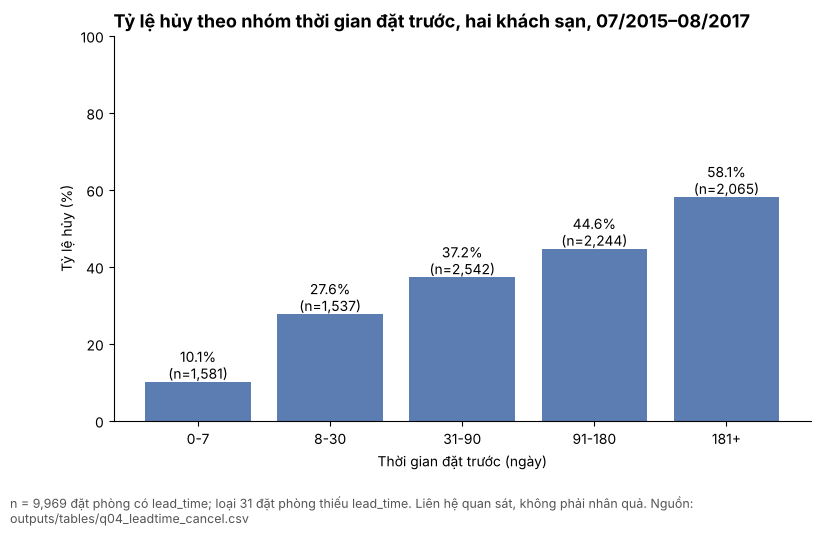

,hotel,n,mean,median,q1,q3,max
0,City Hotel,6683,110.8,74.0,24.0,164.0,629.0
1,Resort Hotel,3286,93.0,61.0,12.0,154.0,709.0


,lead_time_group,n_bookings,n_known,n_canceled,cancel_rate_pct
0,0-7,1581,1581,159,10.06
1,8-30,1537,1537,425,27.65
2,31-90,2542,2542,946,37.21
3,91-180,2244,2244,1001,44.61
4,181+,2065,2065,1199,58.06


In [48]:
# Câu 4 · Lead time và hủy phòng
lt = bk[bk['lead_time'].notna()]
q04 = (lt.assign(lead=lt['lead_time'].astype('float')).groupby('hotel')['lead']
         .agg(n='count', mean='mean', median='median',
              q1=lambda s: s.quantile(0.25), q3=lambda s: s.quantile(0.75), max='max')
         .round(1).reset_index())
q04_b = cancel_rate(lt, 'lead_time_group')                        # thứ tự 0-7 → 181+
save_table(q04, 'q04_leadtime_stats')
save_table(q04_b, 'q04_leadtime_cancel')

fig, ax = plt.subplots(figsize=FIGSIZE)
bars = ax.bar(q04_b['lead_time_group'].astype(str), q04_b['cancel_rate_pct'], color='#5B7DB1')
ax.bar_label(bars, labels=[f'{r:.1f}%\n(n={n:,})' for r, n in zip(q04_b['cancel_rate_pct'], q04_b['n_known'])])
ax.set_ylim(0, 100)
finish_chart(ax, 'Tỷ lệ hủy theo nhóm thời gian đặt trước, hai khách sạn, 07/2015–08/2017',
             'Thời gian đặt trước (ngày)', 'Tỷ lệ hủy (%)',
             note=f'n = {len(lt):,} đặt phòng có lead_time; loại {N_BK - len(lt)} đặt phòng thiếu lead_time. '
                  'Liên hệ quan sát, không phải nhân quả. Nguồn: outputs/tables/q04_leadtime_cancel.csv')
save_fig(fig, 'fig03_leadtime_cancel')
plt.show()
display(q04)
q04_b

In [49]:
check('q04_leadtime_stats đã được tạo', lambda: q04 is not None and len(q04) > 0)
check('q04_leadtime_cancel đã được tạo', lambda: q04_b is not None and len(q04_b) > 0)
check('q04_leadtime_cancel có 5 nhóm', lambda: len(q04_b) == 5)
check('Đã lưu fig03_leadtime_cancel.png', lambda: (OUTPUT_DIR / 'figures' / 'fig03_leadtime_cancel.png').exists())

✅ q04_leadtime_stats đã được tạo
✅ q04_leadtime_cancel đã được tạo
✅ q04_leadtime_cancel có 5 nhóm
✅ Đã lưu fig03_leadtime_cancel.png


True

> **✍️ Nhận xét Câu 4**
>
> 1. **Phát hiện chính:** Đặt phòng càng sớm thì tỷ lệ hủy càng cao, và xu hướng này tăng đều qua cả 5 nhóm.
> 2. **Số liệu và mẫu số:** Tính trên 9.969 đặt phòng có lead time (loại 31 đặt phòng thiếu). Nhóm 0–7 ngày bị hủy 10,06% (159/1.581); nhóm từ 181 ngày bị hủy 58,06% (1.199/2.065). Trung vị lead time của City Hotel là 74 ngày, của Resort Hotel là 61 ngày.
> 3. **So sánh làm rõ:** Hai nhóm ở hai đầu chênh nhau 48,01 điểm phần trăm, tức gấp khoảng 5,8 lần. Lead time trung bình (110,8 ngày ở City Hotel) cao hơn nhiều so với trung vị, tức có một số đặt phòng đặt rất sớm.
> 4. **Giới hạn:** Đây là mối liên hệ quan sát; dữ liệu không cho biết vì sao đặt phòng sớm bị hủy nhiều hơn. Insight 2 xem lại xu hướng trong cùng loại đặt cọc, khách sạn và phân khúc.
>
> *Nguồn: `outputs/tables/q04_leadtime_stats.csv`, `q04_leadtime_cancel.csv` · `outputs/figures/fig03_leadtime_cancel.png`*

## Câu 5 · Top 10 quốc gia của khách

💾 outputs/tables/q05_top10_country.csv  (10 dòng)
Đặt phòng thiếu quốc gia: 107


🖼️  outputs/figures/fig04_top10_country.png


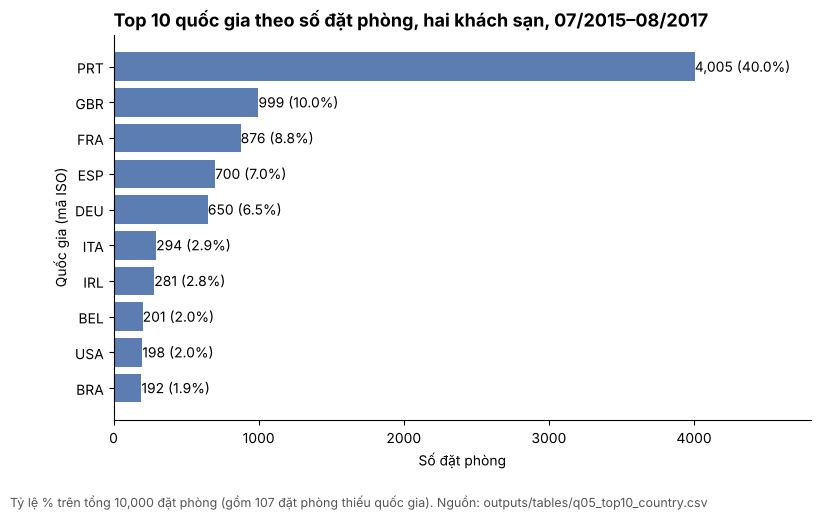

,rank,country,n_bookings,pct_of_all_bookings,cancel_rate_pct
0,1,PRT,4005,40.05,57.68
1,2,GBR,999,9.99,19.72
2,3,FRA,876,8.76,19.06
3,4,ESP,700,7.0,24.57
4,5,DEU,650,6.5,18.62
5,6,ITA,294,2.94,33.67
6,7,IRL,281,2.81,23.84
7,8,BEL,201,2.01,18.41
8,9,USA,198,1.98,24.75
9,10,BRA,192,1.92,41.15


In [50]:
# Câu 5 · Top 10 quốc gia
by_country = cancel_rate(bk, 'country')                           # bỏ đặt phòng thiếu country
q05 = (by_country.sort_values(['n_bookings', 'country'], ascending=[False, True])   # đồng hạng → theo mã
                 .head(10).reset_index(drop=True))
q05.insert(0, 'rank', range(1, 11))
q05['pct_of_all_bookings'] = (q05['n_bookings'] / N_BK * 100).round(2)   # mẫu số gồm cả thiếu quốc gia
q05 = q05[['rank', 'country', 'n_bookings', 'pct_of_all_bookings', 'cancel_rate_pct']]
save_table(q05, 'q05_top10_country')
n_no_country = int(bk['country'].isna().sum())
print('Đặt phòng thiếu quốc gia:', n_no_country)

fig, ax = plt.subplots(figsize=FIGSIZE)
bars = ax.barh(q05['country'][::-1], q05['n_bookings'][::-1], color='#5B7DB1')
ax.bar_label(bars, labels=[f'{n:,} ({p:.1f}%)' for n, p in zip(q05['n_bookings'][::-1], q05['pct_of_all_bookings'][::-1])])
ax.set_xlim(0, q05['n_bookings'].max() * 1.2)
finish_chart(ax, 'Top 10 quốc gia theo số đặt phòng, hai khách sạn, 07/2015–08/2017', 'Số đặt phòng', 'Quốc gia (mã ISO)',
             note=f'Tỷ lệ % trên tổng {N_BK:,} đặt phòng (gồm {n_no_country} đặt phòng thiếu quốc gia). '
                  'Nguồn: outputs/tables/q05_top10_country.csv')
save_fig(fig, 'fig04_top10_country')
plt.show()
q05

In [51]:
check('q05_top10_country đã được tạo', lambda: q05 is not None and len(q05) > 0)
check('q05 có 10 quốc gia', lambda: len(q05) == 10)
check('Đã lưu fig04_top10_country.png', lambda: (OUTPUT_DIR / 'figures' / 'fig04_top10_country.png').exists())

✅ q05_top10_country đã được tạo
✅ q05 có 10 quốc gia
✅ Đã lưu fig04_top10_country.png


True

> **✍️ Nhận xét Câu 5**
>
> 1. **Phát hiện chính:** Khách Bồ Đào Nha chiếm hai phần năm số đặt phòng và có tỷ lệ hủy cao nhất trong top 10.
> 2. **Số liệu và mẫu số:** PRT có 4.005 trên 10.000 đặt phòng (40,05%), tỷ lệ hủy 57,68%. Mẫu số tỷ trọng gồm cả 107 đặt phòng thiếu quốc gia.
> 3. **So sánh làm rõ:** Tỷ lệ hủy của PRT cao hơn khoảng 38 điểm phần trăm so với GBR (19,72%), FRA (19,06%) và DEU (18,62%). Các nước đứng thứ 2 đến thứ 10 mỗi nước chỉ chiếm từ 1,92% đến 9,99%.
> 4. **Giới hạn:** Theo nhóm tác giả nguồn, quốc gia thường chỉ được xác nhận khi khách nhận phòng, nên quốc gia của đặt phòng bị hủy có thể kém chính xác. Khách nội địa chiếm phần lớn là điều dễ hiểu với khách sạn ở Bồ Đào Nha.
>
> *Nguồn: `outputs/tables/q05_top10_country.csv` · `outputs/figures/fig04_top10_country.png`*

## Câu 6 · Phân khúc thị trường

💾 outputs/tables/q06_segment_cancel.csv  (7 dòng)
Đặt phòng thiếu phân khúc: 3


🖼️  outputs/figures/fig05_segment_cancel.png


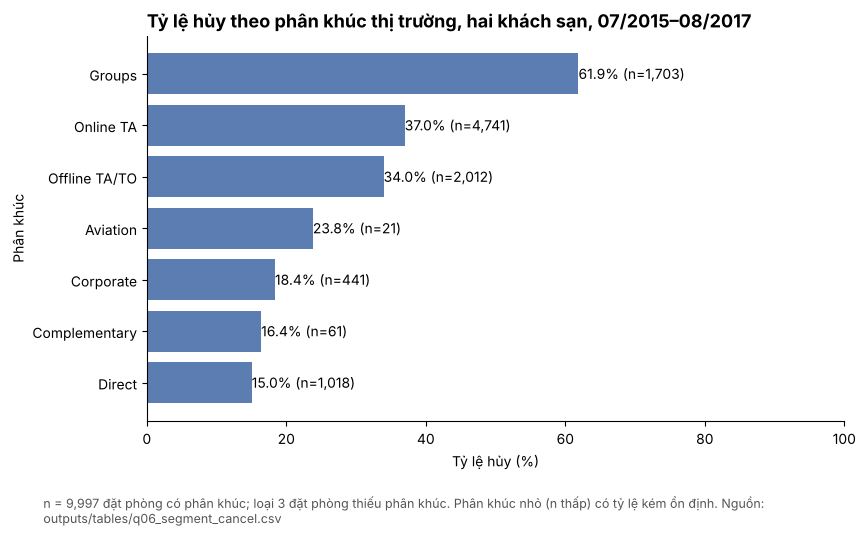

,market_segment,n_bookings,share_pct,n_known,n_canceled,cancel_rate_pct
6,Online TA,4741,47.42,4741,1753,36.98
5,Offline TA/TO,2012,20.13,2012,683,33.95
4,Groups,1703,17.04,1703,1054,61.89
3,Direct,1018,10.18,1018,153,15.03
2,Corporate,441,4.41,441,81,18.37
1,Complementary,61,0.61,61,10,16.39
0,Aviation,21,0.21,21,5,23.81


In [52]:
# Câu 6 · Phân khúc thị trường
q06 = cancel_rate(bk, 'market_segment')
n_with_segment = int(q06['n_bookings'].sum())
q06['share_pct'] = (q06['n_bookings'] / n_with_segment * 100).round(2)  # mẫu số: có phân khúc
q06 = q06.sort_values('n_bookings', ascending=False)[['market_segment', 'n_bookings', 'share_pct',
                                                      'n_known', 'n_canceled', 'cancel_rate_pct']]
save_table(q06, 'q06_segment_cancel')
print('Đặt phòng thiếu phân khúc:', N_BK - n_with_segment)

plot6 = q06.sort_values('cancel_rate_pct')
fig, ax = plt.subplots(figsize=FIGSIZE)
bars = ax.barh(plot6['market_segment'], plot6['cancel_rate_pct'], color='#5B7DB1')
ax.bar_label(bars, labels=[f'{r:.1f}% (n={n:,})' for r, n in zip(plot6['cancel_rate_pct'], plot6['n_known'])])
ax.set_xlim(0, 100)
finish_chart(ax, 'Tỷ lệ hủy theo phân khúc thị trường, hai khách sạn, 07/2015–08/2017', 'Tỷ lệ hủy (%)', 'Phân khúc',
             note=f'n = {n_with_segment:,} đặt phòng có phân khúc; loại {N_BK - n_with_segment} đặt phòng thiếu phân khúc. '
                  'Phân khúc nhỏ (n thấp) có tỷ lệ kém ổn định. Nguồn: outputs/tables/q06_segment_cancel.csv')
save_fig(fig, 'fig05_segment_cancel')
plt.show()
q06

In [53]:
check('q06_segment_cancel đã được tạo', lambda: q06 is not None and len(q06) > 0)
check('Đã lưu fig05_segment_cancel.png', lambda: (OUTPUT_DIR / 'figures' / 'fig05_segment_cancel.png').exists())

✅ q06_segment_cancel đã được tạo
✅ Đã lưu fig05_segment_cancel.png


True

> **✍️ Nhận xét Câu 6**
>
> 1. **Phát hiện chính:** Online TA là phân khúc lớn nhất, còn Groups là phân khúc có tỷ lệ hủy cao nhất.
> 2. **Số liệu và mẫu số:** Tính trên 9.997 đặt phòng có phân khúc (loại 3 đặt phòng thiếu). Online TA chiếm 47,42% (4.741 đặt phòng), hủy 36,98%. Groups có 1.703 đặt phòng, hủy 61,89%.
> 3. **So sánh làm rõ:** Groups cao hơn Direct (15,03%) khoảng 46,9 điểm phần trăm, tức gấp khoảng 4,1 lần.
> 4. **Giới hạn:** Aviation (21 đặt phòng) và Complementary (61 đặt phòng) có cỡ mẫu nhỏ, nên tỷ lệ hủy kém ổn định và không nên so sánh trực tiếp. Insight 6 xem lại thứ hạng trong nhóm No Deposit.
>
> *Nguồn: `outputs/tables/q06_segment_cancel.csv` · `outputs/figures/fig05_segment_cancel.png`*

## Câu 7 · Loại đặt cọc và trạng thái đặt phòng

💾 outputs/tables/q07_deposit_cancel.csv  (3 dòng)


🖼️  outputs/figures/fig06_deposit_cancel.png


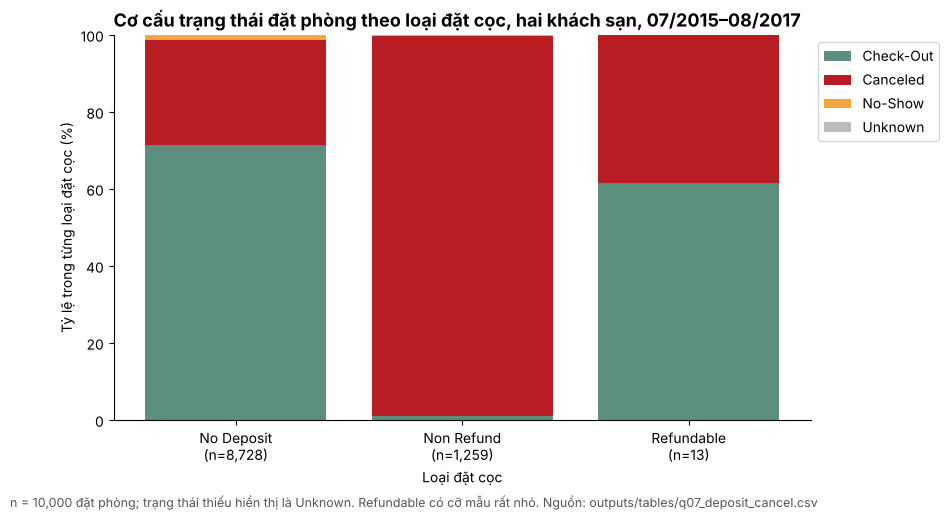

,deposit_type,n_bookings,n_Check-Out,n_Canceled,n_No-Show,n_Unknown,pct_Check-Out,pct_Canceled,pct_No-Show,pct_Unknown
0,No Deposit,8728,6224,2377,105,22,71.31,27.23,1.2,0.25
1,Non Refund,1259,12,1244,0,3,0.95,98.81,0.0,0.24
2,Refundable,13,8,5,0,0,61.54,38.46,0.0,0.00


In [54]:
# Câu 7 · Loại đặt cọc và trạng thái
STATUS_ORDER = ['Check-Out', 'Canceled', 'No-Show', 'Unknown']
status_show = bk['reservation_status'].fillna('Unknown')          # Unknown chỉ để trình bày, vẫn trong mẫu số
counts = pd.crosstab(bk['deposit_type'], status_show).reindex(columns=STATUS_ORDER, fill_value=0)
pcts = (counts.div(counts.sum(axis=1), axis=0) * 100).round(2)
q07 = counts.add_prefix('n_').join(pcts.add_prefix('pct_'))
q07.insert(0, 'n_bookings', counts.sum(axis=1))
q07 = q07.reset_index().rename_axis(columns=None)
save_table(q07, 'q07_deposit_cancel')

fig, ax = plt.subplots(figsize=FIGSIZE)
bottom = pd.Series(0.0, index=pcts.index)
colors = {**STATUS_COLORS, 'Unknown': '#BBBBBB'}
for st in STATUS_ORDER:
    ax.bar(pcts.index, pcts[st], bottom=bottom, color=colors[st], label=st)
    bottom += pcts[st]
ax.set_xticks(range(len(pcts.index)))
ax.set_xticklabels([f'{d}\n(n={n:,})' for d, n in zip(pcts.index, counts.sum(axis=1))])
ax.set_ylim(0, 100)
ax.legend(loc='upper left', bbox_to_anchor=(1, 1))
finish_chart(ax, 'Cơ cấu trạng thái đặt phòng theo loại đặt cọc, hai khách sạn, 07/2015–08/2017',
             'Loại đặt cọc', 'Tỷ lệ trong từng loại đặt cọc (%)',
             note=f'n = {N_BK:,} đặt phòng; trạng thái thiếu hiển thị là Unknown. Refundable có cỡ mẫu rất nhỏ. '
                  'Nguồn: outputs/tables/q07_deposit_cancel.csv')
save_fig(fig, 'fig06_deposit_cancel')
plt.show()
q07

In [55]:
check('q07_deposit_cancel đã được tạo', lambda: q07 is not None and len(q07) > 0)
check('Đã lưu fig06_deposit_cancel.png', lambda: (OUTPUT_DIR / 'figures' / 'fig06_deposit_cancel.png').exists())

✅ q07_deposit_cancel đã được tạo
✅ Đã lưu fig06_deposit_cancel.png


True

> **✍️ Nhận xét Câu 7**
>
> 1. **Phát hiện chính:** Gần như toàn bộ đặt phòng có đặt cọc không hoàn lại (Non Refund) đều bị hủy.
> 2. **Số liệu và mẫu số:** Non Refund có 1.259 đặt phòng, trong đó 98,81% có trạng thái Canceled và chỉ 0,95% (12 đặt phòng) trả phòng bình thường. No Deposit có 8.728 đặt phòng: 27,23% Canceled, 1,20% No-Show. 25 đặt phòng không có trạng thái (Unknown) vẫn được tính trong mẫu số.
> 3. **So sánh làm rõ:** Tỷ lệ Canceled của Non Refund cao hơn No Deposit khoảng 71,6 điểm phần trăm.
> 4. **Giới hạn:** Kết quả này ngược với trực giác. Theo lưu ý của đề, không kết luận đặt cọc làm khách hủy; mẫu hình này có thể liên quan đến cách ghi nhận dữ liệu hoặc đặc điểm nhóm khách và cần kiểm chứng. Refundable chỉ có 13 đặt phòng.
>
> *Nguồn: `outputs/tables/q07_deposit_cancel.csv` · `outputs/figures/fig06_deposit_cancel.png`*

## Câu 8 · Giá phòng bình quân/đêm (ADR)

💾 outputs/tables/q08_adr_stats_by_hotel.csv  (2 dòng)
Đặt phòng không hủy: 6,259 | adr = 0: 120 | adr thiếu: 18


🖼️  outputs/figures/fig07_adr_hist.png


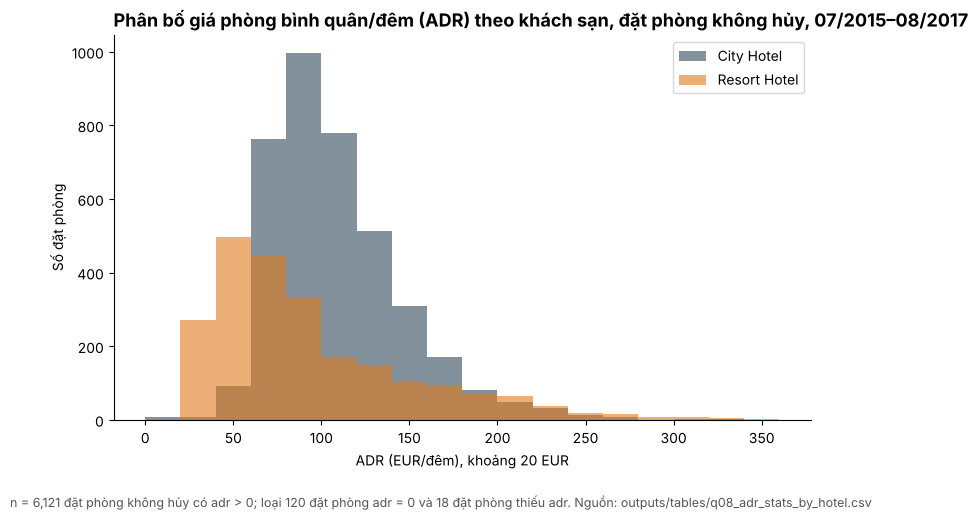

,hotel,n,mean,median,min,max,q1,q3
0,City Hotel,3828,108.18,100.65,4.5,336.00,80.75,126.9
1,Resort Hotel,2293,93.60,75.00,6.0,349.67,51.50,120.0


In [56]:
# Câu 8 · ADR: đặt phòng không hủy, adr > 0
adr_pos = stayed[stayed['adr'] > 0]
q08 = (adr_pos.groupby('hotel')['adr']
              .agg(n='count', mean='mean', median='median', min='min', max='max',
                   q1=lambda s: s.quantile(0.25), q3=lambda s: s.quantile(0.75))
              .round(2).reset_index())
save_table(q08, 'q08_adr_stats_by_hotel')
n_adr0 = int((stayed['adr'] == 0).sum())
n_adr_na = int(stayed['adr'].isna().sum())
print(f'Đặt phòng không hủy: {len(stayed):,} | adr = 0: {n_adr0} | adr thiếu: {n_adr_na}')

fig, ax = plt.subplots(figsize=FIGSIZE)
bins = range(0, int(adr_pos['adr'].max()) + 21, 20)                  # khoảng 20 EUR
for h in HOTELS:
    ax.hist(adr_pos.loc[adr_pos['hotel'] == h, 'adr'], bins=bins, alpha=0.6, color=HOTEL_COLORS[h], label=h)
ax.legend()
finish_chart(ax, 'Phân bố giá phòng bình quân/đêm (ADR) theo khách sạn, đặt phòng không hủy, 07/2015–08/2017',
             'ADR (EUR/đêm), khoảng 20 EUR', 'Số đặt phòng',
             note=f'n = {len(adr_pos):,} đặt phòng không hủy có adr > 0; loại {n_adr0} đặt phòng adr = 0 và '
                  f'{n_adr_na} đặt phòng thiếu adr. Nguồn: outputs/tables/q08_adr_stats_by_hotel.csv')
save_fig(fig, 'fig07_adr_hist')
plt.show()
q08

In [57]:
check('q08_adr_stats_by_hotel đã được tạo', lambda: q08 is not None and len(q08) > 0)
check('Đã lưu fig07_adr_hist.png', lambda: (OUTPUT_DIR / 'figures' / 'fig07_adr_hist.png').exists())

✅ q08_adr_stats_by_hotel đã được tạo
✅ Đã lưu fig07_adr_hist.png


True

> **✍️ Nhận xét Câu 8**
>
> 1. **Phát hiện chính:** Giá phòng bình quân/đêm ở City Hotel cao hơn, còn ở Resort Hotel giá dao động rộng hơn.
> 2. **Số liệu và mẫu số:** Chỉ tính đặt phòng không hủy có adr > 0: City Hotel 3.828, Resort Hotel 2.293. Loại riêng 120 đặt phòng có adr = 0 và 18 đặt phòng thiếu adr. Trung vị: City Hotel 100,65 EUR, Resort Hotel 75,00 EUR.
> 3. **So sánh làm rõ:** Trung vị của City Hotel cao hơn 25,65 EUR. Ở cả hai khách sạn, giá trung bình (108,18 và 93,60 EUR) đều cao hơn trung vị, tức có một số đặt phòng giá cao. Nửa giữa dữ liệu (Q1–Q3) ở Resort Hotel trải từ 51,50 đến 120,00 EUR, rộng hơn City Hotel (80,75 đến 126,90 EUR).
> 4. **Giới hạn:** ADR là giá phòng bình quân mỗi đêm, không phải doanh thu thực. Insight 10 tách theo tháng và theo phòng loại A.
>
> *Nguồn: `outputs/tables/q08_adr_stats_by_hotel.csv` · `outputs/figures/fig07_adr_hist.png`*

## Câu 9 · Thời gian lưu trú

💾 outputs/tables/q09_stay_nights.csv  (16 dòng)
Lưu trú 1–3 đêm: 3,922 / 6,234 = 62.91% | 0 đêm: 37


🖼️  outputs/figures/fig08_stay_nights.png


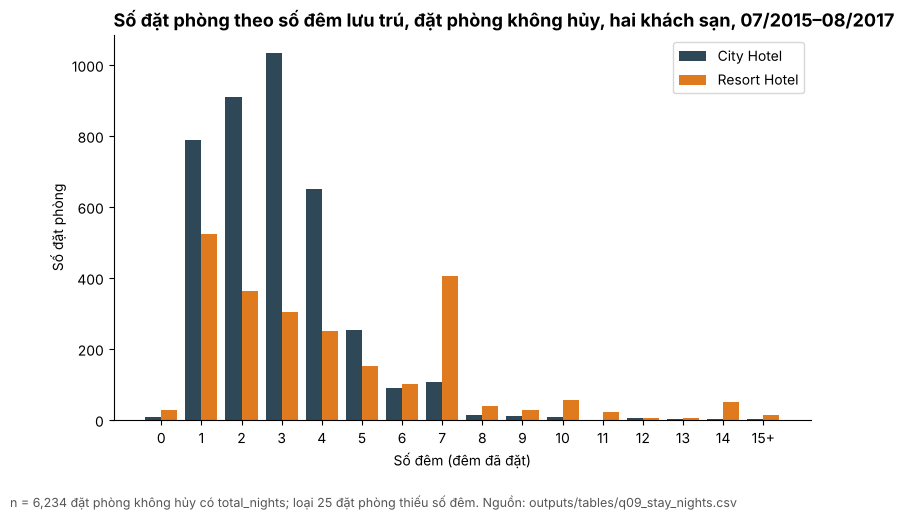

,nights_group,City Hotel,Resort Hotel,total,pct
0,0,8,29,37,0.59
1,1,788,525,1313,21.06
2,2,909,363,1272,20.40
3,3,1033,304,1337,21.45
4,4,650,249,899,14.42
5,5,252,153,405,6.50
6,6,91,100,191,3.06
7,7,107,406,513,8.23
8,8,14,40,54,0.87
9,9,10,29,39,0.63


In [58]:
# Câu 9 · Thời gian lưu trú: đặt phòng không hủy có total_nights
st9 = stayed[stayed['total_nights'].notna()].copy()
NIGHT_GROUPS = [str(i) for i in range(15)] + ['15+']
st9['nights_group'] = pd.Categorical(st9['total_nights'].clip(upper=15).astype(int).astype(str).replace('15', '15+'),
                                     categories=NIGHT_GROUPS, ordered=True)
q09 = pd.crosstab(st9['nights_group'], st9['hotel']).reindex(NIGHT_GROUPS, fill_value=0)
q09['total'] = q09['City Hotel'] + q09['Resort Hotel']
q09['pct'] = (q09['total'] / q09['total'].sum() * 100).round(2)
q09 = q09.reset_index().rename_axis(columns=None)[['nights_group', 'City Hotel', 'Resort Hotel', 'total', 'pct']]
save_table(q09, 'q09_stay_nights')
short = q09[q09['nights_group'].isin(['1', '2', '3'])]['total'].sum()
print(f'Lưu trú 1–3 đêm: {short:,} / {len(st9):,} = {short / len(st9) * 100:.2f}% | 0 đêm: {int((st9["total_nights"] == 0).sum())}')

fig, ax = plt.subplots(figsize=FIGSIZE)
x = range(len(NIGHT_GROUPS))
w = 0.4
for i, h in enumerate(HOTELS):
    ax.bar([p + (i - 0.5) * w for p in x], q09[h], width=w, color=HOTEL_COLORS[h], label=h)
ax.set_xticks(list(x))
ax.set_xticklabels(NIGHT_GROUPS)
ax.legend()
finish_chart(ax, 'Số đặt phòng theo số đêm lưu trú, đặt phòng không hủy, hai khách sạn, 07/2015–08/2017',
             'Số đêm (đêm đã đặt)', 'Số đặt phòng',
             note=f'n = {len(st9):,} đặt phòng không hủy có total_nights; loại {len(stayed) - len(st9)} đặt phòng thiếu số đêm. '
                  'Nguồn: outputs/tables/q09_stay_nights.csv')
save_fig(fig, 'fig08_stay_nights')
plt.show()
q09

In [59]:
check('q09_stay_nights đã được tạo', lambda: q09 is not None and len(q09) > 0)
check('Đã lưu fig08_stay_nights.png', lambda: (OUTPUT_DIR / 'figures' / 'fig08_stay_nights.png').exists())

✅ q09_stay_nights đã được tạo
✅ Đã lưu fig08_stay_nights.png


True

> **✍️ Nhận xét Câu 9**
>
> 1. **Phát hiện chính:** Phần lớn đặt phòng ngắn ngày (1–3 đêm). Riêng Resort Hotel có một nhóm lớn đặt đúng 7 đêm.
> 2. **Số liệu và mẫu số:** Tính trên 6.234 đặt phòng không hủy có số đêm (loại 25 đặt phòng thiếu số đêm). Lưu trú 1–3 đêm chiếm 62,91% (3.922 đặt phòng). Có 37 đặt phòng ghi 0 đêm, được báo cáo riêng.
> 3. **So sánh làm rõ:** Ở City Hotel, 70,29% đặt phòng là 1–3 đêm, so với 50,72% ở Resort Hotel. Nhóm đúng 7 đêm chiếm 17,28% số đặt phòng của Resort Hotel (406), nhưng chỉ 2,75% ở City Hotel (107).
> 4. **Giới hạn:** Số đêm ở đây là số đêm đã đặt; dữ liệu không cho biết khách có trả phòng sớm hay không.
>
> *Nguồn: `outputs/tables/q09_stay_nights.csv` · `outputs/figures/fig08_stay_nights.png`*

## Câu 10 · Đổi loại phòng khi nhận phòng

In [60]:
# Câu 10 · Đổi loại phòng: Check-Out có đủ hai loại phòng
co = bk[(bk['reservation_status'] == 'Check-Out').fillna(False)
        & bk['reserved_room_type'].notna() & bk['assigned_room_type'].notna()]

def change_rate(frame, by):
    out = frame.groupby(by)['room_changed_flag'].agg(n_bookings='size', n_changed='sum').reset_index()
    out['changed_pct'] = (out['n_changed'] / out['n_bookings'] * 100).round(2)
    return out

q10 = change_rate(co, 'hotel')
q10_b = change_rate(co, 'reserved_room_type').sort_values('reserved_room_type')
save_table(q10, 'q10_room_change_by_hotel')
save_table(q10_b, 'q10_room_change_by_reserved_type')
print(f'Mẫu số: {len(co):,} đặt phòng Check-Out có đủ hai loại phòng')
display(q10)
q10_b

💾 outputs/tables/q10_room_change_by_hotel.csv  (2 dòng)
💾 outputs/tables/q10_room_change_by_reserved_type.csv  (8 dòng)
Mẫu số: 6,242 đặt phòng Check-Out có đủ hai loại phòng


,hotel,n_bookings,n_changed,changed_pct
0,City Hotel,3891,561,14.42
1,Resort Hotel,2351,583,24.80


,reserved_room_type,n_bookings,n_changed,changed_pct
0,A,4287,948,22.11
1,B,64,11,17.19
2,C,50,4,8.00
3,D,1137,114,10.03
4,E,397,47,11.84
5,F,174,15,8.62
6,G,110,3,2.73
7,H,23,2,8.70


In [61]:
check('q10_room_change_by_hotel đã được tạo', lambda: q10 is not None and len(q10) > 0)
check('q10_room_change_by_reserved_type đã được tạo', lambda: q10_b is not None and len(q10_b) > 0)

✅ q10_room_change_by_hotel đã được tạo
✅ q10_room_change_by_reserved_type đã được tạo


True

> **✍️ Nhận xét Câu 10**
>
> 1. **Phát hiện chính:** Đặt phòng ở Resort Hotel được xếp phòng khác loại đã đặt nhiều hơn so với City Hotel.
> 2. **Số liệu và mẫu số:** Tính trên 6.242 đặt phòng đã trả phòng (Check-Out) và có đủ cả loại phòng đặt lẫn loại phòng được xếp. Resort Hotel: 583/2.351 (24,80%). City Hotel: 561/3.891 (14,42%).
> 3. **So sánh làm rõ:** Resort Hotel cao hơn 10,38 điểm phần trăm. Theo loại phòng đặt, loại A có tỷ lệ đổi cao nhất (22,11%, n = 4.287); loại G thấp nhất (2,73%, n = 110).
> 4. **Giới hạn:** Dữ liệu không cho biết lý do đổi phòng (nâng hạng, hết phòng hay khách yêu cầu). Loại H chỉ có 23 đặt phòng, nên tỷ lệ kém ổn định.
>
> *Nguồn: `outputs/tables/q10_room_change_by_hotel.csv`, `q10_room_change_by_reserved_type.csv` · `outputs/figures/fig09_room_change.png`*

---
## Bảng nguồn và hình bổ sung cho insight

Hai ô dưới tạo 30 bảng `outputs/tables/ins*.csv` và 11 hình `fig09`–`fig19`. Tên `fig09_room_change.png` theo gợi ý của đề ở Câu 10.

In [62]:
# ===== BẢNG NGUỒN CHO 13 INSIGHT (bổ sung, ngoài 14 bảng bắt buộc) =====
# Tỷ lệ hủy: mẫu số = is_canceled không thiếu; kèm khoảng tin cậy 95% Wilson.
# Mỗi phát hiện về hủy được xem lại trong No Deposit và theo biến liên quan (khách sạn, phân khúc, lead time).
from math import sqrt
import numpy as np

def wilson(k, n, z=1.96):
    """Khoảng tin cậy 95% Wilson cho tỷ lệ k/n, trả về (thấp %, cao %)."""
    if n == 0: return (float('nan'),) * 2
    p, d = k / n, 1 + z*z/n
    c, a = p + z*z/(2*n), z*sqrt(p*(1-p)/n + z*z/(4*n*n))
    return round((c-a)/d*100, 2), round((c+a)/d*100, 2)

def rate_by(frame, by, scope):
    """Tỷ lệ hủy theo nhóm `by`, kèm CI; cột scope ghi phạm vi dữ liệu."""
    f = frame[frame['is_canceled'].notna()]
    out = f.groupby(by, observed=True)['is_canceled'].agg(n_canceled='sum', n_known='count').reset_index()
    out['n_canceled'] = out['n_canceled'].astype(int)
    out['cancel_rate_pct'] = (out['n_canceled'] / out['n_known'] * 100).round(2)
    out[['ci_low', 'ci_high']] = [wilson(k, n) for k, n in zip(out['n_canceled'], out['n_known'])]
    out.insert(0, 'scope', scope)
    return out

def both_scopes(frame, by):
    """Tỷ lệ hủy cho tất cả và cho No Deposit, kèm tỷ trọng Non Refund của từng nhóm."""
    out = pd.concat([rate_by(frame, by, 'all'),
                     rate_by(frame[frame['deposit_type'] == 'No Deposit'], by, 'no_deposit')],
                    ignore_index=True)
    share = (frame.groupby(by, observed=True)['deposit_type']
                  .apply(lambda s: s.eq('Non Refund').mean() * 100).round(2)
                  .rename('non_refund_pct').reset_index())
    return out.merge(share, on=by, how='left')

nr = bk['deposit_type'].eq('Non Refund')
ndp = bk[bk['deposit_type'] == 'No Deposit']
b16 = bk[bk['arrival_year'] == 2016]
MAIN_SEG = ['Online TA', 'Offline TA/TO', 'Groups', 'Direct', 'Corporate']
ins = {}

# ---- Insight 1 · Khách sạn ----
ins['ins01_hotel_gap_by_deposit'] = both_scopes(bk, 'hotel')
ins['ins01_deposit_mix_by_hotel'] = (pd.crosstab(bk['hotel'], bk['deposit_type'], normalize='index')
                                       .mul(100).round(2).reset_index().rename_axis(columns=None))
ins['ins01_segment_mix_nd'] = (pd.crosstab(ndp['hotel'], ndp['market_segment'], normalize='index')
                                 .mul(100).round(2).reset_index().rename_axis(columns=None))
ins['ins01_hotel_by_segment_nd'] = rate_by(ndp[ndp['market_segment'].isin(MAIN_SEG)],
                                           ['market_segment', 'hotel'], 'no_deposit')
ins['ins01_hotel_month_2016'] = both_scopes(b16, ['arrival_month', 'hotel'])

# ---- Insight 2 · Lead time ----
ins['ins02_leadtime_by_deposit'] = both_scopes(bk[bk['lead_time'].notna()], 'lead_time_group')
ins['ins02_leadtime_nd_by_hotel'] = rate_by(ndp, ['hotel', 'lead_time_group'], 'no_deposit')
ins['ins02_leadtime_nd_online_ta'] = rate_by(ndp[ndp['market_segment'] == 'Online TA'],
                                             'lead_time_group', 'no_deposit_online_ta')

# ---- Insight 3, 4 · Thời điểm hủy, hủy theo lô (ngày hủy = reservation_status_date khi Canceled) ----
cxl = bk[(bk['reservation_status'] == 'Canceled') & bk['arrival_date'].notna()
         & bk['reservation_status_date'].notna()].copy()
cxl['days_before_arrival'] = (pd.to_datetime(cxl['arrival_date'])
                              - pd.to_datetime(cxl['reservation_status_date'])).dt.days
cxl['batch_size'] = cxl.groupby(['hotel', 'arrival_date', 'reservation_status_date'])['booking_id'].transform('size')

def timing_row(frame, **keys):
    d = frame['days_before_arrival']
    return {**keys, 'n_canceled_with_dates': len(frame), 'median_days_before': d.median(),
            'pct_within_7d': round((d <= 7).mean()*100, 2), 'pct_within_30d': round((d <= 30).mean()*100, 2),
            'pct_over_90d': round((d > 90).mean()*100, 2), 'n_same_day': int((d == 0).sum()),
            'pct_in_batch_2plus': round((frame['batch_size'] >= 2).mean()*100, 2)}

ins['ins03_cancel_timing'] = pd.DataFrame(
    [timing_row(cxl[cxl['deposit_type'] == dep], deposit_type=dep, hotel='Cả hai')
     for dep in ['No Deposit', 'Non Refund']]
    + [timing_row(cxl[(cxl['deposit_type'] == 'No Deposit') & (cxl['hotel'] == h)],
                  deposit_type='No Deposit', hotel=h) for h in HOTELS])
ns = bk[bk['reservation_status'] == 'No-Show']
ins['ins03_no_show_dates'] = pd.DataFrame([{
    'n_no_show': len(ns),
    'n_status_date_equals_arrival': int((ns['reservation_status_date'] == ns['arrival_date']).sum())}])
ins['ins04_non_refund_profile'] = pd.DataFrame([{
    'n_non_refund': int(nr.sum()), 'n_canceled': int(bk.loc[nr, 'is_canceled'].sum()),
    'n_city': int((nr & bk['hotel'].eq('City Hotel')).sum()),
    'n_prt': int((nr & bk['country'].eq('PRT')).sum()),
    'n_groups': int((nr & bk['market_segment'].eq('Groups')).sum()),
    'mean_lead_non_refund': round(bk.loc[nr, 'lead_time'].mean(), 1),
    'mean_lead_no_deposit': round(ndp['lead_time'].mean(), 1)}])

# ---- Insight 5 · Quốc gia ----
ctry = bk[bk['country'].notna()].assign(
    country_group=lambda d: d['country'].eq('PRT').map({True: 'PRT', False: 'Khác PRT'}))
ctry_nd = ctry[ctry['deposit_type'] == 'No Deposit']
ins['ins05_country_by_deposit'] = both_scopes(ctry, 'country_group')
ins['ins05_country_nd_by_hotel'] = rate_by(ctry_nd, ['hotel', 'country_group'], 'no_deposit')
ins['ins05_country_nd_by_segment'] = rate_by(ctry_nd[ctry_nd['market_segment'].isin(MAIN_SEG)],
                                             ['market_segment', 'country_group'], 'no_deposit')

# ---- Insight 6 · Phân khúc ----
ins['ins06_segment_by_deposit'] = both_scopes(bk[bk['market_segment'].notna()], 'market_segment')
ins['ins06_ota_direct_nd_by_lead'] = rate_by(ndp[ndp['market_segment'].isin(['Online TA', 'Direct'])],
                                             ['lead_time_group', 'market_segment'], 'no_deposit')
ins['ins06_lead_median_by_segment'] = (bk.groupby('market_segment')['lead_time'].median()
                                         .rename('median_lead_time').reset_index())

# ---- Insight 7 · Yêu cầu đặc biệt (0 / 1 / 2+) ----
req = bk.assign(requests_group=pd.cut(bk['total_of_special_requests'].astype('float'),
                                      [-0.5, 0.5, 1.5, 10], labels=['0', '1', '2+']))
req_nd = req[req['deposit_type'] == 'No Deposit']
ins['ins07_special_requests'] = pd.concat([
    both_scopes(req, 'requests_group'),
    rate_by(req_nd, ['hotel', 'requests_group'], 'no_deposit_by_hotel')], ignore_index=True)
ins['ins07_requests_nd_online_ta'] = rate_by(req_nd[req_nd['market_segment'] == 'Online TA'],
                                             'requests_group', 'no_deposit_online_ta')

# ---- Insight 8 · Khách quay lại, theo lead time 0–30 / > 30 ngày ----
ins['ins08_repeated_guest'] = both_scopes(bk[bk['is_repeated_guest'].notna()], 'is_repeated_guest')
rep_nd = ndp[ndp['lead_time'].notna()].assign(lead_30=lambda d: np.where(d['lead_time'] <= 30, '0-30', '31+'))
ins['ins08_repeated_nd_by_lead'] = rate_by(rep_nd, ['lead_30', 'is_repeated_guest'], 'no_deposit')
ins['ins08_lead_share_nd'] = (pd.crosstab(rep_nd['is_repeated_guest'], rep_nd['lead_30'], normalize='index')
                                .mul(100).round(2).reset_index().rename_axis(columns=None))

# ---- Insight 9 · Mùa vụ: dùng outputs/monthly_summary.csv ----

# ---- Insight 10 · Trung vị ADR theo tháng 2016 (không hủy, adr > 0), mọi phòng và phòng loại A ----
a16 = b16[(b16['is_canceled'] == 0) & (b16['adr'] > 0)]
ins['ins10_adr_month_2016'] = (a16.groupby(['arrival_month', 'hotel'])['adr']
                                 .agg(n='count', median='median').round(1).reset_index())
ins['ins10_adr_month_2016_room_a'] = (a16[a16['reserved_room_type'] == 'A']
                                        .groupby(['arrival_month', 'hotel'])['adr']
                                        .agg(n='count', median='median').round(1).reset_index())

# ---- Insight 11 · Lưu trú (không hủy) ----
s9 = stayed[stayed['total_nights'].notna()]
ins['ins11_stay_revenue'] = pd.DataFrame([{
    'hotel': h, 'n_nights': len(d),
    'pct_1_3_nights': round(d['total_nights'].between(1, 3).mean()*100, 2),
    'pct_7_nights': round((d['total_nights'] == 7).mean()*100, 2),
    'n_revenue_est': int(stayed.loc[stayed['hotel'] == h, 'revenue_est'].notna().sum()),
    'median_revenue_est': stayed.loc[stayed['hotel'] == h, 'revenue_est'].median()}
    for h, d in s9.groupby('hotel')])
s9r = s9[s9['hotel'] == 'Resort Hotel']
ins['ins11_resort_7_nights_by_segment'] = (s9r.assign(is7=s9r['total_nights'] == 7)
                                             .groupby('market_segment')['is7']
                                             .agg(n_7_nights='sum', n_stays='count').reset_index()
                                             .assign(pct_7_nights=lambda d: (d['n_7_nights'] / d['n_stays'] * 100).round(2)))

# ---- Insight 12 · Đổi phòng (co tạo ở Câu 10) ----
def change_ci(frame, by):
    out = frame.groupby(by)['room_changed_flag'].agg(n_bookings='size', n_changed='sum').reset_index()
    out['changed_pct'] = (out['n_changed'] / out['n_bookings'] * 100).round(2)
    out[['ci_low', 'ci_high']] = [wilson(k, n) for k, n in zip(out['n_changed'], out['n_bookings'])]
    return out

ins['ins12_room_change_by_type'] = change_ci(co, ['reserved_room_type', 'hotel'])
ins['ins12_room_change_a_vs_other'] = change_ci(
    co.assign(room_group=co['reserved_room_type'].eq('A').map({True: 'A', False: 'Khác A'})), ['room_group', 'hotel'])
ra = co[(co['hotel'] == 'Resort Hotel') & (co['reserved_room_type'] == 'A') & co['arrival_month'].notna()]
ra = ra.assign(period=np.where(ra['arrival_month'].between(6, 9), 'Tháng 6-9', 'Tháng khác'))
ins['ins12_resort_room_a_by_period'] = change_ci(ra, 'period')
ins['ins12_resort_room_a_assigned'] = (ra[ra['room_changed_flag']]['assigned_room_type']
                                         .value_counts().rename_axis('assigned_room_type')
                                         .reset_index(name='n_bookings'))

# ---- Insight 13 · Giá trị hiếm: adr = 0 và 0 đêm (không hủy) ----
z = stayed[stayed['adr'] == 0]
comp = stayed[stayed['market_segment'] == 'Complementary']
ins['ins13_rare_values'] = pd.DataFrame([{
    'n_stayed_adr0': len(z),
    'n_adr0_complementary': int((z['market_segment'] == 'Complementary').sum()),
    'n_adr0_zero_nights': int((z['total_nights'] == 0).sum()),
    'n_stayed_complementary': len(comp), 'n_complementary_adr0': int((comp['adr'] == 0).sum()),
    'n_stayed_zero_nights': int((stayed['total_nights'] == 0).sum()),
    'pct_repeated_in_adr0': round(z['is_repeated_guest'].mean()*100, 2),
    'pct_repeated_all_stayed': round(stayed['is_repeated_guest'].mean()*100, 2)}])

for name, frame in ins.items():
    frame.to_csv(OUTPUT_DIR / 'tables' / f'{name}.csv', index=False, encoding='utf-8-sig')
print(f'💾 Đã lưu {len(ins)} bảng bổ sung vào outputs/tables/ins*.csv')


💾 Đã lưu 31 bảng bổ sung vào outputs/tables/ins*.csv


🖼️  outputs/figures/fig09_room_change.png


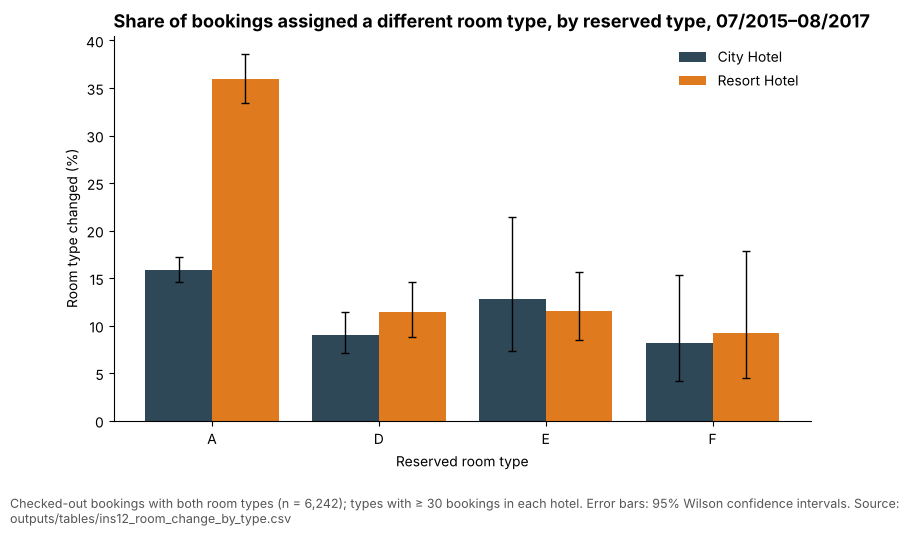

🖼️  outputs/figures/fig10_hotel_cancel_by_segment.png


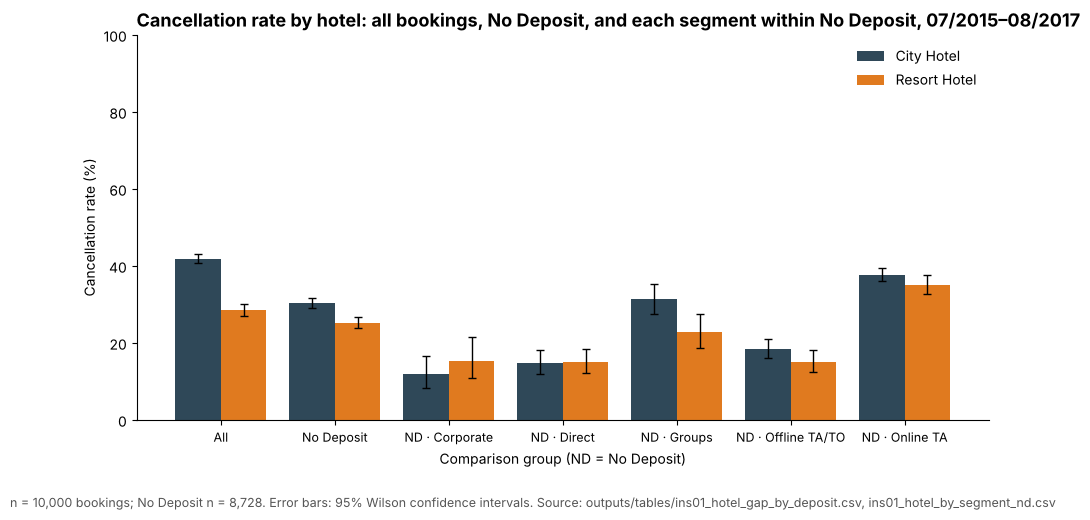

🖼️  outputs/figures/fig11_leadtime_by_deposit.png


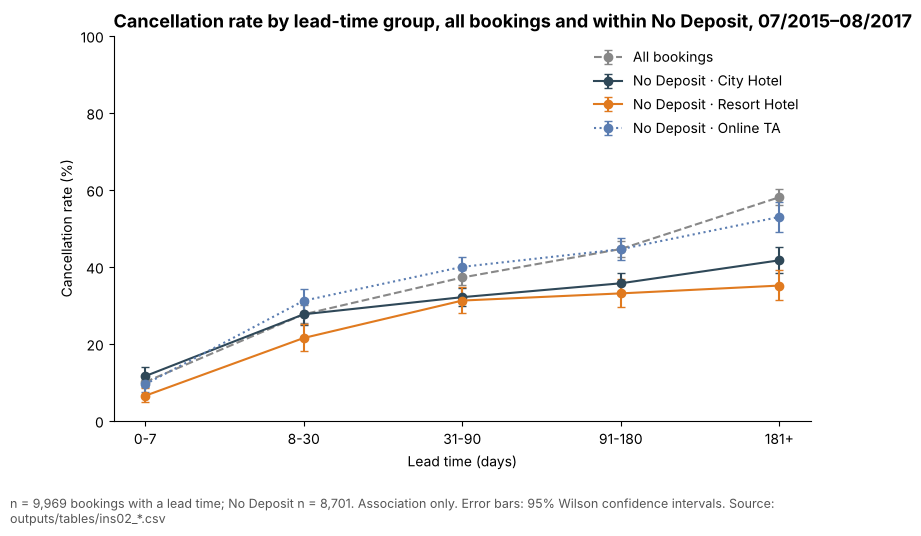

🖼️  outputs/figures/fig12_cancel_timing.png


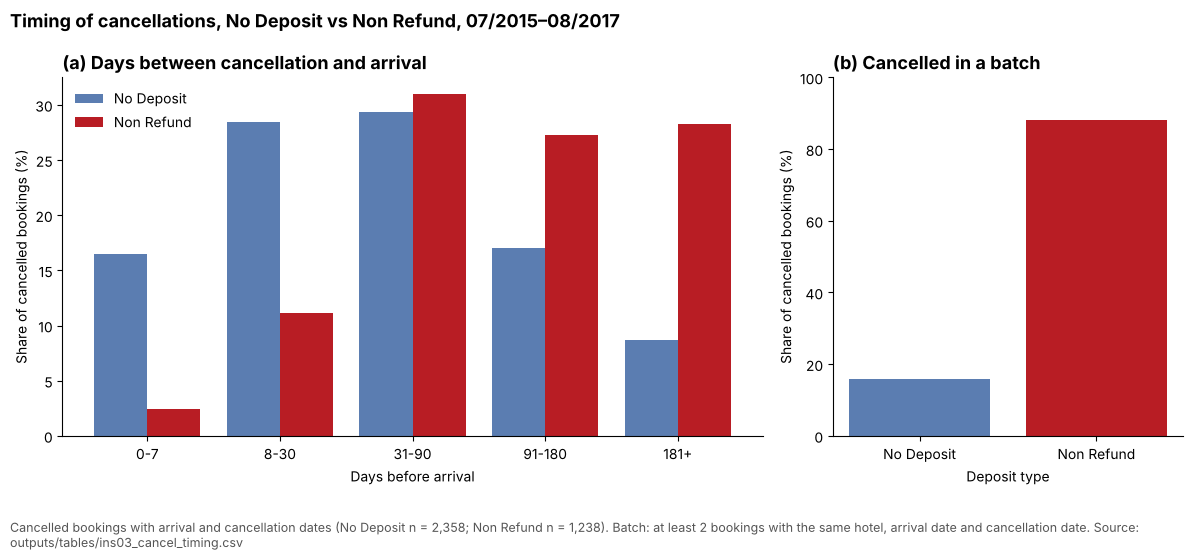

🖼️  outputs/figures/fig13_country_by_segment.png


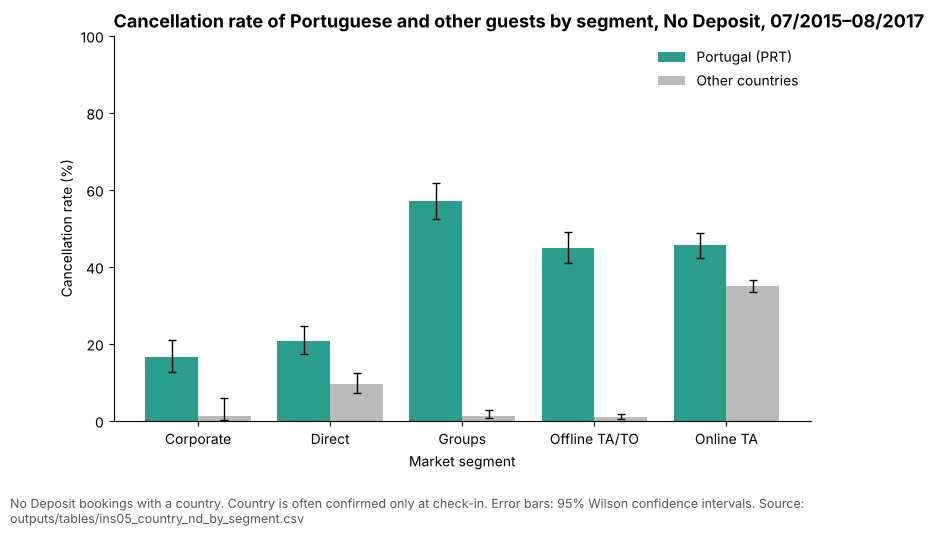

🖼️  outputs/figures/fig14_segment_by_lead.png


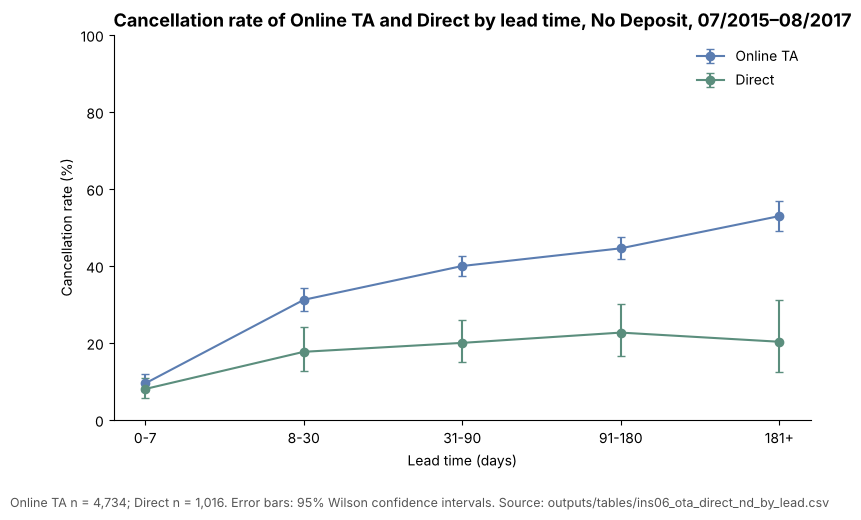

🖼️  outputs/figures/fig15_special_requests.png


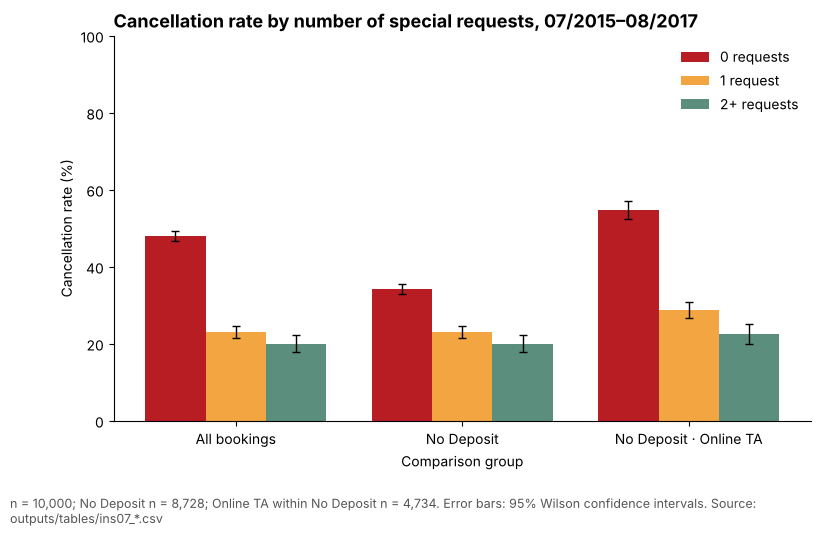

🖼️  outputs/figures/fig16_repeated_guest.png


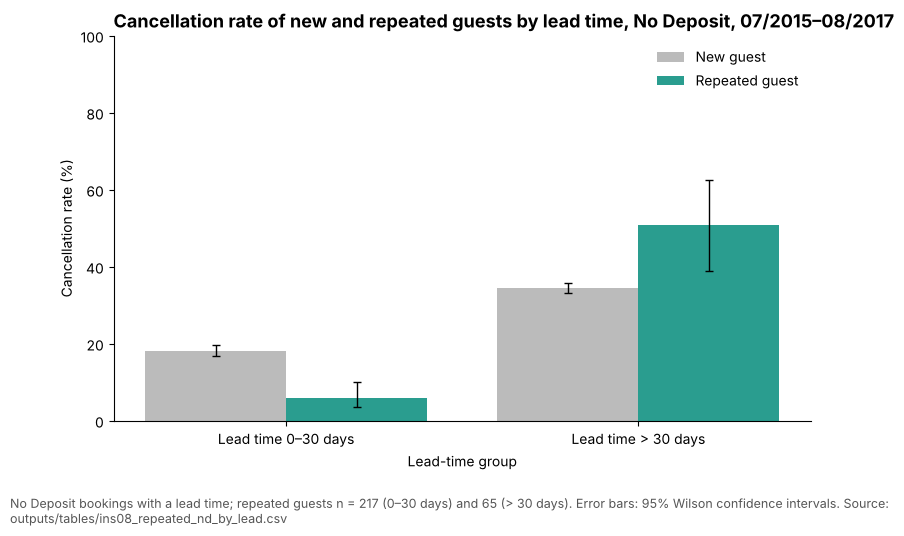

🖼️  outputs/figures/fig17_bookings_vs_roomnights_2016.png


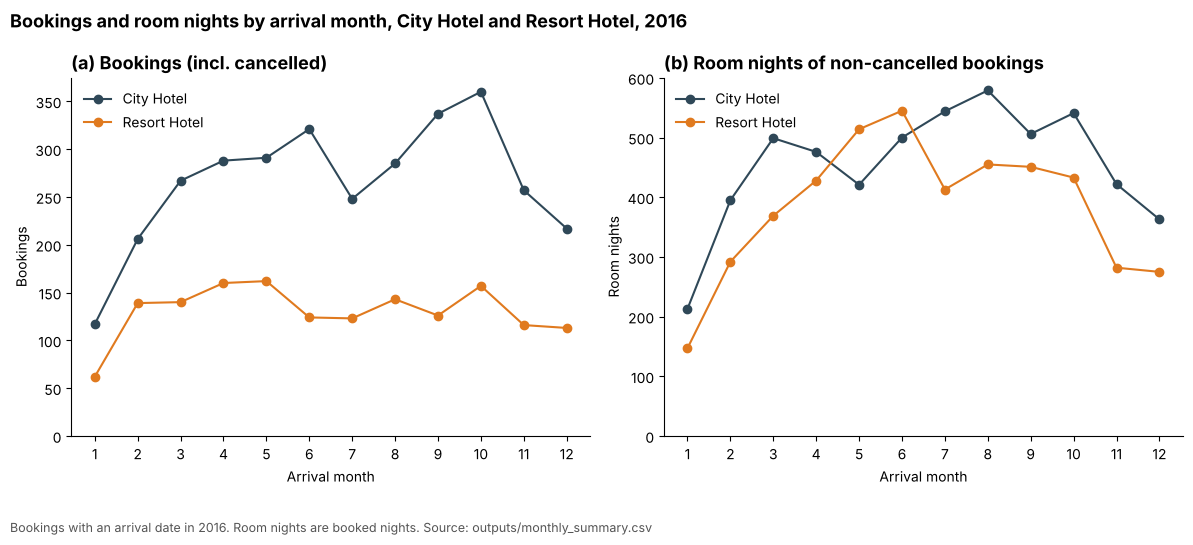

🖼️  outputs/figures/fig18_adr_month_2016.png


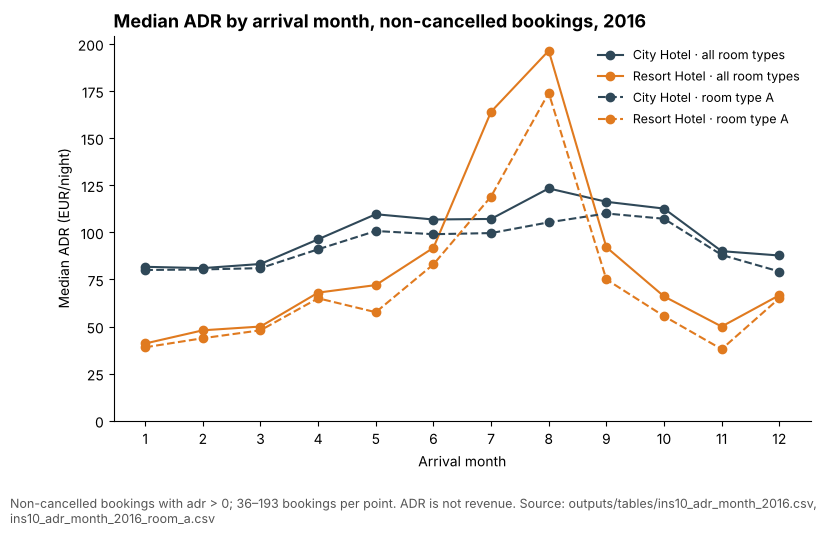

🖼️  outputs/figures/fig19_resort_7_nights.png


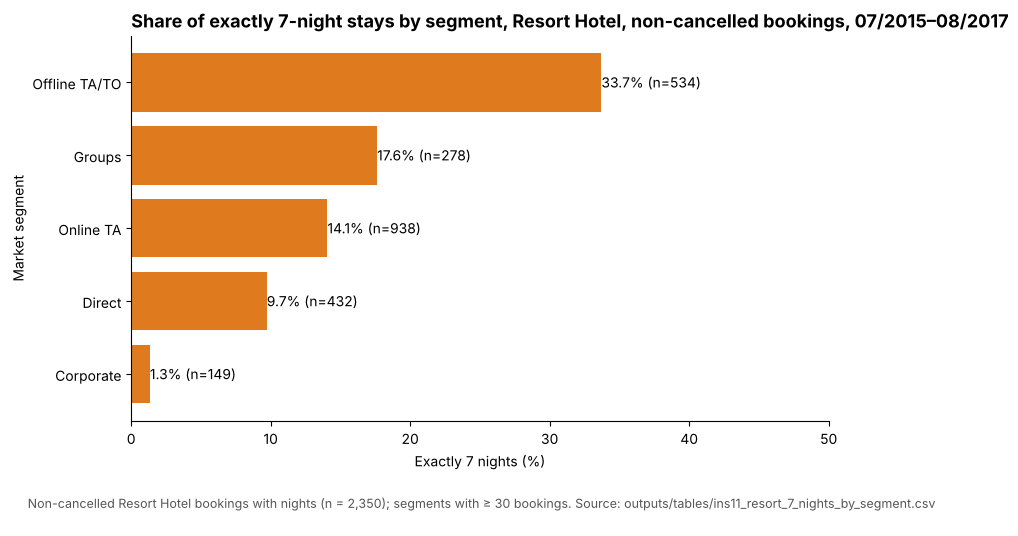

In [63]:
# ===== HÌNH BỔ SUNG CHO INSIGHT (fig09–fig19) =====
# fig09_room_change.png theo tên đề đặt sẵn ở Câu 10; các hình khác từ fig10 trở đi.
# Nhãn hình bằng tiếng Anh để dùng trực tiếp trong báo cáo.
import numpy as np

def save_extra_fig(fig, name):
    """Lưu PNG 150 dpi vào outputs/figures/ (hình bổ sung, ngoài 8 hình bắt buộc)."""
    fig.savefig(OUTPUT_DIR / 'figures' / f'{name}.png', dpi=150, bbox_inches='tight')
    print(f'🖼️  outputs/figures/{name}.png')

def ci_err(frame, rate='cancel_rate_pct'):
    """Sai số cho errorbar từ cột ci_low, ci_high."""
    return np.vstack([frame[rate] - frame['ci_low'], frame['ci_high'] - frame[rate]])

def grouped_bars(ax, frame, cat_col, group_col, groups, colors, rate='cancel_rate_pct', labels=None):
    """Cột nhóm có CI 95%; frame có sẵn cột rate, ci_low, ci_high."""
    cats = list(dict.fromkeys(frame[cat_col]))
    w = 0.8 / len(groups)
    for i, g in enumerate(groups):
        sub = frame[frame[group_col] == g].set_index(cat_col).reindex(cats)
        x = np.arange(len(cats)) + (i - (len(groups) - 1) / 2) * w
        ax.bar(x, sub[rate], width=w, color=colors[i], label=(labels or groups)[i],
               yerr=ci_err(sub, rate), capsize=3, error_kw={'lw': 1})
    ax.set_xticks(np.arange(len(cats)))
    ax.set_xticklabels(cats)
    ax.legend(frameon=False)

HC = [HOTEL_COLORS[h] for h in HOTELS]
CI_NOTE = 'Error bars: 95% Wilson confidence intervals.'

# fig09 · Insight 12: đổi phòng theo loại phòng đặt (nhóm ≥ 30 đặt phòng ở cả hai khách sạn)
r12 = ins['ins12_room_change_by_type']
keep = r12.groupby('reserved_room_type')['n_bookings'].transform('min').ge(30) & \
       r12.groupby('reserved_room_type')['hotel'].transform('nunique').eq(2)
fig, ax = plt.subplots(figsize=FIGSIZE)
grouped_bars(ax, r12[keep], 'reserved_room_type', 'hotel', HOTELS, HC, rate='changed_pct')
ax.set_ylim(0, None)
finish_chart(ax, 'Share of bookings assigned a different room type, by reserved type, 07/2015–08/2017',
             'Reserved room type', 'Room type changed (%)',
             note=f'Checked-out bookings with both room types (n = {len(co):,}); types with ≥ 30 bookings in each hotel. '
                  f'{CI_NOTE} Source: outputs/tables/ins12_room_change_by_type.csv')
save_extra_fig(fig, 'fig09_room_change'); plt.show()

# fig10 · Insight 1: tỷ lệ hủy theo khách sạn — tất cả, No Deposit, từng phân khúc (No Deposit)
r1 = pd.concat([
    ins['ins01_hotel_gap_by_deposit'].assign(group=lambda d: d['scope'].map({'all': 'All', 'no_deposit': 'No Deposit'})),
    ins['ins01_hotel_by_segment_nd'].assign(group=lambda d: 'ND · ' + d['market_segment'])], ignore_index=True)
fig, ax = plt.subplots(figsize=(11, 5))
grouped_bars(ax, r1, 'group', 'hotel', HOTELS, HC)
ax.set_ylim(0, 100); ax.tick_params(axis='x', labelsize=9)
finish_chart(ax, 'Cancellation rate by hotel: all bookings, No Deposit, and each segment within No Deposit, 07/2015–08/2017',
             'Comparison group (ND = No Deposit)', 'Cancellation rate (%)',
             note=f'n = 10,000 bookings; No Deposit n = 8,728. {CI_NOTE} '
                  'Source: outputs/tables/ins01_hotel_gap_by_deposit.csv, ins01_hotel_by_segment_nd.csv')
save_extra_fig(fig, 'fig10_hotel_cancel_by_segment'); plt.show()

# fig11 · Insight 2: tỷ lệ hủy theo lead time — tất cả, No Deposit theo khách sạn, Online TA (No Deposit)
lt_all = ins['ins02_leadtime_by_deposit']
series = [('All bookings', lt_all[lt_all['scope'] == 'all'], '#888888', '--'),
          ('No Deposit · City Hotel', ins['ins02_leadtime_nd_by_hotel'].query("hotel == 'City Hotel'"), HOTEL_COLORS['City Hotel'], '-'),
          ('No Deposit · Resort Hotel', ins['ins02_leadtime_nd_by_hotel'].query("hotel == 'Resort Hotel'"), HOTEL_COLORS['Resort Hotel'], '-'),
          ('No Deposit · Online TA', ins['ins02_leadtime_nd_online_ta'], '#5B7DB1', ':')]
fig, ax = plt.subplots(figsize=FIGSIZE)
for label, f, color, ls in series:
    f = f.set_index('lead_time_group').reindex(LEAD_GROUPS)
    ax.errorbar(LEAD_GROUPS, f['cancel_rate_pct'], yerr=ci_err(f), color=color, ls=ls, marker='o', capsize=3, label=label)
ax.set_ylim(0, 100); ax.legend(frameon=False)
finish_chart(ax, 'Cancellation rate by lead-time group, all bookings and within No Deposit, 07/2015–08/2017',
             'Lead time (days)', 'Cancellation rate (%)',
             note=f'n = 9,969 bookings with a lead time; No Deposit n = 8,701. Association only. {CI_NOTE} '
                  'Source: outputs/tables/ins02_*.csv')
save_extra_fig(fig, 'fig11_leadtime_by_deposit'); plt.show()

# fig12 · Insight 3–4: số ngày hủy trước ngày đến; tỷ lệ hủy theo lô
bins_d, labels_d = [-1, 7, 30, 90, 180, 10_000], ['0-7', '8-30', '31-90', '91-180', '181+']
dist = (cxl[cxl['deposit_type'].isin(['No Deposit', 'Non Refund'])]
        .assign(days_group=lambda d: pd.cut(d['days_before_arrival'], bins_d, labels=labels_d))
        .groupby('deposit_type')['days_group'].value_counts(normalize=True).mul(100)
        .unstack().reindex(columns=labels_d))
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 5), gridspec_kw={'width_ratios': [2, 1]})
x = np.arange(len(labels_d))
for i, (dep, color) in enumerate([('No Deposit', '#5B7DB1'), ('Non Refund', '#B81D24')]):
    a1.bar(x + (i - 0.5) * 0.4, dist.loc[dep], width=0.4, color=color, label=dep)
a1.set_xticks(x); a1.set_xticklabels(labels_d); a1.set_ylim(0, None); a1.legend(frameon=False)
finish_chart(a1, '(a) Days between cancellation and arrival', 'Days before arrival', 'Share of cancelled bookings (%)')
t3 = ins['ins03_cancel_timing'].query("hotel == 'Cả hai'")
a2.bar(t3['deposit_type'], t3['pct_in_batch_2plus'], color=['#5B7DB1', '#B81D24'])
a2.set_ylim(0, 100)
finish_chart(a2, '(b) Cancelled in a batch', 'Deposit type', 'Share of cancelled bookings (%)')
fig.suptitle('Timing of cancellations, No Deposit vs Non Refund, 07/2015–08/2017', fontsize=13, fontweight='bold', x=0.01, ha='left')
fig.text(0.01, -0.04, 'Cancelled bookings with arrival and cancellation dates (No Deposit n = 2,358; Non Refund n = 1,238). '
         'Batch: at least 2 bookings with the same hotel, arrival date and cancellation date. '
         'Source: outputs/tables/ins03_cancel_timing.csv', fontsize=9, color='#555555', ha='left', va='top', wrap=True)
fig.tight_layout(); save_extra_fig(fig, 'fig12_cancel_timing'); plt.show()

# fig13 · Insight 5: PRT so với nước khác theo phân khúc (No Deposit)
fig, ax = plt.subplots(figsize=FIGSIZE)
grouped_bars(ax, ins['ins05_country_nd_by_segment'], 'market_segment', 'country_group',
             ['PRT', 'Khác PRT'], ['#2A9D8F', '#BBBBBB'], labels=['Portugal (PRT)', 'Other countries'])
ax.set_ylim(0, 100)
finish_chart(ax, 'Cancellation rate of Portuguese and other guests by segment, No Deposit, 07/2015–08/2017',
             'Market segment', 'Cancellation rate (%)',
             note=f'No Deposit bookings with a country. Country is often confirmed only at check-in. '
                  f'{CI_NOTE} Source: outputs/tables/ins05_country_nd_by_segment.csv')
save_extra_fig(fig, 'fig13_country_by_segment'); plt.show()

# fig14 · Insight 6: Online TA so với Direct theo lead time (No Deposit)
fig, ax = plt.subplots(figsize=FIGSIZE)
for seg, color in [('Online TA', '#5B7DB1'), ('Direct', '#5B8E7D')]:
    f = ins['ins06_ota_direct_nd_by_lead'].query('market_segment == @seg').set_index('lead_time_group').reindex(LEAD_GROUPS)
    ax.errorbar(LEAD_GROUPS, f['cancel_rate_pct'], yerr=ci_err(f), color=color, marker='o', capsize=3, label=seg)
ax.set_ylim(0, 100); ax.legend(frameon=False)
finish_chart(ax, 'Cancellation rate of Online TA and Direct by lead time, No Deposit, 07/2015–08/2017',
             'Lead time (days)', 'Cancellation rate (%)',
             note=f'Online TA n = 4,734; Direct n = 1,016. {CI_NOTE} Source: outputs/tables/ins06_ota_direct_nd_by_lead.csv')
save_extra_fig(fig, 'fig14_segment_by_lead'); plt.show()

# fig15 · Insight 7: yêu cầu đặc biệt — tất cả, No Deposit, Online TA (No Deposit)
r7 = pd.concat([ins['ins07_special_requests'].query("scope in ['all', 'no_deposit']"),
                ins['ins07_requests_nd_online_ta']], ignore_index=True)
r7['scope'] = r7['scope'].map({'all': 'All bookings', 'no_deposit': 'No Deposit', 'no_deposit_online_ta': 'No Deposit · Online TA'})
fig, ax = plt.subplots(figsize=FIGSIZE)
grouped_bars(ax, r7, 'scope', 'requests_group', ['0', '1', '2+'], ['#B81D24', '#F2A541', '#5B8E7D'],
             labels=['0 requests', '1 request', '2+ requests'])
ax.set_ylim(0, 100)
finish_chart(ax, 'Cancellation rate by number of special requests, 07/2015–08/2017', 'Comparison group', 'Cancellation rate (%)',
             note=f'n = 10,000; No Deposit n = 8,728; Online TA within No Deposit n = 4,734. {CI_NOTE} '
                  'Source: outputs/tables/ins07_*.csv')
save_extra_fig(fig, 'fig15_special_requests'); plt.show()

# fig16 · Insight 8: khách quay lại theo lead time (No Deposit)
r8 = ins['ins08_repeated_nd_by_lead'].assign(guest=lambda d: d['is_repeated_guest'].map({0: 'New guest', 1: 'Repeated guest'}))
fig, ax = plt.subplots(figsize=FIGSIZE)
grouped_bars(ax, r8, 'lead_30', 'guest', ['New guest', 'Repeated guest'], ['#BBBBBB', '#2A9D8F'])
ax.set_ylim(0, 100); ax.set_xticklabels(['Lead time 0–30 days', 'Lead time > 30 days'])
finish_chart(ax, 'Cancellation rate of new and repeated guests by lead time, No Deposit, 07/2015–08/2017',
             'Lead-time group', 'Cancellation rate (%)',
             note=f'No Deposit bookings with a lead time; repeated guests n = 217 (0–30 days) and 65 (> 30 days). {CI_NOTE} '
                  'Source: outputs/tables/ins08_repeated_nd_by_lead.csv')
save_extra_fig(fig, 'fig16_repeated_guest'); plt.show()

# fig17 · Insight 9: số đặt phòng và đêm phòng (đặt phòng không hủy) theo tháng, 2016
m16 = monthly_summary[monthly_summary['arrival_year'] == 2016]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 5))
for h in HOTELS:
    f = m16[m16['hotel'] == h].set_index('arrival_month').reindex(range(1, 13))
    a1.plot(f.index, f['n_bookings'], marker='o', color=HOTEL_COLORS[h], label=h)
    a2.plot(f.index, f['room_nights'], marker='o', color=HOTEL_COLORS[h], label=h)
for a, t, y in [(a1, '(a) Bookings (incl. cancelled)', 'Bookings'), (a2, '(b) Room nights of non-cancelled bookings', 'Room nights')]:
    a.set_xticks(range(1, 13)); a.set_ylim(0, None); a.legend(frameon=False)
    finish_chart(a, t, 'Arrival month', y)
fig.suptitle('Bookings and room nights by arrival month, City Hotel and Resort Hotel, 2016', fontsize=13, fontweight='bold', x=0.01, ha='left')
fig.text(0.01, -0.04, 'Bookings with an arrival date in 2016. Room nights are booked nights. Source: outputs/monthly_summary.csv',
         fontsize=9, color='#555555', ha='left', va='top', wrap=True)
fig.tight_layout(); save_extra_fig(fig, 'fig17_bookings_vs_roomnights_2016'); plt.show()

# fig18 · Insight 10: trung vị ADR theo tháng 2016 — mọi loại phòng và riêng loại A
fig, ax = plt.subplots(figsize=FIGSIZE)
for key, ls, suffix in [('ins10_adr_month_2016', '-', 'all room types'), ('ins10_adr_month_2016_room_a', '--', 'room type A')]:
    for h in HOTELS:
        f = ins[key].query('hotel == @h').set_index('arrival_month').reindex(range(1, 13))
        ax.plot(f.index, f['median'], ls=ls, marker='o', color=HOTEL_COLORS[h], label=f'{h} · {suffix}')
ax.set_xticks(range(1, 13)); ax.set_ylim(0, None); ax.legend(frameon=False, fontsize=9)
finish_chart(ax, 'Median ADR by arrival month, non-cancelled bookings, 2016', 'Arrival month', 'Median ADR (EUR/night)',
             note='Non-cancelled bookings with adr > 0; 36–193 bookings per point. ADR is not revenue. '
                  'Source: outputs/tables/ins10_adr_month_2016.csv, ins10_adr_month_2016_room_a.csv')
save_extra_fig(fig, 'fig18_adr_month_2016'); plt.show()

# fig19 · Insight 11: tỷ lệ lưu trú đúng 7 đêm ở Resort Hotel theo phân khúc
r11 = ins['ins11_resort_7_nights_by_segment'].query('n_stays >= 30').sort_values('pct_7_nights')
fig, ax = plt.subplots(figsize=FIGSIZE)
bars = ax.barh(r11['market_segment'], r11['pct_7_nights'], color=HOTEL_COLORS['Resort Hotel'])
ax.bar_label(bars, labels=[f'{p:.1f}% (n={n:,})' for p, n in zip(r11['pct_7_nights'], r11['n_stays'])])
ax.set_xlim(0, 50)
finish_chart(ax, 'Share of exactly 7-night stays by segment, Resort Hotel, non-cancelled bookings, 07/2015–08/2017',
             'Exactly 7 nights (%)', 'Market segment',
             note='Non-cancelled Resort Hotel bookings with nights (n = 2,350); segments with ≥ 30 bookings. '
                  'Source: outputs/tables/ins11_resort_7_nights_by_segment.csv')
save_extra_fig(fig, 'fig19_resort_7_nights'); plt.show()


In [64]:
check('Đã lưu bảng nguồn insight', lambda: len(list((OUTPUT_DIR / 'tables').glob('ins*.csv'))) == len(ins))
check('Đã lưu 11 hình bổ sung fig09–fig19',
      lambda: len([p for p in (OUTPUT_DIR / 'figures').glob('fig*.png') if 9 <= int(p.name[3:5]) <= 19]) == 11)

✅ Đã lưu bảng nguồn insight
✅ Đã lưu 11 hình bổ sung fig09–fig19


True

---
# INSIGHT CÓ BẰNG CHỨNG (13 insight)

Đề yêu cầu tối thiểu 6 insight từ ít nhất 4 chủ đề, mỗi insight 80–120 từ. Nhóm trình bày 13 insight từ 10 chủ đề. Mọi tỷ lệ kèm mẫu số và khoảng tin cậy 95% Wilson. Mỗi phát hiện về hủy phòng được xem lại trong nhóm No Deposit và theo các biến liên quan (khách sạn, phân khúc, lead time); đây là so sánh mô tả, không kết luận nhân quả.

| # | Chủ đề | Câu/Bảng/Hình làm bằng chứng | Phát hiện chính (1 câu) |
|---|---|---|---|
| 1 | Khách sạn | Câu 2, Hình 1, Hình 10 | Hủy nhiều hơn; trong cùng loại cọc và phân khúc, tỷ lệ của hai khách sạn gần nhau |
| 2 | Lead time | Câu 4, Hình 3, Hình 11 | Tỷ lệ hủy tăng theo lead time; vẫn giữ trong cùng loại cọc, khách sạn, phân khúc |
| 3 | Thời điểm hủy | Hình 12 | Gần một nửa số lần hủy (No Deposit) diễn ra trong 30 ngày trước ngày đến |
| 4 | Đặt cọc Non Refund | Câu 7, Hình 6, Hình 12 | Non Refund gần như luôn bị hủy, tập trung ở vài nhóm, hủy sớm và theo lô |
| 5 | Quốc gia | Câu 5, Hình 4, Hình 13 | PRT hủy nhiều hơn ở mọi khách sạn, phân khúc; một số mức chênh bất thường |
| 6 | Phân khúc | Câu 6, Hình 5, Hình 14 | Trong No Deposit, Online TA hủy nhiều nhất; khoảng cách với Direct lớn dần theo lead time |
| 7 | Yêu cầu đặc biệt | Hình 15 | Không có yêu cầu đặc biệt thì hủy nhiều hơn, kể cả trong cùng loại cọc và phân khúc |
| 8 | Khách quay lại | Hình 16 | Khách quay lại hủy ít hơn khi đặt sát ngày, nhiều hơn khi đặt trước trên 30 ngày |
| 9 | Mùa vụ | Câu 3, Hình 2, Hình 17 | Tháng cao điểm đổi khi đo bằng đêm phòng thay vì số đặt phòng |
| 10 | Giá phòng (ADR) | Câu 8, Hình 7, Hình 18 | Giá Resort Hotel dao động theo tháng mạnh hơn, vượt City Hotel vào tháng 7–8 |
| 11 | Lưu trú | Câu 9, Hình 8, Hình 19 | City Hotel lưu trú ngắn; Resort Hotel có nhóm lớn đúng 7 đêm, nhất là Offline TA/TO |
| 12 | Đổi phòng | Câu 10, Hình 9 | Chênh lệch đổi phòng giữa hai khách sạn nằm ở phòng loại A |
| 13 | Giá trị hiếm | Câu 8, 9, bảng ins13 | adr = 0 và 0 đêm tập trung ở Complementary và khách quay lại |

**Tự kiểm tra:** ☑ số liệu + mẫu số · ☑ so sánh · ☑ phạm vi 2 khách sạn của mẫu · ☑ giới hạn · ☑ bảng/hình · ☑ không dùng từ nhân quả.

### A. Hủy phòng

**Insight 1 · Khách sạn**

> **Phát hiện:** City Hotel bị hủy nhiều hơn Resort Hotel, nhưng trong cùng loại đặt cọc và cùng phân khúc, tỷ lệ hủy của hai khách sạn gần nhau. **Số liệu:** City Hotel hủy 41,79% (n = 6.702), Resort Hotel 28,50% (n = 3.298), chênh 13,29 điểm. **So sánh:** Non Refund chiếm 16,50% so với 4,64%; trong No Deposit, chênh còn 5,09 điểm, tỷ trọng Online TA 58,72% so với 46,28%. Trong No Deposit, ở cả 5 phân khúc chính, khoảng tin cậy đều chồng nhau (Online TA: 37,68% so với 35,08%; chênh lớn nhất ở Groups: 31,27% so với 22,83%). **Giới hạn:** chỉ là mô tả; không có lý do hủy. *Nguồn: Câu 2, Hình 1, `ins01_hotel_gap_by_deposit.csv`, `ins01_segment_mix_nd.csv`, `ins01_hotel_by_segment_nd.csv`*

**Insight 2 · Lead time**

> **Phát hiện:** Tỷ lệ hủy tăng đều theo lead time, và xu hướng vẫn giữ trong cùng loại đặt cọc, khách sạn và phân khúc. **Số liệu:** trên 9.969 đặt phòng có lead time (loại 31 thiếu), tỷ lệ hủy tăng từ 10,06% (0–7 ngày, n = 1.581) lên 58,06% (181+ ngày, n = 2.065). **So sánh:** tỷ trọng Non Refund cũng tăng, từ 0,89% lên 31,33%. Trong No Deposit, tỷ lệ tăng từ 9,38% lên 39,05%; ở City Hotel 11,59% lên 41,67%, Resort Hotel 6,49% lên 35,11%, Online TA 9,47% lên 52,93%. **Giới hạn:** liên hệ quan sát; không cho biết vì sao đặt sớm bị hủy nhiều hơn. *Nguồn: Câu 4, Hình 3, `ins02_leadtime_by_deposit.csv`, `ins02_leadtime_nd_by_hotel.csv`, `ins02_leadtime_nd_online_ta.csv`*

**Insight 3 · Thời điểm hủy**

> **Phát hiện:** Với đặt phòng không đặt cọc, gần một nửa số lần hủy diễn ra trong 30 ngày trước ngày đến. **Số liệu:** trong 2.358 đặt phòng No Deposit có trạng thái Canceled và đủ hai ngày, trung vị hủy trước ngày đến là 37 ngày; 44,91% hủy trong vòng 30 ngày, 16,50% trong vòng 7 ngày, 80 đặt phòng hủy đúng ngày đến. **So sánh:** City Hotel hủy sát ngày hơn Resort Hotel (trung vị 35 so với 41 ngày; 46,49% so với 41,60% trong vòng 30 ngày). **Giới hạn:** ngày hủy lấy từ reservation_status_date theo từ điển dữ liệu; không tính 105 No-Show (đều ghi đúng ngày đến). *Nguồn: `ins03_cancel_timing.csv`, `ins03_no_show_dates.csv`*

**Insight 4 · Đặt cọc Non Refund**

> **Phát hiện:** Đặt phòng Non Refund gần như luôn bị hủy, tập trung ở vài nhóm, thường hủy sớm và theo lô. **Số liệu:** 1.247/1.259 bị hủy (99,05%); 1.106 thuộc City Hotel, 1.221 là khách PRT, 813 thuộc Groups; lead time trung bình 212,6 ngày so với 89,3 ngày ở No Deposit. **So sánh:** 88,13% đặt phòng Non Refund đã hủy thuộc một lô (từ 2 đặt phòng cùng khách sạn, ngày đến, ngày hủy), so với 15,95% ở No Deposit; trung vị hủy trước ngày đến 102 so với 37 ngày. **Giới hạn:** không có mã đoàn hay lý do hủy; cần kiểm chứng cách ghi nhận đặt cọc. *Nguồn: Câu 7, Hình 6, `ins03_cancel_timing.csv`, `ins04_non_refund_profile.csv`*

**Insight 5 · Quốc gia**

> **Phát hiện:** Khách PRT bị hủy nhiều hơn khách nước ngoài ở mọi khách sạn và phân khúc, nhưng một số mức chênh bất thường. **Số liệu:** PRT hủy 57,68% (n = 4.005), nước khác 23,88% (n = 5.888); 30,49% đặt phòng PRT là Non Refund, so với 0,54%. **So sánh:** trong No Deposit, PRT vẫn cao hơn ở City Hotel (39,30% so với 27,15%) và Resort Hotel (39,21% so với 15,36%). Riêng Groups và Offline TA/TO, khách nước ngoài chỉ hủy 1,31% và 0,99%, so với 57,18% và 44,91% ở PRT. **Giới hạn:** quốc gia thường chỉ được xác nhận khi nhận phòng (Mục 5.4 của đề), nên cần thận trọng. *Nguồn: Câu 5, Hình 4, `ins05_country_by_deposit.csv`, `ins05_country_nd_by_hotel.csv`, `ins05_country_nd_by_segment.csv`*

**Insight 6 · Phân khúc**

> **Phát hiện:** Groups hủy nhiều nhất khi tính chung, nhưng trong No Deposit, Online TA hủy nhiều nhất; khoảng cách với Direct lớn dần theo lead time. **Số liệu:** Groups hủy 61,89% (n = 1.703), 47,74% là Non Refund; trong No Deposit còn 27,95% (n = 880). Online TA giữ 36,88% (n = 4.734), Direct 14,96% (n = 1.016), ở cả hai khách sạn. **So sánh:** trung vị lead time của Online TA là 59 ngày, Direct 16 ngày. Trong No Deposit, nhóm 0–7 ngày chưa phân biệt được hai phân khúc (9,47% và 8,02%); nhóm 181+ ngày là 52,93% so với 20,29%. **Giới hạn:** không có điều kiện hủy của từng kênh. *Nguồn: Câu 6, Hình 5, `ins06_segment_by_deposit.csv`, `ins06_ota_direct_nd_by_lead.csv`*

**Insight 7 · Yêu cầu đặc biệt**

> **Phát hiện:** Đặt phòng không có yêu cầu đặc biệt hủy nhiều hơn; khoảng cách vẫn còn trong cùng loại đặt cọc và cùng phân khúc. **Số liệu:** 48,05% của 5.909 đặt phòng không có yêu cầu bị hủy, so với 19,98% (n = 1.331) khi có từ 2 yêu cầu. **So sánh:** 21,27% đặt phòng không có yêu cầu là Non Refund, gần 0% ở nhóm có yêu cầu. Trong No Deposit còn chênh 14,33 điểm; riêng Online TA là 54,73% so với 22,42%. Ở Resort Hotel (No Deposit) chưa phân biệt được (26,87% và 21,37%). **Giới hạn:** liên hệ quan sát; không biết yêu cầu được ghi lúc đặt hay sát ngày đến. *Nguồn: `ins07_special_requests.csv`, `ins07_requests_nd_online_ta.csv`*

**Insight 8 · Khách quay lại**

> **Phát hiện:** Khách quay lại hủy ít hơn khách mới khi đặt sát ngày, nhưng hủy nhiều hơn khi đặt trước trên 30 ngày. **Số liệu:** tính chung, khách quay lại hủy 19,39% (n = 294), khách mới 37,96% (n = 9.706). **So sánh:** trong No Deposit, 76,95% đặt phòng của khách quay lại có lead time 0–30 ngày, so với 33,73% ở khách mới. Ở nhóm 0–30 ngày, khách quay lại hủy 5,99% (n = 217) so với 18,10%; trên 30 ngày là 50,77% (n = 65) so với 34,45%; cả hai cặp có khoảng tin cậy không chồng nhau. **Giới hạn:** nhóm khách quay lại nhỏ; cờ không cho biết số lần đã ở. *Nguồn: `ins08_repeated_nd_by_lead.csv`, `ins08_lead_share_nd.csv`*

### B. Mùa vụ, giá và lưu trú (chỉ đặt phòng không hủy)

**Insight 9 · Mùa vụ**

> **Phát hiện:** Năm 2016, tháng cao điểm đổi khi đo bằng đêm phòng của đặt phòng không hủy thay vì số đặt phòng. **Số liệu:** Resort Hotel nhiều đặt phòng nhất tháng 5 (162), nhiều đêm phòng nhất tháng 6 (545); City Hotel là tháng 10 (360) và tháng 8 (579). **So sánh:** Resort Hotel: lưu trú tháng 6 dài trung bình 5,92 đêm, tháng 5 là 4,39 đêm. City Hotel: tháng 10 hủy 45,83%, tháng 8 hủy 34,39%; bỏ đặt phòng hủy còn 195 và 187 đặt phòng, và lưu trú tháng 8 dài hơn (3,10 so với 2,77 đêm). **Giới hạn:** đây là số đêm đã đặt, không phải công suất. *Nguồn: Câu 3, Hình 2, `monthly_summary.csv`*

**Insight 10 · Giá phòng (ADR)**

> **Phát hiện:** Tính cả kỳ, trung vị giá/đêm của City Hotel cao hơn, nhưng giá Resort Hotel dao động theo tháng mạnh hơn và vượt City Hotel vào tháng 7–8, kể cả khi chỉ xét phòng loại A. **Số liệu:** trên đặt phòng không hủy có adr > 0 (City Hotel 3.828, Resort Hotel 2.293; loại 120 adr = 0), trung vị là 100,65 và 75,00 EUR. **So sánh:** năm 2016, trung vị Resort Hotel tăng từ 41,0 EUR tháng 1 lên 196,4 EUR tháng 8; City Hotel chỉ 81,0–123,3 EUR. Riêng loại A, Resort Hotel từ 39,0 lên 174,0 EUR. **Giới hạn:** ADR không phải doanh thu; mẫu từng tháng nhỏ (36–193). *Nguồn: Câu 8, Hình 7, `ins10_adr_month_2016.csv`, `ins10_adr_month_2016_room_a.csv`*

**Insight 11 · Lưu trú**

> **Phát hiện:** City Hotel chủ yếu lưu trú ngắn, còn Resort Hotel có nhóm lớn đặt đúng một tuần, nhất là ở Offline TA/TO. **Số liệu:** trên 6.234 đặt phòng không hủy có số đêm (loại 25 thiếu), 70,29% đặt phòng City Hotel là 1–3 đêm, so với 50,72% ở Resort Hotel. **So sánh:** 17,28% đặt phòng Resort Hotel là đúng 7 đêm, so với 2,75% ở City Hotel; riêng Offline TA/TO của Resort Hotel là 33,71% (n = 534). Trung vị ước tính tiền phòng mỗi đặt phòng gần bằng nhau (256 và 261 EUR). **Giới hạn:** số đêm đã đặt; ước tính tiền phòng không phải doanh thu. *Nguồn: Câu 9, Hình 8, `ins11_stay_revenue.csv`, `ins11_resort_7_nights_by_segment.csv`*

### C. Vận hành và dữ liệu

**Insight 12 · Đổi phòng**

> **Phát hiện:** Resort Hotel có tỷ lệ đặt phòng được xếp khác loại đã đặt cao hơn City Hotel; chênh lệch nằm ở phòng loại A. **Số liệu:** trên 6.242 đặt phòng Check-Out có đủ hai loại phòng, Resort Hotel đổi 24,80%, City Hotel 14,42%. **So sánh:** loại A: 35,96% so với 15,85%; các loại khác gộp chung chưa phân biệt được (10,14% và 9,90%). Với loại A ở Resort Hotel, tỷ lệ đổi là 40,66% ngoài tháng 6–9 (n = 937), 24,43% trong tháng 6–9 (n = 393); 262/477 lần đổi sang loại D. **Giới hạn:** không có lý do đổi phòng; mã loại phòng đã ẩn danh. *Nguồn: Câu 10, Hình 9, `ins12_room_change_a_vs_other.csv`, `ins12_resort_room_a_by_period.csv`*

**Insight 13 · Giá trị hiếm**

> **Phát hiện:** Giá trị hiếm adr = 0 và lưu trú 0 đêm không rải đều mà tập trung ở một số nhóm cụ thể. **Số liệu:** trong 120 đặt phòng không hủy có adr = 0, 48 thuộc Complementary và 37 ghi 0 đêm. **So sánh:** 48/51 đặt phòng Complementary không hủy có adr = 0; cả 37 đặt phòng 0 đêm không hủy đều có adr = 0; khách quay lại chiếm 24,17% nhóm adr = 0, so với 3,79% mọi đặt phòng không hủy. **Giới hạn:** dữ liệu không cho biết vì sao giá bằng 0; nhóm này được giữ trong bảng sạch và tách riêng khi tính ADR. *Nguồn: Câu 8, 9, `ins13_rare_values.csv`*

**Giới hạn chung:**

1. Dữ liệu là mẫu ngẫu nhiên từ bộ gốc 119.390 đặt phòng của hai khách sạn ở Bồ Đào Nha, ngày đến 07/2015–08/2017, đã thêm lỗi có chủ đích. Số đếm là của mẫu và không đại diện cho ngành khách sạn.
2. Mọi kết quả là liên hệ quan sát. Dữ liệu không có lý do hủy, chính sách giá, chi phí, doanh thu thực hay đánh giá của khách; ADR và revenue_est không phải doanh thu.
3. Các biến tập trung cùng nhau (Non Refund, PRT, Groups, City Hotel, lead time dài). So sánh trong cùng nhóm chỉ là mô tả, không tách được tác động riêng của từng biến.
4. Chỉ năm 2016 đủ 12 tháng. Quốc gia của đặt phòng hủy có thể kém chính xác; mã CN giữ nguyên, không gộp với CHN.
5. Giá trị không sửa được đã để thiếu (49 thiếu ngày đến, 107 thiếu quốc gia, 31 thiếu lead time, 36 thiếu adr); 15 đặt phòng có xung đột được xử lý theo row_id nhỏ nhất.
6. Khoảng tin cậy chỉ phản ánh dao động do lấy mẫu, không phản ánh sai số ghi nhận dữ liệu.

**Hướng bổ sung dữ liệu và câu hỏi tiếp theo:**

1. Thu thập lý do hủy, mã đoàn hoặc khối đặt phòng, và cách ghi nhận đặt cọc, để kiểm chứng tỷ lệ hủy 99% và các lô hủy của Non Refund (Insight 4) cũng như mức chênh bất thường theo quốc gia (Insight 5).
2. Thu thập giá niêm yết theo loại phòng và mùa, và công suất phòng theo ngày, để mô tả rõ hơn biến động ADR (Insight 10) và đổi phòng (Insight 12).
3. Câu hỏi mô tả tiếp theo: tỷ lệ hủy theo kênh phân phối × loại đặt cọc × khách sạn; khoảng thời gian từ lúc đặt đến lúc hủy.

---
# GIAI ĐOẠN E · XUẤT DỮ LIỆU VÀ TỰ KIỂM TRA TRƯỚC KHI NỘP

1. Chạy ô xuất bên dưới.
2. **Restart & Run all** — mọi ô phải chạy không lỗi, số thứ tự ô liên tục 1, 2, 3…
3. Xem bảng tiến độ: mục tiêu 100%.
4. (Khuyến nghị) Chạy `python tools/kiem_tra_nop_bai.py <thư mục bài nộp>` trên thư mục đã sắp xếp theo Mục 12 của đề.

In [65]:
outputs = {
    'bookings_clean.csv': clean_df,
    'monthly_summary.csv': monthly_summary,
    'cleaning_log.csv': cleaning_log,
    'row_lineage.csv': row_lineage,
    'quality_report.csv': quality_report,
}
for filename, frame in outputs.items():
    if frame is None:
        print(f'⏳ CHƯA XUẤT {filename}: biến còn None.')
    else:
        frame.to_csv(OUTPUT_DIR / filename, index=False, encoding='utf-8-sig')
        print(f'💾 outputs/{filename}  ({len(frame)} dòng)')

💾 outputs/bookings_clean.csv  (10000 dòng)
💾 outputs/monthly_summary.csv  (52 dòng)
💾 outputs/cleaning_log.csv  (55 dòng)
💾 outputs/row_lineage.csv  (10325 dòng)
💾 outputs/quality_report.csv  (53 dòng)


In [66]:
show_progress()

Tiến độ tệp đầu ra: 27/27 (100%)


,Nhóm,Tệp,Có
0,Dữ liệu,bookings_clean.csv,✅
1,Dữ liệu,monthly_summary.csv,✅
2,Dữ liệu,cleaning_log.csv,✅
3,Dữ liệu,row_lineage.csv,✅
4,Dữ liệu,quality_report.csv,✅
5,Bảng,a_missing_survey.csv,✅
6,Bảng,a_issue_catalog.csv,✅
7,Bảng,q01_before_after.csv,✅
8,Bảng,q02_hotel_cancel.csv,✅
9,Bảng,q03_monthly_arrivals_2016.csv,✅


In [67]:
# (Tùy chọn, Colab) Nén outputs để tải về
import shutil
archive = shutil.make_archive('outputs_backup', 'zip', OUTPUT_DIR)
print('Đã tạo', archive, '— tải về từ bảng Files.')

Đã tạo /home/claude/run/outputs_backup.zip — tải về từ bảng Files.
